In [ ]:
# !pip install torch==2.3.0 torchvision==0.18.0 torchaudio==2.3.0 --index-url https://download.pytorch.org/whl/cu121
# !pip install  dgl -f https://data.dgl.ai/wheels/torch-2.3/cu121/repo.html
# !pip install seaborn

Versión de DGL: 2.4.0+cu121
Versión de PyTorch: 2.3.0+cu121


## Setings

In [1]:
# Reload modulos automaticamente
%load_ext autoreload
%autoreload 2

from modules.gnn_models import GCN, GraphSAGE, GAT
from modules.graph import Graph, create_files
from modules.gnn import GNN
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.metrics import roc_auc_score
import torch.nn.functional as F
import numpy as np

# from modules.gnn import GNN
# from modules.models import  ModelGraphSAGE, GraphSAGE, GCN, ModelGCN, ModelSAGESample #ModelGraphSAGE,GraphSAGE, GCN,ModelSAGESample,SAGE, ModelGCN
# from modules.predictors import DotPredictor, MLPPredictor, MLPPredictorEmbeddings
# from modules.graph_from_api import Graph_API
# from dgl.sampling import pack_traces

# import torch.nn.functional as F
# from torch.optim import Adam
# from torch.optim import SparseAdam
import itertools
import dgl
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.metrics import (
    confusion_matrix,              # ya lo estabas usando
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)
# from utils import *
# from modules.graph import Graph
# import numpy as np
import os
# import fnmatch
# import tqdm
# import networkx as nx

# import dgl.function as fn
# from dgl.nn import DeepWalk
# from torch.utils.data import DataLoader

# from sklearn.linear_model import LogisticRegression
# from gensim.models import Word2Vec
# from sklearn.model_selection import train_test_split
# from bgp2vec.bgp2vec import BGP2VEC


print("Versión de DGL:", dgl.__version__)
print("Versión de PyTorch:", torch.__version__)

/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Versión de DGL: 2.4.0+cu121
Versión de PyTorch: 2.3.0+cu121


In [2]:
TOR_LABELS_DICT = {'P2P':0, 'C2P': 1,'P2C': 2}



In [3]:
# Definimos las rutas de los archivos
BASE_PROJECT_PATH = os.getcwd() + "/data/"
RELATIONSHIPS_FILE  = BASE_PROJECT_PATH + "CAIDA_AS_Relationships/Serial_1/20220701.as-rel.txt.bz2"
FEATURES_FILE = BASE_PROJECT_PATH + "/node_feature_mio.csv" #"/node_features.csv" 
rib_path = BASE_PROJECT_PATH + 'sanitized_rib.txt'
MES = 'febrero'
dataset_graph_path = BASE_PROJECT_PATH + f'dgl_graph/{MES}/'
MAX_NUM_ROUTES = 1000000

In [4]:
def plot_confusion_matrix(cm,
                          classes,
                          normalize=False,
                          title='Matriz de confusión',
                          fname=None,
                          cmap=plt.cm.Blues,
                          save=False):
    """
    Esta función imprime y grafica la matriz de confusión.
    La normalización puede aplicarse configurando `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Matriz de confusión normalizada")
    else:
        print('Matriz de confusión sin normalizar')

    plt.figure(figsize=(6, 5))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, format(cm[i, j], fmt),
                     ha="center", va="center",
                     color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('Etiqueta real')
    plt.xlabel('Etiqueta predicha')
    plt.tight_layout()
    
    if save and fname is not None:
        plt.savefig(f"{fname}.png", dpi=300, bbox_inches='tight')
    plt.show()

def plot_confusion_matrix_2(cm,
                            classes,
                            normalize=False,
                            title='Matriz de confusión',
                            fname=None,
                            cmap=plt.cm.Blues,
                            save=False):
    """
    Dibuja la matriz de confusión.
    Si `normalize=True`, muestra los valores en **porcentaje (%)**.
    """
    if normalize:
        cm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100  # → %
        print("Matriz de confusión normalizada (%)")
        fmt  = ".1f"   # un decimal
        suffix = "%"   # añade símbolo %
    else:
        print("Matriz de confusión sin normalizar")
        fmt  = "d"
        suffix = ""

    plt.figure(figsize=(6, 5))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title); plt.colorbar()
    ticks = np.arange(len(classes))
    plt.xticks(ticks, classes, rotation=45)
    plt.yticks(ticks, classes)

    thresh = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i,
                     f"{format(cm[i, j], fmt)}{suffix}",
                     ha="center", va="center",
                     color="white" if cm[i, j] > thresh else "black")

    plt.ylabel("Etiqueta real")
    plt.xlabel("Etiqueta predicha")
    plt.tight_layout()

    # if save and fname:
        # plt.savefig(f"{fname}.png", dpi=300, bbox_inches="tight")
    plt.show()



## Creacion Grafo 
Creamos un grafo nx y dgl, ademas de los archivos edges.csv y nodes.csv a partir de archivos ribs previamente creados o de archivo CAIDA AS Relationships.

Crear esos archivos una unica vez con create_graph() una ves ya creados los archivos edges.csv y nodes.csv puedo ocupar directamente la funcion 

Se le puede indicar el maximo de bgp paths que se quiere (hehco para cuando se leen ribs no de caida) 

### CASO 1: RIBs
* Creacion de grafo a partir de paths recolectados de las RIBs por BGPStream
* Por ahora le asignamos a todos los nodos embeddings iniciales de de dimension 32 parte con puros 1s todos


In [ ]:
ls /media/valentina/KINGSTON/TESIS/data/RIBs/sanitized_rib_febrero_2024

rib_abril_2024.txt*            sanitized_rib_enero_2024.txt*
rib_enero_2024.txt*            sanitized_rib_febrero_2024.txt*
rib_marzo_2024.txt*            sanitized_rib_marzo_2024.txt*
sanitized_rib_abril_2024.txt*


In [5]:
# Informacion del analisis para la configuracion
MES = 'febrero'
ANO = '2024'

In [6]:
# Ruta a la data base del proyecto
BASE_PROJECT_PATH = os.getcwd() + "/data/"

# Ruta memoria externa con los datos
DATA_PATH = '/media/valentina/KINGSTON/TESIS/data/'

# Archivo etiqueta las relaciones
LABEL_EDGES_FILE = 'data/' + 'CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2'

# Archivo con RIBs
RIB_FILE = DATA_PATH + f'RIBs/sanitized_rib_{MES}_{ANO}.txt'

# Ruta donde se guardaran los grafo DGL
OUTPUT_DIR = BASE_PROJECT_PATH +  f'dgl_graph/{MES}/'

In [7]:
# Ruta a la data base del proyecto
BASE_PROJECT_PATH = os.getcwd() + "/data/"

# Ruta memoria externa con los datos
DATA_PATH = '/media/valentina/KINGSTON/TESIS/data/'

# Archivo etiqueta las relaciones
LABEL_EDGES_FILE = DATA_PATH + 'CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2'

# Archivo con RIBs
RIB_FILE = DATA_PATH + f'RIBs/sanitized_rib_{MES}_{ANO}.txt'

# Ruta donde se guardaran los grafo DGL
OUTPUT_DIR = BASE_PROJECT_PATH +  f'dgl_graph/{MES}/'
# Definimos las listas de features

# features_file = 'node_degrees' #'' # 'node_degrees' # las features que se le agregaran seran 
# features_file = base_path + "/node_features.csv"
FEATURES_FILE = BASE_PROJECT_PATH + "/node_features_mio_febrero.csv"
# FEATURES_FILE = 'node_features_mio_febrero.csv'
attr = 'node_features_mio_febrero.csv' # 'mio_attr' # 'degree' # 'node_features_mio_febrero.csv'
rib_path = BASE_PROJECT_PATH + 'sanitized_rib_febrero_2024.txt'
MAX_NUM_ROUTES = 1000000
label_edges_file = BASE_PROJECT_PATH + 'edges_labels.csv'
graph_case1 = create_files(
            output_dir = OUTPUT_DIR,
            rib_file = RIB_FILE, 
            features_file = FEATURES_FILE, 
            from_caida = False, 
            label_edges_file = LABEL_EDGES_FILE,
            remove_degree=3,
            debug=True,
            max_paths = MAX_NUM_ROUTES)

print('[NX Graph]',graph_case1.nx_graph)

[CARPETA CREADA]:  /home/valentina/Desktop/GIT/TrabajoTesis/data/dgl_graph/febrero/
[Creando topologia desde /media/valentina/KINGSTON/TESIS/data/RIBs/sanitized_rib_febrero_2024.txt]


FileNotFoundError: [Errno 2] No such file or directory: '/media/valentina/KINGSTON/TESIS/data/RIBs/sanitized_rib_febrero_2024.txt'

## Entrenamiento

### CASO 1: 
* Encoder : GNN -> (GCN , GraphSAGE, GAT)
* Decoder : DotProduct

In [5]:

# DATA_PATH = '/media/valentina/KINGSTON/TESIS'
RELATIONSHIPS_FILE = '/home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2'
# rib_path = '/media/valentina/KINGSTON/TESIS/data/RIBs/sanitized_rib_febrero_2024.txt'

# # Grafo Internet con Grado
# INTERNETGRAPH_FILE ='/media/valentina/KINGSTON/TESIS/nternetGraphs2024Degree/'

# # Grafo Internet con datos 2022
# INTERNETGRAPH_FILE ='/media/valentina/KINGSTON/TESIS/InternetGNNData2022/'

# Grafo Internet con PeeringDB
# INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024'

# Grafo Internet con PeeringDB completo de febrero
INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024/febrero'



In [6]:
ls /home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2

/home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2


### Nuevo Caso

In [ ]:
gnn = GNN(debug=True)
gnn.load_dataset(
    data_path="/media/valentina/KINGSTON/TESIS/InternetGraphs2024/febrero",
    index_graph=1,            # grafo de febrero
    caida_path='/home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2',
    simplify=True,            # ⇐ hazlo sólo una vez
)


[load_dataset] Leyendo CSV …
Done loading data from cached files.
[load_dataset] Grafo Graph(num_nodes=42683, num_edges=157675438,
      ndata_schemes={'feat': Scheme(shape=(68,), dtype=torch.float32)}
      edata_schemes={})
[load_dataset] Simplificando  …


In [7]:
gnn.dgl_graph

Graph(num_nodes=401308, num_edges=1676600,
      ndata_schemes={'feat': Scheme(shape=(68,), dtype=torch.float32)}
      edata_schemes={False: Scheme(shape=(), dtype=torch.int64), 'Relationship': Scheme(shape=(), dtype=torch.int8)})

In [15]:
gnn.split_edges_no_leak()

[split] train=222  val=26  test=18  clases={2: 87, 1: 87, 0: 48}


In [12]:
ls /media/valentina/KINGSTON/TESIS/InternetGraphs2024/

ls: cannot access '/media/valentina/KINGSTON/TESIS/InternetGraphs2024/': No such file or directory


In [8]:
# Creo instancia de la clase GNN
# INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024' TODO: Revisar porque no funciona
# INTERNETGRAPH_FILE = BASE_PROJECT_PATH +  f'dgl_graph/{MES}/'
RELATIONSHIPS_FILE = '/home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2'
INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024/febrero'

gnn = GNN(debug=True)

# Cargo dataset y etiqueto sgun archivo de relaciones
gnn.load_dataset(
    data_path=INTERNETGRAPH_FILE,  # Grafo internet no etiquetado
    force_reload=True,
    index_graph = 1,  # Indice del grafo a cargar febrero
    caida_path=RELATIONSHIPS_FILE  # Archivo CAIDA AS Relationships
)

# gnn.split_edges_no_leak(train_ratio=0.8, val_ratio=0.1, seed=42)


[load_dataset] Leyendo CSV …
Done saving data into cached files.
[load_dataset] Grafo Graph(num_nodes=42683, num_edges=157675438,
      ndata_schemes={'feat': Scheme(shape=(68,), dtype=torch.float32)}
      edata_schemes={})
[load_dataset] Etiquetando CAIDA → /home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2


Etiquetando CAIDA: 488952it [00:01, 480949.26it/s]


[CAIDA] Añadidas 977288 aristas que faltaban
[CAIDA] Conteo final de etiquetas 0/1/2/-1 → Counter({-1: 157675172, 0: 668732, 2: 154411, 1: 154411})
[load_dataset] etiquetas 0/1/2/-1 → Counter({-1: 157675172, 0: 668732, 2: 154411, 1: 154411})


In [9]:
# Comprobar cantidad aristas con y sin etiqueta

print('[GRAFO]',gnn.dgl_graph)

rel = gnn.dgl_graph.edata['Relationship']
# print("Etiquetas:", (rel >= 0).sum().item(), "con etiqueta  |",
#                     (rel < 0).sum().item(),  "sin etiqueta")
print("Etiquetas:", Counter(rel.tolist()))

[GRAFO] Graph(num_nodes=401308, num_edges=158652726,
      ndata_schemes={'feat': Scheme(shape=(68,), dtype=torch.float32)}
      edata_schemes={'Relationship': Scheme(shape=(), dtype=torch.int8)})
Etiquetas: Counter({-1: 157675172, 0: 668732, 2: 154411, 1: 154411})


In [ ]:
# --- 1.  datos base -------------------------------------------------
in_feats       = gnn.dgl_graph.ndata['feat'].shape[1]
hidden_feats   = 32
out_feats      = 16
out_feats_mlp  = 3                  # 3 clases
device         = "cuda" if torch.cuda.is_available() else "cpu"


# pesos por clase (opcional, para desbalance)
from collections import Counter
cnt = Counter(labels_train.tolist())
tot = sum(cnt.values())
class_w = torch.tensor([tot / cnt[c] for c in (0, 1, 2)],
                       dtype=torch.float32, device=device)

# --- 2.  bucle sobre arquitecturas ---------------------------------
for model_name, Model in models.items():
    print(f"─── Training: {model_name} ───")

    model = Model(
        in_feats=in_feats,
        hidden_feats=hidden_feats,
        out_feats=out_feats,
        out_feats_mlp=out_feats_mlp
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

    # --- 3.  entrenamiento ----------------------------------------
    for epoch in range(50):
        model.train()

        # 3.1  message-passing con TODO el grafo
        h = model.encode(gnn.dgl_graph.to(device),
                         gnn.dgl_graph.ndata['feat'].to(device))

        # 3.2  logits SOLO sobre las aristas etiquetadas
        logits = model.decodeMLP(gnn.train_pos_g.to(device), h)
        labels = gnn.train_pos_g.edata["Relationship"].to(torch.int64)
        
        loss = F.cross_entropy(logits, labels,
                         weight=class_w,
                         ignore_index=-1)  

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            pred = logits.argmax(1)
            acc  = (pred == labels_train).float().mean().item()
            print(f"Epoch {epoch:02d} | loss {loss.item():.4f} | acc {acc:.4f}")

    # --- 4.  evaluación en test -----------------------------------
    model.eval()
    with torch.no_grad():
        h_test = model.encode(gnn.train_g.to(device),
                              gnn.train_g.ndata['feat'].to(device))
        
        logits_test = model.decodeMLP(gnn.test_pos_g.to(device), h_test)

        y_pred = logits_test.argmax(1).cpu()
        y_true = gnn.test_pos_g.edata['Relationship'].to(torch.int64).cpu()

        # 3)  filtra posibles -1 (por si se coló alguno)
        mask   = y_true >= 0
        y_true = y_true[mask].numpy()
        y_pred = y_pred[mask].numpy()

        # 4)  matriz de confusión y reporte
        conf = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
        report = classification_report(
        y_true, y_pred, digits=4, labels=[0, 1, 2],
        target_names=["P2P (0)", "C2P (1)", "P2C (2)"]
        )

        print("\nConfusion matrix:")
        print(confusion_matrix(y_true, y_pred))
        print("\nClassification report:")
        print(classification_report(y_true, y_pred, digits=4))

        # 5)  gráfico
        plt.figure(figsize=(5, 4))
        sns.heatmap(conf, annot=True, fmt='d', cmap='Blues',
                    xticklabels=["P2P", "C2P", "P2C"],
                    yticklabels=["P2P", "C2P", "P2C"])
        plt.xlabel('Predicción')
        plt.ylabel('Etiqueta real')
        plt.title('Matriz de confusión (test)')
        plt.tight_layout()
        plt.show()

        print("\nClassification report\n")
        print(report)
    


AttributeError: 'GNN' object has no attribute 'train_pos_g'

### Nuevo: 
Entreno con todo el grafo y (incluso aristas -1) , la peridda y las metricas solo usan las etiquetas etiquetadas, divididas eb train val test y nose generan negativos

In [16]:
# Creo instancia de la clase GNN
# INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024' TODO: Revisar porque no funciona
INTERNETGRAPH_FILE = BASE_PROJECT_PATH +  f'dgl_graph/{MES}/'

gnn = GNN(debug=True)

# Cargo dataset y etiqueto sgun archivo de relaciones
gnn.load_dataset(
    data_path=INTERNETGRAPH_FILE,  # Grafo internet no etiquetado
    force_reload=True,
    caida_path=RELATIONSHIPS_FILE  # Archivo CAIDA AS Relationships
)

gnn.split_edges_keep_full_graph(train_ratio=0.8, val_ratio=0.1, seed=42)


Done saving data into cached files.
[CAIDA] enlaces reconocidos = 977,554
[CAIDA] etiquetas asignadas: Counter({1: 67817, 0: 56259, 2: 182})
[load_dataset] Conteo etiquetas 0/1/2/-1 → Counter({1: 67817, 0: 56259, 2: 182})
[split] train=99420  val=12402  test=12436  clases={0: 45012, 1: 54270, 2: 138}


In [17]:
# Comprobar cantidad aristas con y sin etiqueta

print('[GRAFO]',gnn.dgl_graph)

rel = gnn.dgl_graph.edata['Relationship']
# print("Etiquetas:", (rel >= 0).sum().item(), "con etiqueta  |",
#                     (rel < 0).sum().item(),  "sin etiqueta")
print("Etiquetas:", Counter(rel.tolist()))

[GRAFO] Graph(num_nodes=25077, num_edges=124258,
      ndata_schemes={'feat': Scheme(shape=(67,), dtype=torch.float32)}
      edata_schemes={'Relationship': Scheme(shape=(), dtype=torch.int64)})
Etiquetas: Counter({1: 67817, 0: 56259, 2: 182})


In [18]:
# --- 1.  datos base -------------------------------------------------
in_feats       = gnn.full_g.ndata['feat'].shape[1]
hidden_feats   = 32
out_feats      = 16
out_feats_mlp  = 3                      # 3 clases
device         = "cuda" if torch.cuda.is_available() else "cpu"

# etiquetas SOLO de las aristas con 0/1/2 (train)
labels_train = gnn.train_pos_g.edata['Relationship'].to(torch.int64).to(device)

# pesos por clase (opcional)
from collections import Counter
cnt = Counter(labels_train.tolist())          # ej. {0:318, 1:29, 2:29}
tot = sum(cnt.values())
class_w = torch.tensor([tot/cnt[c] for c in (0,1,2)],
                       dtype=torch.float32, device=device)

# --- 2.  bucle sobre arquitecturas ---------------------------------
for model_name, Model in models.items():
    print(f"─── Training: {model_name} ───")

    model = Model(
        in_feats=in_feats,
        hidden_feats=hidden_feats,
        out_feats=out_feats,
        out_feats_mlp=out_feats_mlp
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    # --- 3.  entrenamiento ----------------------------------------
    for epoch in range(50):
        model.train()

        # 3.1  message-passing con TODO el grafo completo
        h = model.encode(
            gnn.full_g.to(device),
            gnn.full_g.ndata['feat'].to(device)
        )

        # 3.2  logits y pérdida SOLO sobre aristas 0/1/2 de train
        logits = model.decodeMLP(gnn.train_pos_g.to(device), h)
        loss   = F.cross_entropy(logits, labels_train, weight=class_w)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            acc = (logits.argmax(1) == labels_train).float().mean().item()
            print(f"Epoch {epoch:02d} | loss {loss.item():.4f} | acc {acc:.4f}")

    # --- 4.  evaluación -------------------------------------------
    model.eval()
    with torch.no_grad():
        # embeddings con el grafo completo
        h_all = model.encode(
            gnn.full_g.to(device),
            gnn.full_g.ndata['feat'].to(device)
        )

        def eval_split(split_g, name):
            logits = model.decodeMLP(split_g.to(device), h_all)
            y_pred = logits.argmax(1).cpu()
            y_true = split_g.edata['Relationship'].cpu()

            print(f"\n{name.upper()}  —  report")
            print(classification_report(
                y_true, y_pred, labels=[0,1,2],
                target_names=["P2P", "C2P", "P2C"],
                digits=4
            ))

            cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
            plt.figure(figsize=(4.5,4))
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                        xticklabels=["P2P","C2P","P2C"],
                        yticklabels=["P2P","C2P","P2C"])
            plt.title(f"Matriz de confusión – {name}")
            plt.xlabel("Predicción"); plt.ylabel("Real")
            plt.tight_layout(); plt.show()

        eval_split(gnn.val_pos_g,  "validación")
        eval_split(gnn.test_pos_g, "test")


AttributeError: 'GNN' object has no attribute 'full_g'

### Caso Base 0

* Con mis attr 


In [5]:
models = {
    'GCN': GCN,
    'GraphSAGE': GraphSAGE,
    'GAT': GAT,
}

In [ ]:
RELATIONSHIPS_FILE = '/home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240101.as-rel.txt.bz2'
INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024/full'

gnn = GNN(debug=True)
mes = 'enero'
# Cargo dataset y etiqueto sgun archivo de relaciones
gnn.load_dataset(
    data_path=INTERNETGRAPH_FILE,  # Grafo internet no etiquetado
    force_reload=True,
    index_graph = 0,  # Indice del grafo a cargar febrero
    simplify=True,            # ⇐ hazlo sólo una vez
    caida_path=RELATIONSHIPS_FILE  # Archivo CAIDA AS Relationships
)

gnn.split_edges_classification(train_size=0.8, seed=42)

# 2 min

[load_dataset] Leyendo CSV …


In [12]:
# Comprobar cantidad aristas con y sin etiqueta
from collections import Counter

print('[GRAFO]',gnn.dgl_graph)

rel = gnn.dgl_graph.edata['Relationship']
print("Etiquetas:", (rel >= 0).sum().item(), "con etiqueta  |",
                    (rel < 0).sum().item(),  "sin etiqueta")

print("Etiquetas:", Counter(rel.tolist()))

[GRAFO] Graph(num_nodes=401308, num_edges=1676600,
      ndata_schemes={'feat': Scheme(shape=(68,), dtype=torch.float32)}
      edata_schemes={False: Scheme(shape=(), dtype=torch.int64), 'Relationship': Scheme(shape=(), dtype=torch.int8), 'train_mask': Scheme(shape=(), dtype=torch.bool), 'test_mask': Scheme(shape=(), dtype=torch.bool)})
Etiquetas: 977554 con etiqueta  | 699046 sin etiqueta
Etiquetas: Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})


#### Encoder : decodeBilinear

In [17]:
ls /media/valentina/KINGSTON/TESIS/resultados/graficos/end-to-end/

In [13]:
import torch, itertools, torch.nn.functional as F
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, accuracy_score
)
import seaborn as sns, matplotlib.pyplot as plt

# ─── parámetros básicos ─────────────────────────────────────────────
in_feats      = gnn.dgl_graph.ndata["feat"].shape[1]
hidden_feats  = 32
emb_dim       = 16
n_classes     = 3
epochs        = 200
lr            = 0.02
device        = "cuda" if torch.cuda.is_available() else "cpu"

# ─── datos y máscaras ───────────────────────────────────────────────
g       = gnn.dgl_graph.to(device)
feat    = g.ndata["feat"].to(device)
labels  = g.edata["Relationship"].long().to(device)

train_m = g.edata["train_mask"].to(device)
test_m  = g.edata["test_mask"].to(device)

# ─── entrenamiento ─────────────────────────────────────────────────
import torch, torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix


for name, Model in models.items():
    print(f"\n=== Training {name} (Bilinear) ===")

    history = {"loss_tr": [], "acc_tr": [], "loss_te": [], "acc_te": []}


    model = Model(in_feats, hidden_feats, emb_dim, out_feats_mlp=n_classes).to(device)
    opt   = torch.optim.Adam(model.parameters(), lr=lr)

    best_loss, patience, wait = 1e9, 8, 0          # early-stopping

    for epoch in range(1, epochs + 1):
        # ---------- train ----------
        model.train()
        h      = model.encode(g, feat)
        logits = model.decodeBilinear(g, h)         # (E, 3)

        loss   = F.cross_entropy(logits[train_m], labels[train_m])
        opt.zero_grad(); loss.backward(); opt.step()

        with torch.no_grad():
            preds_tr = logits[train_m].argmax(1)
            acc_tr   = (preds_tr == labels[train_m]).float().mean().item()

        # ---------- test ----------
        model.eval()
        with torch.no_grad():
            logits_ = model.decodeBilinear(g, model.encode(g, feat))
            loss_te = F.cross_entropy(logits_[test_m], labels[test_m])
            preds_t = logits_[test_m].argmax(1)
            acc_t   = (preds_t == labels[test_m]).float().mean().item()

        # guarda históricos
        history["loss_tr"].append(loss.item())
        history["acc_tr"].append(acc_tr*100)
        history["loss_te"].append(loss_te.item())
        history["acc_te"].append(acc_t*100)

        # early stopping
        if loss_te < best_loss - 1e-4:
            best_loss, wait = loss_te, 0
            best_w = model.state_dict()
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑  Early stop en epoch {epoch}")
                break

        if epoch % 10 == 0 or epoch == 1:
            print(f"ep{epoch:02d}  loss_tr {loss:.4f} acc_tr {acc_tr:.2%} | "
                  f"loss_te {loss_te:.4f} acc_te {acc_t:.2%}")

    # ---------- matriz de confusión final ----------
    model.load_state_dict(best_w)
    with torch.no_grad():
        logits_best = model.decodeBilinear(g, model.encode(g, feat))
        preds_best  = logits_best[test_m].argmax(1).cpu()
        truth       = labels[test_m].cpu()

    cm = confusion_matrix(truth, preds_best)
    plot_confusion_matrix_2(cm, classes=["P2P","C2P","P2C"],
                            normalize=False,
                            title=f"Matriz de confusión – {name}")
    plot_confusion_matrix_2(cm, classes=["P2P","C2P","P2C"],
                            normalize=True,
                            title=f"Matriz de confusión (%) – {name}")

    print(classification_report(truth, preds_best, digits=4))










# ─── métricas micro / macro / weighted y accuracy (en %) ─────────
    prec_micro = precision_score(truth, preds_best, average="micro") * 100
    rec_micro  = recall_score(truth, preds_best, average="micro") * 100
    f1_micro   = f1_score(truth, preds_best, average="micro") * 100
    acc        = accuracy_score(truth, preds_best) * 100

    prec_macro = precision_score(truth, preds_best, average="macro") * 100
    rec_macro  = recall_score(truth, preds_best, average="macro") * 100
    f1_macro   = f1_score(truth, preds_best, average="macro") * 100

    prec_w     = precision_score(truth, preds_best, average="weighted") * 100
    rec_w      = recall_score(truth, preds_best, average="weighted") * 100
    f1_w       = f1_score(truth, preds_best, average="weighted") * 100

    print(f"[TEST] micro:    Prec={prec_micro:.2f}%  Rec={rec_micro:.2f}%  F1={f1_micro:.2f}% | Acc={acc:.2f}%")
    print(f"[TEST] macro:    Prec={prec_macro:.2f}%  Rec={rec_macro:.2f}%  F1={f1_macro:.2f}%")
    print(f"[TEST] weighted: Prec={prec_w:.2f}%  Rec={rec_w:.2f}%  F1={f1_w:.2f}%")




















    # ─── gráficas de Loss y Accuracy ───────────────────────────────────
    import matplotlib.pyplot as plt
    epoch_axis = range(1, len(history["loss_tr"]) + 1)

    plt.figure(figsize=(8,4))
    plt.plot(epoch_axis, history["loss_tr"],  label="Loss train")
    plt.plot(epoch_axis, history["loss_te"],  label="Loss test")
    plt.xlabel("Época"); plt.ylabel("Loss"); plt.title(f"Curva de loss – {name}")
    plt.legend(); plt.tight_layout()
    plt.savefig( '/media/valentina/KINGSTON/TESIS/resultados/graficos/end-to-end/' + f"loss_{name}_caso0_mis_attr.png", dpi=300, bbox_inches='tight')
    plt.show()

    plt.figure(figsize=(8,4))
    plt.plot(epoch_axis, history["acc_tr"],  label="Acc. train (%)")
    plt.plot(epoch_axis, history["acc_te"],  label="Acc. test (%)")
    plt.xlabel("Época"); plt.ylabel("Accuracy (%)"); plt.title(f"Curva de accuracy – {name}")
    plt.ylim(0, 100); plt.legend(); plt.tight_layout()
    plt.savefig( '/media/valentina/KINGSTON/TESIS/resultados/graficos/end-to-end/' + f"accuracy_{name}_caso0_mis_attr.png", dpi=300, bbox_inches='tight')
    plt.show()


    out_file = f"/media/valentina/KINGSTON/TESIS/resultados/inferencias_gnn/end_to_end/inference_results_{name}_{mes}_caso0_mis_attr.txt"
    u, v = g.edges()
    with open(out_file, "w") as f:
        for i, eidx in enumerate(torch.nonzero(test_m, as_tuple=False).squeeze().cpu().numpy()):
            as1 = int(u[eidx].item())
            as2 = int(v[eidx].item())
            pred = int(preds_best[i].item())
            real = int(truth[i].item())
            f.write(f"{as1}|{as2}|{pred}|{real}\n")

    print(f"Archivo {out_file} guardado correctamente.")


    # Compute confusion matrix
    # # Guaradar el modelo
    # torch.save(model.state_dict(), f'data/model_emb_{model_name}.pth')

    # # Guardar los embeddings
    # torch.save(h, f"data/embeddings_ribs_DP_{model_name}.pt")


     
    



=== Training GCN (Bilinear) ===
ep01  loss_tr 1.1234 acc_tr 15.34% | loss_te 1.0456 acc_te 67.04%
ep10  loss_tr 0.7250 acc_tr 63.36% | loss_te 0.6732 acc_te 69.12%
ep20  loss_tr 0.6086 acc_tr 71.01% | loss_te 0.6015 acc_te 70.83%


KeyboardInterrupt: 

Viendo estos resultados igual me hace pensar que hay algun information leak , por el garfico de loss y accuracy que tenemos  ya que el test y y validacion son muy iguales y no suce de un sobreajuste donde se van deferiendo los puntajes despues de cierto punto.

Ademas si corremos esto en 50 epoch en muhco mas malo que en 100 epochs .... OBSERVAR

In [33]:
best_loss = float('inf')
best_ep   = 0
best_w    = None           # se llenará con los pesos óptimos

for epoch in range(1, epochs + 1):
    # ----- train -----
    model.train()
    h      = model.encode(g, feat)
    logits = model.decodeBilinear(g, h)
    loss   = F.cross_entropy(logits[train_m], labels[train_m])

    opt.zero_grad(); loss.backward(); opt.step()

    with torch.no_grad():
        preds_tr = logits[train_m].argmax(1)
        acc_tr   = (preds_tr == labels[train_m]).float().mean().item()

    # ----- test -----
    model.eval()
    with torch.no_grad():
        logits_te = model.decodeBilinear(g, model.encode(g, feat))
        loss_te   = F.cross_entropy(logits_te[test_m], labels[test_m])
        preds_te  = logits_te[test_m].argmax(1)
        acc_te    = (preds_te == labels[test_m]).float().mean().item()

    # ----- almacenar histórico -----
    history["loss_tr"].append(loss.item())
    history["loss_te"].append(loss_te.item())
    history["acc_tr"].append(acc_tr * 100)
    history["acc_te"].append(acc_te * 100)

    # ----- guardar el mejor modelo -----
    if loss_te < best_loss - 1e-4:
        best_loss = loss_te
        best_ep   = epoch
        best_w    = model.state_dict()  # copia profunda de los pesos

    if epoch % 10 == 0 or epoch == 1:
        print(f"ep{epoch:03d}  loss_tr {loss:.4f} acc_tr {acc_tr:.2%} | "
              f"loss_te {loss_te:.4f} acc_te {acc_te:.2%}")

print(f"\nMejor epoch: {best_ep}  –  loss_te = {best_loss:.4f}")
model.load_state_dict(best_w)  # ← se restauran los pesos óptimos


ep001  loss_tr 0.3183 acc_tr 88.72% | loss_te 0.3931 acc_te 87.15%
ep010  loss_tr 0.3025 acc_tr 89.38% | loss_te 0.3773 acc_te 87.97%
ep020  loss_tr 0.2961 acc_tr 89.57% | loss_te 0.3935 acc_te 87.60%
ep030  loss_tr 0.2933 acc_tr 89.47% | loss_te 0.4385 acc_te 85.92%
ep040  loss_tr 0.2804 acc_tr 90.30% | loss_te 0.5723 acc_te 80.26%
ep050  loss_tr 0.2751 acc_tr 90.37% | loss_te 0.6068 acc_te 78.99%
ep060  loss_tr 0.2846 acc_tr 90.04% | loss_te 0.5938 acc_te 79.63%
ep070  loss_tr 0.2868 acc_tr 90.05% | loss_te 0.5775 acc_te 80.60%
ep080  loss_tr 0.2700 acc_tr 90.52% | loss_te 0.6323 acc_te 78.09%
ep090  loss_tr 0.2599 acc_tr 90.99% | loss_te 0.5410 acc_te 81.90%
ep100  loss_tr 0.2634 acc_tr 90.70% | loss_te 0.4949 acc_te 84.36%

Mejor epoch: 4  –  loss_te = 0.3566


<All keys matched successfully>

#### Encoder : MLP

In [10]:
import torch, torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# ─── parámetros globales ────────────────────────────────────────────
in_feats  = gnn.dgl_graph.ndata["feat"].shape[1]
device    = "cuda" if torch.cuda.is_available() else "cpu"
epochs    = 200
lr        = 0.02
patience  = 8           # early-stopping
n_classes = 3

# ─── datos y máscaras ───────────────────────────────────────────────
g       = gnn.dgl_graph.to(device)
feat    = g.ndata["feat"].to(device)
labels  = g.edata["Relationship"].long().to(device)
train_m = g.edata["train_mask"].to(device)
test_m  = g.edata["test_mask"].to(device)

for name, Model in models.items():
    print(f"\n=== Training {name} ===")

    model = Model(in_feats, 32, 16, out_feats_mlp=n_classes).to(device)
    opt   = torch.optim.Adam(model.parameters() , lr=lr)

    # histórico por modelo
    hist = {"loss_tr": [], "acc_tr": [], "loss_te": [], "acc_te": []}
    best_loss, wait = 1e9, 0

    for ep in range(1, epochs + 1):
        # ---------- train ----------
        model.train()
        h      = model.encode(g, feat)
        logits = model.decodeMLP(g, h)                  # (E, 3)

        loss   = F.cross_entropy(logits[train_m], labels[train_m])
        
        opt.zero_grad()
        loss.backward() 
        opt.step()

        with torch.no_grad():
            preds_tr = logits[train_m].argmax(1)
            acc_tr   = (preds_tr == labels[train_m]).float().mean().item()

        # ---------- test ----------
        model.eval()
        with torch.no_grad():
            logits_t = model.decodeMLP(g, model.encode(g, feat))
            loss_te  = F.cross_entropy(logits_t[test_m], labels[test_m])
            preds_t  = logits_t[test_m].argmax(1)
            acc_t    = (preds_t == labels[test_m]).float().mean().item()

        # guarda histórico
        hist["loss_tr"].append(loss.item())
        hist["acc_tr"].append(acc_tr * 100)
        hist["loss_te"].append(loss_te.item())
        hist["acc_te"].append(acc_t * 100)

        # early-stopping
        if loss_te < best_loss - 1e-4:
            best_loss, wait = loss_te, 0
            best_w = model.state_dict()
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑  Early stop en época {ep}")
                break

        if ep % 10 == 0 or ep == 1:
            print(f"ep{ep:02d} | loss_tr {loss:.4f} acc_tr {acc_tr:.2%} | "
                  f"loss_te {loss_te:.4f} acc_te {acc_t:.2%}")

    # ---------- evaluación final ----------
    model.load_state_dict(best_w)
    with torch.no_grad():
        logits_best = model.decodeMLP(g, model.encode(g, feat))
        preds_best  = logits_best[test_m].argmax(1).cpu()
        truth       = labels[test_m].cpu()

    cm = confusion_matrix(truth, preds_best)
    plot_confusion_matrix_2(cm, ["P2P","C2P","P2C"], False,
                            title=f"Confusión – {name}")
    plot_confusion_matrix_2(cm, ["P2P","C2P","P2C"], True,
                            title=f"Confusión (%) – {name}")

    print(classification_report(truth, preds_best, digits=4))

    # ---------- curvas de entrenamiento ----------
    epochs_done = range(1, len(hist["loss_tr"]) + 1)

    plt.figure(figsize=(7,4))
    plt.plot(epochs_done, hist["loss_tr"], label="Loss train")
    plt.plot(epochs_done, hist["loss_te"], label="Loss test")
    plt.xlabel("Época"); plt.ylabel("Loss"); plt.title(f"Loss – {name}")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(epochs_done, hist["acc_tr"], label="Acc train (%)")
    plt.plot(epochs_done, hist["acc_te"], label="Acc test (%)")
    plt.xlabel("Época"); plt.ylabel("Accuracy (%)"); plt.ylim(0,100)
    plt.title(f"Accuracy – {name}")
    plt.legend(); plt.tight_layout(); plt.show()



KeyError: 'feat'

In [ ]:

for split, m in zip(["train", "test"], [train_m, test_m]):
    num = int(m.sum())
    clases = torch.bincount(labels[m], minlength=3).tolist()
    print(f"{split:<5}: {num:>7}  →  P2P={clases[0]}  C2P={clases[1]}  P2C={clases[2]}")


train:  488776  →  P2P=334418  C2P=77179  P2C=77179
test :  488778  →  P2P=334314  C2P=77232  P2C=77232


In [ ]:
import numpy as np
from copy import deepcopy
from sklearn.metrics import f1_score

def permutation_importance(model, g, features, labels, test_mask, metric=f1_score):
    model.eval()
    base_logits = model.decodeBilinear(g, model.encode(g, features))
    base_preds = base_logits[test_mask].argmax(dim=1).cpu()
    base_score = metric(labels[test_mask].cpu(), base_preds, average='macro')

    importances = []
    for i in range(features.shape[1]):
        features_shuffled = features.clone()
        perm = torch.randperm(features.shape[0])
        features_shuffled[:, i] = features_shuffled[perm, i]

        logits = model.decodeBilinear(g, model.encode(g, features_shuffled))
        preds = logits[test_mask].argmax(dim=1).cpu()
        score = metric(labels[test_mask].cpu(), preds, average='macro')
        delta = base_score - score
        importances.append(delta)

    return importances
import matplotlib.pyplot as plt

importances = permutation_importance(model, g, feat, labels, test_m)

plt.figure(figsize=(10,4))
plt.bar(range(len(importances)), importances)
plt.xlabel("Índice del atributo")
plt.ylabel("Importancia (∆F1-macro)")
plt.title("Importancia de atributos por permutación")
plt.tight_layout()
plt.show()


### CASO 1

* Con mis attr

En este caso el split si es leaky, es decir ambas aritas de un mismo par de nodos pueden estar separadas en el split quedar una en el test y otro en train.

In [5]:
models = {
    'GCN': GCN,
    'GraphSAGE': GraphSAGE,
    'GAT': GAT,
}

In [6]:
RELATIONSHIPS_FILE = '/home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2'
INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024/febrero'

gnn = GNN(debug=True)

# Cargo dataset y etiqueto sgun archivo de relaciones
gnn.load_dataset(
    data_path=INTERNETGRAPH_FILE,  # Grafo internet no etiquetado
    force_reload=True,
    index_graph = 1,  # Indice del grafo a cargar febrero
    simplify=True,            # ⇐ hazlo sólo una vez
    caida_path=RELATIONSHIPS_FILE  # Archivo CAIDA AS Relationships
)

gnn.split_edges_classification_leaky(train_size=0.5, seed=42)

[load_dataset] Leyendo CSV …
Done saving data into cached files.
[load_dataset] Grafo Graph(num_nodes=42683, num_edges=157675438,
      ndata_schemes={'feat': Scheme(shape=(68,), dtype=torch.float32)}
      edata_schemes={})
[load_dataset] Simplificando  …
[load_dataset] Etiquetando CAIDA → /home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2


Etiquetando CAIDA: 488952it [00:01, 439316.59it/s]


[CAIDA] Añadidas 977288 aristas que faltaban
[CAIDA] Conteo final de etiquetas 0/1/2/-1 → Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
[load_dataset] etiquetas 0/1/2/-1 → Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
[split_leaky] train=488,777  test=488,777
  clases train 0/1/2 → {0: 334546, 1: 77184, 2: 77047}
  clases test  0/1/2 → {0: 334186, 2: 77364, 1: 77227}


#### Encoder: Bilinear


=== Training GCN (Bilinear) ===
ep01  loss_tr 1.1236 acc_tr 15.31% | loss_te 1.0494 acc_te 68.32%
ep10  loss_tr 0.7794 acc_tr 67.30% | loss_te 0.7247 acc_te 68.97%
ep20  loss_tr 0.6043 acc_tr 70.60% | loss_te 0.5818 acc_te 71.72%
ep30  loss_tr 0.5363 acc_tr 73.99% | loss_te 0.5263 acc_te 74.09%
ep40  loss_tr 0.4661 acc_tr 78.16% | loss_te 0.4566 acc_te 77.77%
ep50  loss_tr 0.4029 acc_tr 85.62% | loss_te 0.4270 acc_te 88.23%
ep60  loss_tr 0.3881 acc_tr 87.73% | loss_te 0.3634 acc_te 89.74%
ep70  loss_tr 0.3458 acc_tr 90.42% | loss_te 0.3404 acc_te 90.67%
ep80  loss_tr 0.3360 acc_tr 90.27% | loss_te 0.3249 acc_te 90.72%
ep90  loss_tr 0.3205 acc_tr 90.52% | loss_te 0.3100 acc_te 91.16%
ep100  loss_tr 0.3123 acc_tr 90.70% | loss_te 0.3037 acc_te 91.20%
ep110  loss_tr 0.2984 acc_tr 91.07% | loss_te 0.3034 acc_te 90.75%
🛑  Early stop en epoch 120
Matriz de confusión sin normalizar


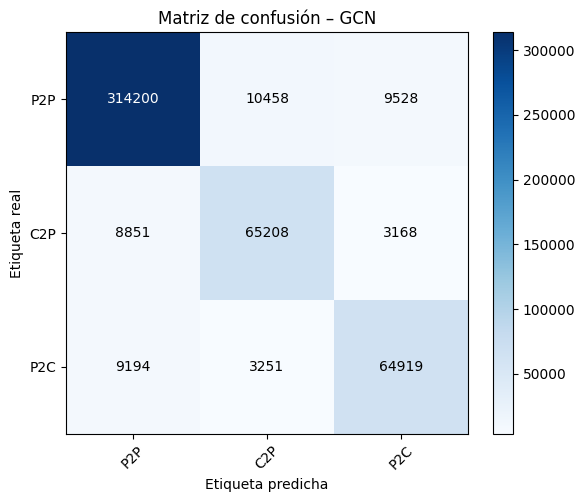

Matriz de confusión normalizada (%)


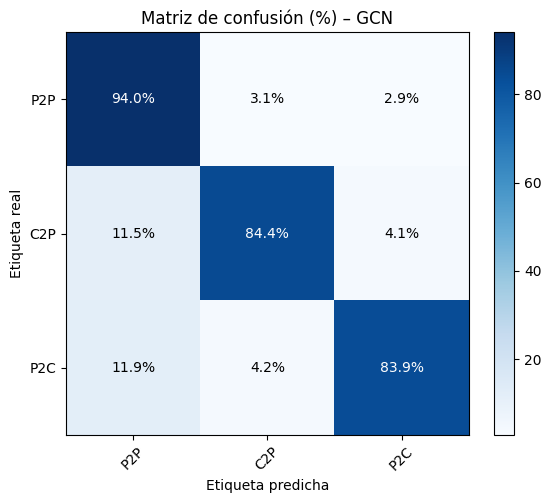

              precision    recall  f1-score   support

           0     0.9457    0.9402    0.9429    334186
           1     0.8263    0.8444    0.8352     77227
           2     0.8364    0.8391    0.8378     77364

    accuracy                         0.9091    488777
   macro avg     0.8695    0.8746    0.8720    488777
weighted avg     0.9095    0.9091    0.9093    488777



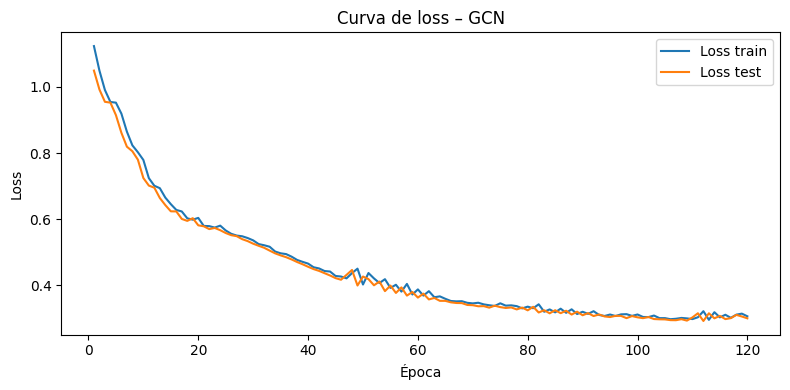

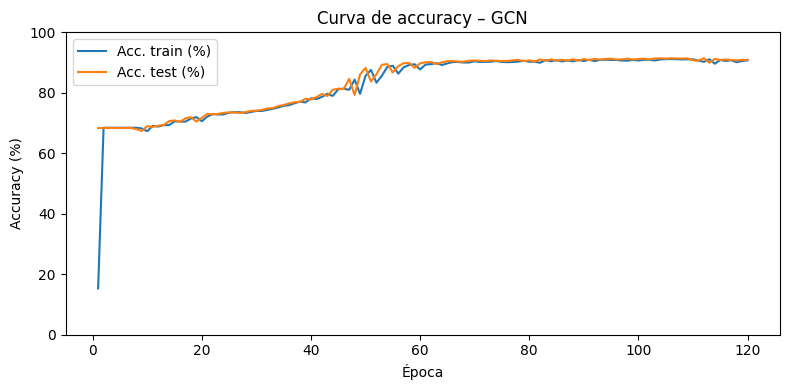


=== Training GraphSAGE (Bilinear) ===
ep01  loss_tr 1.8494 acc_tr 17.45% | loss_te 1.2818 acc_te 21.49%
ep10  loss_tr 0.7882 acc_tr 72.74% | loss_te 0.7133 acc_te 73.81%
ep20  loss_tr 0.6432 acc_tr 77.41% | loss_te 0.6113 acc_te 78.27%
ep30  loss_tr 0.5773 acc_tr 79.04% | loss_te 0.5493 acc_te 79.89%
ep40  loss_tr 0.5329 acc_tr 80.26% | loss_te 0.4993 acc_te 81.15%
ep50  loss_tr 0.4769 acc_tr 82.87% | loss_te 0.4367 acc_te 83.65%
ep60  loss_tr 0.4156 acc_tr 85.48% | loss_te 0.3762 acc_te 86.96%
ep70  loss_tr 0.3808 acc_tr 87.00% | loss_te 0.3371 acc_te 88.70%
ep80  loss_tr 0.3548 acc_tr 87.41% | loss_te 0.3147 acc_te 89.02%
ep90  loss_tr 0.3427 acc_tr 88.00% | loss_te 0.3055 acc_te 89.35%
ep100  loss_tr 0.3322 acc_tr 88.76% | loss_te 0.2937 acc_te 89.82%
ep110  loss_tr 0.3231 acc_tr 88.87% | loss_te 0.2895 acc_te 89.79%
ep120  loss_tr 0.3162 acc_tr 89.23% | loss_te 0.2836 acc_te 90.13%
ep130  loss_tr 0.3094 acc_tr 89.28% | loss_te 0.2792 acc_te 90.23%
ep140  loss_tr 0.3036 acc_tr 89.6

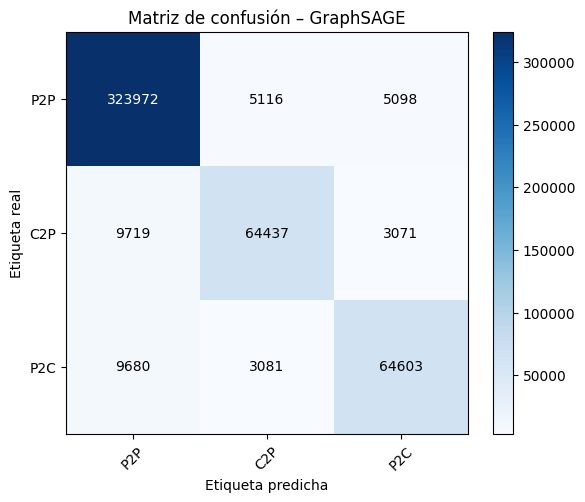

Matriz de confusión normalizada (%)


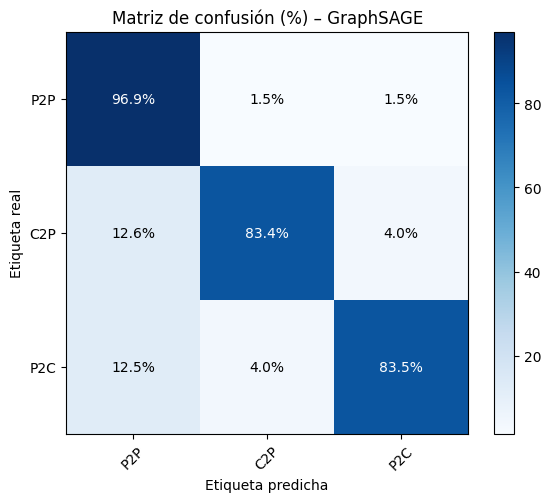

              precision    recall  f1-score   support

           0     0.9435    0.9694    0.9563    334186
           1     0.8871    0.8344    0.8600     77227
           2     0.8877    0.8351    0.8606     77364

    accuracy                         0.9268    488777
   macro avg     0.9061    0.8796    0.8923    488777
weighted avg     0.9258    0.9268    0.9259    488777



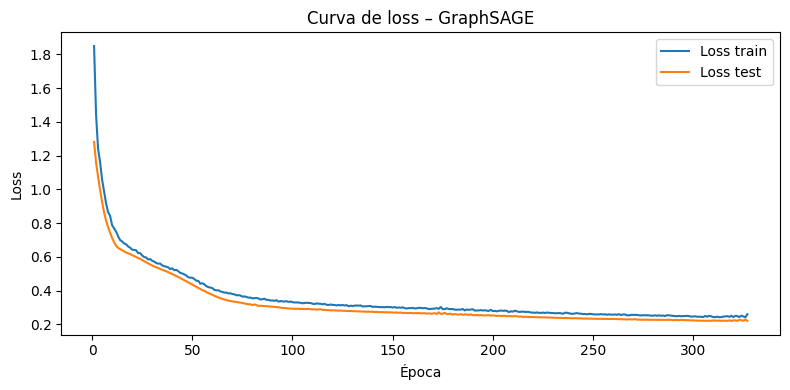

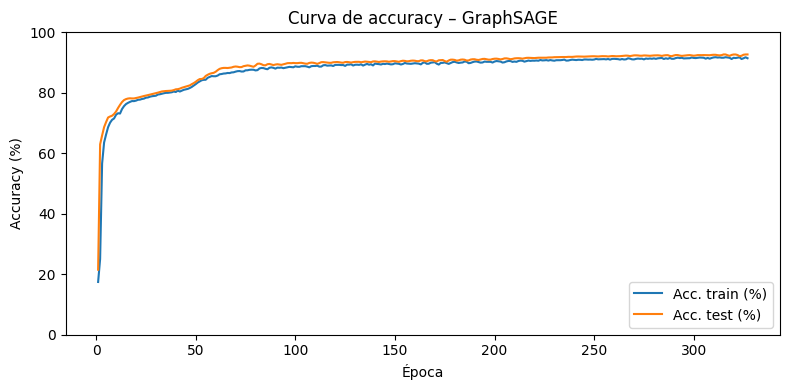


=== Training GAT (Bilinear) ===
ep01  loss_tr 1.0974 acc_tr 63.28% | loss_te 1.0467 acc_te 68.90%
ep10  loss_tr 0.6705 acc_tr 75.24% | loss_te 0.6559 acc_te 75.60%
ep20  loss_tr 0.5517 acc_tr 78.35% | loss_te 0.5409 acc_te 78.61%
ep30  loss_tr 0.4976 acc_tr 80.44% | loss_te 0.4859 acc_te 80.62%
ep40  loss_tr 0.4639 acc_tr 81.58% | loss_te 0.4508 acc_te 82.05%
ep50  loss_tr 0.4285 acc_tr 83.45% | loss_te 0.4195 acc_te 83.32%
ep60  loss_tr 0.4071 acc_tr 84.61% | loss_te 0.3954 acc_te 85.22%
ep70  loss_tr 0.3865 acc_tr 85.76% | loss_te 0.3793 acc_te 86.24%
ep80  loss_tr 0.3730 acc_tr 86.49% | loss_te 0.3608 acc_te 86.87%
ep90  loss_tr 0.3530 acc_tr 87.44% | loss_te 0.3484 acc_te 87.38%
ep100  loss_tr 0.3366 acc_tr 88.12% | loss_te 0.3339 acc_te 88.58%
ep110  loss_tr 0.3199 acc_tr 88.64% | loss_te 0.3208 acc_te 88.71%
ep120  loss_tr 0.3076 acc_tr 89.38% | loss_te 0.3064 acc_te 89.47%
ep130  loss_tr 0.3047 acc_tr 89.19% | loss_te 0.3074 acc_te 90.20%
ep140  loss_tr 0.2834 acc_tr 90.21% | l

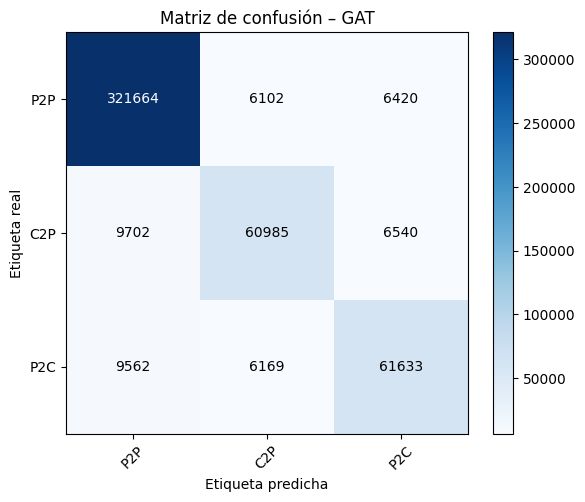

Matriz de confusión normalizada (%)


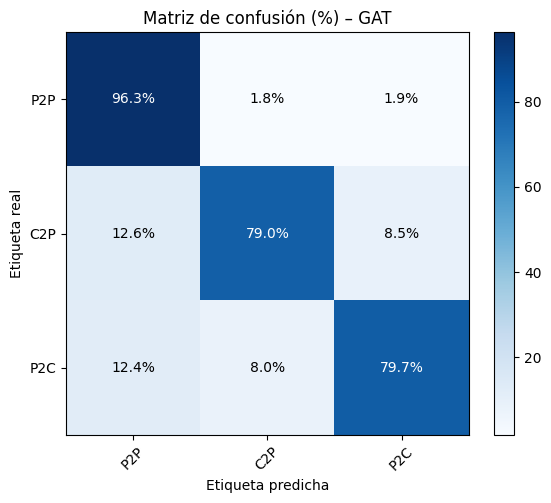

              precision    recall  f1-score   support

           0     0.9435    0.9625    0.9529    334186
           1     0.8325    0.7897    0.8105     77227
           2     0.8263    0.7967    0.8112     77364

    accuracy                         0.9090    488777
   macro avg     0.8674    0.8496    0.8582    488777
weighted avg     0.9074    0.9090    0.9080    488777



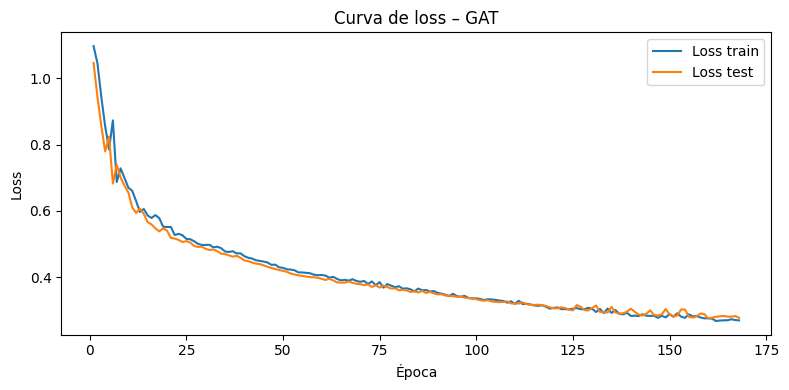

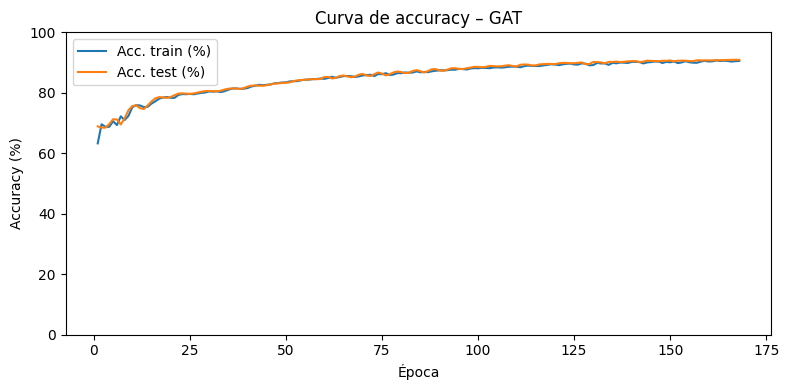

In [8]:
import torch, itertools, torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns, matplotlib.pyplot as plt

# ─── parámetros básicos ─────────────────────────────────────────────
in_feats      = gnn.dgl_graph.ndata["feat"].shape[1]
hidden_feats  = 32
emb_dim       = 16
n_classes     = 3
epochs        = 500
lr            = 1e-2
device        = "cuda" if torch.cuda.is_available() else "cpu"

# ─── datos y máscaras ───────────────────────────────────────────────
g       = gnn.dgl_graph.to(device)
feat    = g.ndata["feat"].to(device)
labels  = g.edata["Relationship"].long().to(device)

train_m = g.edata["train_mask"].to(device)
test_m  = g.edata["test_mask"].to(device)

# ─── entrenamiento ─────────────────────────────────────────────────
import torch, torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix


for name, Model in models.items():
    print(f"\n=== Training {name} (Bilinear) ===")

    history = {"loss_tr": [], "acc_tr": [], "loss_te": [], "acc_te": []}


    model = Model(in_feats, hidden_feats, emb_dim, out_feats_mlp=n_classes).to(device)
    opt   = torch.optim.Adam(model.parameters(), lr=lr)

    best_loss, patience, wait = 1e9, 8, 0          # early-stopping

    for epoch in range(1, epochs + 1):
        # ---------- train ----------
        model.train()
        h      = model.encode(g, feat)
        logits = model.decodeBilinear(g, h)         # (E, 3)

        loss   = F.cross_entropy(logits[train_m], labels[train_m])
        opt.zero_grad(); loss.backward(); opt.step()

        with torch.no_grad():
            preds_tr = logits[train_m].argmax(1)
            acc_tr   = (preds_tr == labels[train_m]).float().mean().item()

        # ---------- test ----------
        model.eval()
        with torch.no_grad():
            logits_ = model.decodeBilinear(g, model.encode(g, feat))
            loss_te = F.cross_entropy(logits_[test_m], labels[test_m])
            preds_t = logits_[test_m].argmax(1)
            acc_t   = (preds_t == labels[test_m]).float().mean().item()


        # guarda históricos
        history["loss_tr"].append(loss.item())
        history["acc_tr"].append(acc_tr*100)
        history["loss_te"].append(loss_te.item())
        history["acc_te"].append(acc_t*100)

        # early stopping
        if loss_te < best_loss - 1e-4:
            best_loss, wait = loss_te, 0
            best_w = model.state_dict()
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑  Early stop en epoch {epoch}")
                break

        if epoch % 10 == 0 or epoch == 1:
            print(f"ep{epoch:02d}  loss_tr {loss:.4f} acc_tr {acc_tr:.2%} | "
                  f"loss_te {loss_te:.4f} acc_te {acc_t:.2%}")

    # ---------- matriz de confusión final ----------
    model.load_state_dict(best_w)
    with torch.no_grad():
        logits_best = model.decodeBilinear(g, model.encode(g, feat))
        preds_best  = logits_best[test_m].argmax(1).cpu()
        truth       = labels[test_m].cpu()

    cm = confusion_matrix(truth, preds_best)
    plot_confusion_matrix_2(cm, classes=["P2P","C2P","P2C"],
                            normalize=False,
                            title=f"Matriz de confusión – {name}")
    plot_confusion_matrix_2(cm, classes=["P2P","C2P","P2C"],
                            normalize=True,
                            title=f"Matriz de confusión (%) – {name}")

    print(classification_report(truth, preds_best, digits=4))

    # ─── gráficas de Loss y Accuracy ───────────────────────────────────
    import matplotlib.pyplot as plt
    epoch_axis = range(1, len(history["loss_tr"]) + 1)

    plt.figure(figsize=(8,4))
    plt.plot(epoch_axis, history["loss_tr"],  label="Loss train")
    plt.plot(epoch_axis, history["loss_te"],  label="Loss test")
    plt.xlabel("Época"); plt.ylabel("Loss"); plt.title(f"Curva de loss – {name}")
    plt.legend(); plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8,4))
    plt.plot(epoch_axis, history["acc_tr"],  label="Acc. train (%)")
    plt.plot(epoch_axis, history["acc_te"],  label="Acc. test (%)")
    plt.xlabel("Época"); plt.ylabel("Accuracy (%)"); plt.title(f"Curva de accuracy – {name}")
    plt.ylim(0, 100); plt.legend(); plt.tight_layout()
    plt.show()


    # Compute confusion matrix
    # # Guaradar el modelo
    # torch.save(model.state_dict(), f'data/model_emb_{model_name}.pth')

    # # Guardar los embeddings
    # torch.save(h, f"data/embeddings_ribs_DP_{model_name}.pt")



#### Encoder: MLP


=== Training GCN ===
ep01 | loss_tr 1.1592 acc_tr 15.76% | loss_te 1.0968 acc_te 18.16%
ep10 | loss_tr 0.7186 acc_tr 68.45% | loss_te 0.6885 acc_te 69.44%
ep20 | loss_tr 0.6700 acc_tr 66.91% | loss_te 0.6535 acc_te 70.04%
ep30 | loss_tr 0.6400 acc_tr 69.34% | loss_te 0.6426 acc_te 68.61%
ep40 | loss_tr 0.6168 acc_tr 71.20% | loss_te 0.6155 acc_te 71.44%
ep50 | loss_tr 0.5810 acc_tr 73.22% | loss_te 0.5778 acc_te 73.14%
ep60 | loss_tr 0.5343 acc_tr 75.30% | loss_te 0.5299 acc_te 75.68%
ep70 | loss_tr 0.4626 acc_tr 78.94% | loss_te 0.4543 acc_te 79.42%
ep80 | loss_tr 0.4073 acc_tr 86.24% | loss_te 0.3929 acc_te 87.49%
ep90 | loss_tr 0.3634 acc_tr 88.67% | loss_te 0.3606 acc_te 88.72%
ep100 | loss_tr 0.3410 acc_tr 89.10% | loss_te 0.3419 acc_te 88.70%
ep110 | loss_tr 0.3263 acc_tr 89.02% | loss_te 0.3213 acc_te 88.86%
ep120 | loss_tr 0.3105 acc_tr 89.06% | loss_te 0.3054 acc_te 89.71%
ep130 | loss_tr 0.2956 acc_tr 89.76% | loss_te 0.2937 acc_te 89.60%
ep140 | loss_tr 0.2904 acc_tr 89.90%

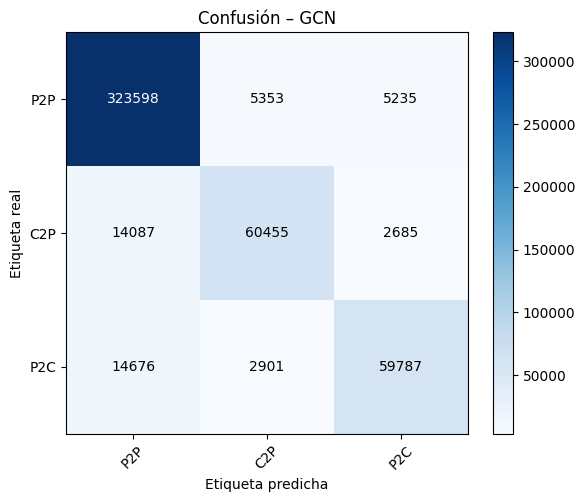

Matriz de confusión normalizada (%)


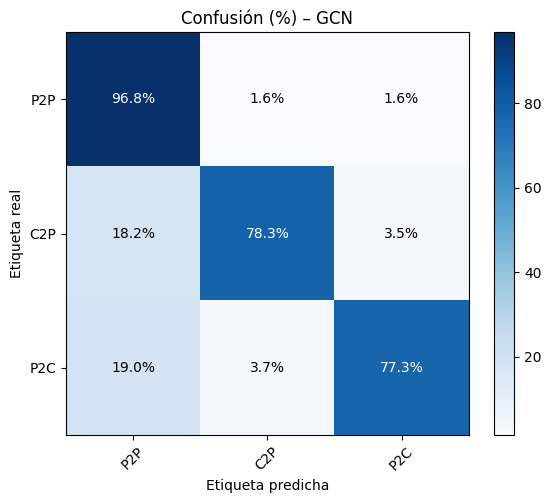

              precision    recall  f1-score   support

           0     0.9184    0.9683    0.9427    334186
           1     0.8799    0.7828    0.8285     77227
           2     0.8830    0.7728    0.8242     77364

    accuracy                         0.9081    488777
   macro avg     0.8938    0.8413    0.8651    488777
weighted avg     0.9067    0.9081    0.9059    488777



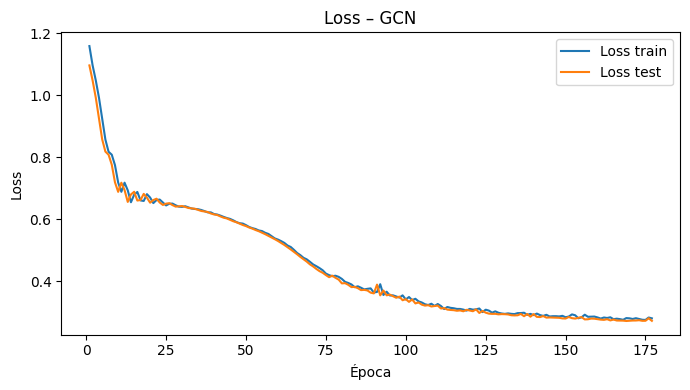

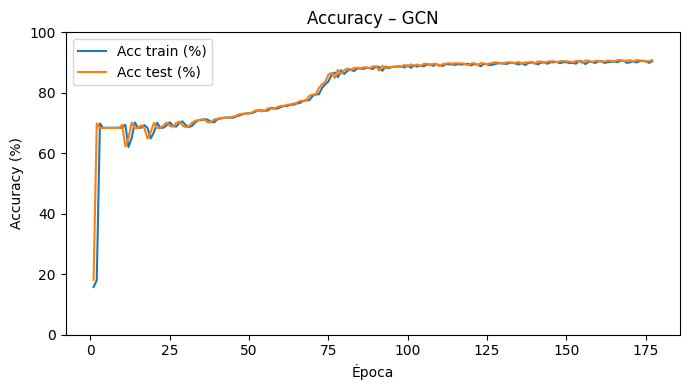


=== Training GraphSAGE ===
ep01 | loss_tr 1.0630 acc_tr 63.66% | loss_te 0.9982 acc_te 68.37%
ep10 | loss_tr 0.8217 acc_tr 69.06% | loss_te 0.7994 acc_te 69.79%
ep20 | loss_tr 0.6554 acc_tr 77.53% | loss_te 0.6320 acc_te 78.23%
ep30 | loss_tr 0.5525 acc_tr 79.48% | loss_te 0.5329 acc_te 79.89%
ep40 | loss_tr 0.4480 acc_tr 83.74% | loss_te 0.4203 acc_te 84.90%
ep50 | loss_tr 0.3769 acc_tr 86.82% | loss_te 0.3445 acc_te 87.87%
ep60 | loss_tr 0.3367 acc_tr 88.21% | loss_te 0.3141 acc_te 88.97%
ep70 | loss_tr 0.3149 acc_tr 88.95% | loss_te 0.2918 acc_te 89.66%
ep80 | loss_tr 0.2971 acc_tr 89.62% | loss_te 0.2699 acc_te 90.54%
ep90 | loss_tr 0.2733 acc_tr 90.44% | loss_te 0.2514 acc_te 91.26%
ep100 | loss_tr 0.2659 acc_tr 90.70% | loss_te 0.2379 acc_te 91.81%
ep110 | loss_tr 0.2553 acc_tr 91.25% | loss_te 0.2316 acc_te 92.09%
ep120 | loss_tr 0.2489 acc_tr 91.49% | loss_te 0.2252 acc_te 92.36%
ep130 | loss_tr 0.2388 acc_tr 91.70% | loss_te 0.2215 acc_te 92.51%
ep140 | loss_tr 0.2340 acc_tr 

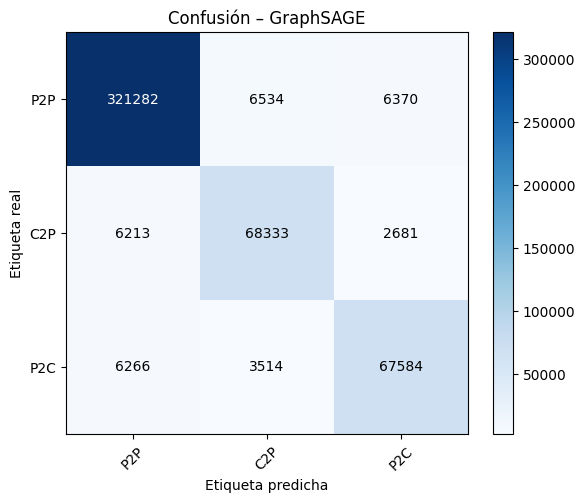

Matriz de confusión normalizada (%)


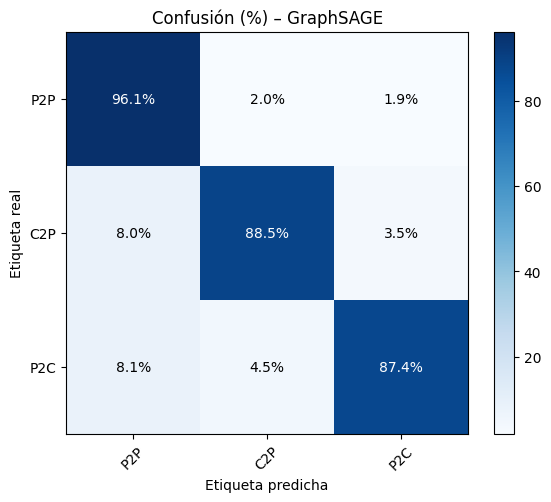

              precision    recall  f1-score   support

           0     0.9626    0.9614    0.9620    334186
           1     0.8718    0.8848    0.8783     77227
           2     0.8819    0.8736    0.8777     77364

    accuracy                         0.9354    488777
   macro avg     0.9054    0.9066    0.9060    488777
weighted avg     0.9355    0.9354    0.9354    488777



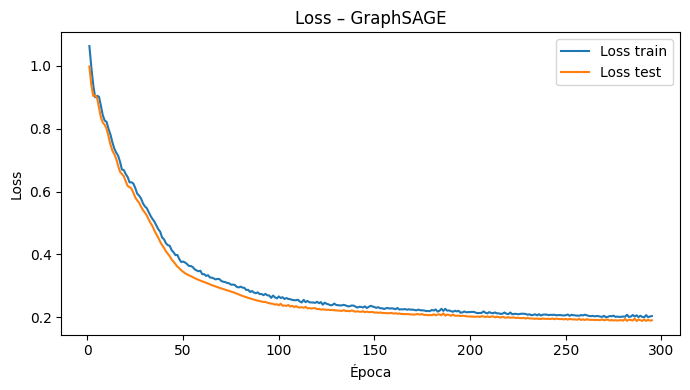

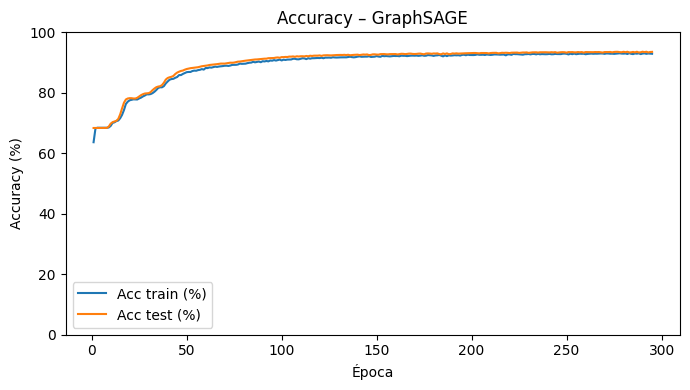


=== Training GAT ===
ep01 | loss_tr 1.1597 acc_tr 15.76% | loss_te 1.1321 acc_te 15.83%
ep10 | loss_tr 0.8492 acc_tr 68.45% | loss_te 0.8086 acc_te 68.37%
ep20 | loss_tr 0.6789 acc_tr 72.72% | loss_te 0.6374 acc_te 71.74%
ep30 | loss_tr 0.5350 acc_tr 78.53% | loss_te 0.5395 acc_te 77.38%
ep40 | loss_tr 0.4755 acc_tr 81.35% | loss_te 0.4920 acc_te 80.11%
ep50 | loss_tr 0.4226 acc_tr 84.14% | loss_te 0.4206 acc_te 84.26%
ep60 | loss_tr 0.3811 acc_tr 85.94% | loss_te 0.3870 acc_te 85.81%
ep70 | loss_tr 0.3625 acc_tr 86.73% | loss_te 0.3687 acc_te 86.63%
ep80 | loss_tr 0.3448 acc_tr 87.19% | loss_te 0.3403 acc_te 87.53%
ep90 | loss_tr 0.3276 acc_tr 87.97% | loss_te 0.3321 acc_te 87.85%
ep100 | loss_tr 0.3090 acc_tr 88.69% | loss_te 0.3128 acc_te 88.44%
ep110 | loss_tr 0.3039 acc_tr 88.78% | loss_te 0.2935 acc_te 89.31%
ep120 | loss_tr 0.2914 acc_tr 89.29% | loss_te 0.2883 acc_te 89.53%
ep130 | loss_tr 0.2816 acc_tr 89.87% | loss_te 0.2732 acc_te 90.27%
ep140 | loss_tr 0.2749 acc_tr 89.90%

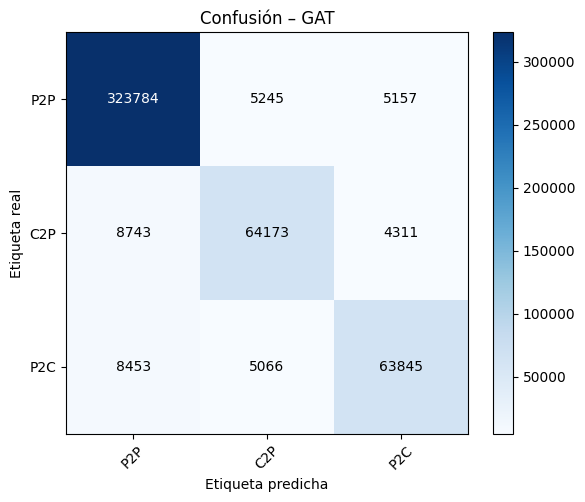

Matriz de confusión normalizada (%)


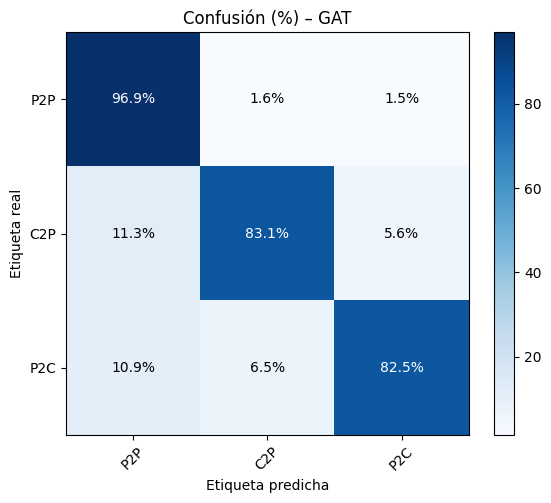

              precision    recall  f1-score   support

           0     0.9496    0.9689    0.9591    334186
           1     0.8616    0.8310    0.8460     77227
           2     0.8709    0.8253    0.8474     77364

    accuracy                         0.9244    488777
   macro avg     0.8940    0.8750    0.8842    488777
weighted avg     0.9232    0.9244    0.9236    488777



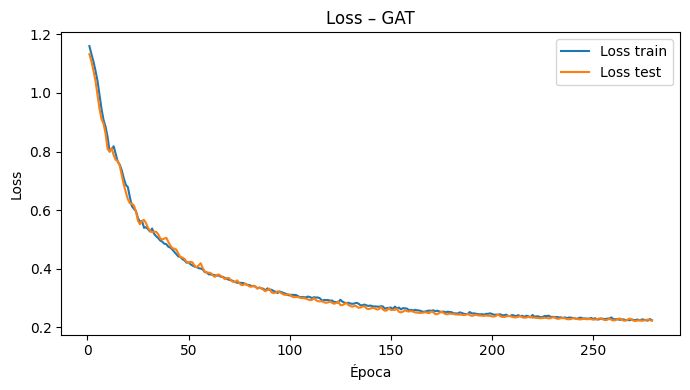

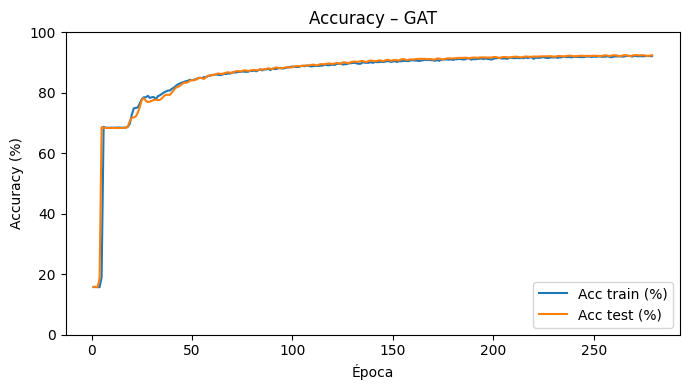

In [7]:
import torch, torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# ─── parámetros globales ────────────────────────────────────────────
in_feats  = gnn.dgl_graph.ndata["feat"].shape[1]
device    = "cuda" if torch.cuda.is_available() else "cpu"
epochs    = 500
lr        = 1e-2
patience  = 8           # early-stopping
n_classes = 3

# ─── datos y máscaras ───────────────────────────────────────────────
g       = gnn.dgl_graph.to(device)
feat    = g.ndata["feat"].to(device)
labels  = g.edata["Relationship"].long().to(device)
train_m = g.edata["train_mask"].to(device)
test_m  = g.edata["test_mask"].to(device)

for name, Model in models.items():
    print(f"\n=== Training {name} ===")

    model = Model(in_feats, 32, 16, out_feats_mlp=n_classes).to(device)
    opt   = torch.optim.Adam(model.parameters() , lr=lr)

    # histórico por modelo
    hist = {"loss_tr": [], "acc_tr": [], "loss_te": [], "acc_te": []}
    best_loss, wait = 1e9, 0

    for ep in range(1, epochs + 1):
        # ---------- train ----------
        model.train()
        h      = model.encode(g, feat)
        logits = model.decodeMLP(g, h)                  # (E, 3)

        loss   = F.cross_entropy(logits[train_m], labels[train_m])
        
        opt.zero_grad()
        loss.backward() 
        opt.step()

        with torch.no_grad():
            preds_tr = logits[train_m].argmax(1)
            acc_tr   = (preds_tr == labels[train_m]).float().mean().item()

        # ---------- test ----------
        model.eval()
        with torch.no_grad():
            logits_t = model.decodeMLP(g, model.encode(g, feat))
            loss_te  = F.cross_entropy(logits_t[test_m], labels[test_m])
            preds_t  = logits_t[test_m].argmax(1)
            acc_t    = (preds_t == labels[test_m]).float().mean().item()

        # guarda histórico
        hist["loss_tr"].append(loss.item())
        hist["acc_tr"].append(acc_tr * 100)
        hist["loss_te"].append(loss_te.item())
        hist["acc_te"].append(acc_t * 100)

        # early-stopping
        if loss_te < best_loss - 1e-4:
            best_loss, wait = loss_te, 0
            best_w = model.state_dict()
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑  Early stop en época {ep}")
                break

        if ep % 10 == 0 or ep == 1:
            print(f"ep{ep:02d} | loss_tr {loss:.4f} acc_tr {acc_tr:.2%} | "
                  f"loss_te {loss_te:.4f} acc_te {acc_t:.2%}")

    # ---------- evaluación final ----------
    model.load_state_dict(best_w)
    with torch.no_grad():
        logits_best = model.decodeMLP(g, model.encode(g, feat))
        preds_best  = logits_best[test_m].argmax(1).cpu()
        truth       = labels[test_m].cpu()

    cm = confusion_matrix(truth, preds_best)
    plot_confusion_matrix_2(cm, ["P2P","C2P","P2C"], False,
                            title=f"Confusión – {name}")
    plot_confusion_matrix_2(cm, ["P2P","C2P","P2C"], True,
                            title=f"Confusión (%) – {name}")

    print(classification_report(truth, preds_best, digits=4))

    # ---------- curvas de entrenamiento ----------
    epochs_done = range(1, len(hist["loss_tr"]) + 1)

    plt.figure(figsize=(7,4))
    plt.plot(epochs_done, hist["loss_tr"], label="Loss train")
    plt.plot(epochs_done, hist["loss_te"], label="Loss test")
    plt.xlabel("Época"); plt.ylabel("Loss"); plt.title(f"Loss – {name}")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(epochs_done, hist["acc_tr"], label="Acc train (%)")
    plt.plot(epochs_done, hist["acc_te"], label="Acc test (%)")
    plt.xlabel("Época"); plt.ylabel("Accuracy (%)"); plt.ylim(0,100)
    plt.title(f"Accuracy – {name}")
    plt.legend(); plt.tight_layout(); plt.show()



### Caso 2: Con attr = degre

In [5]:
models = {
    'GCN': GCN,
    'GraphSAGE': GraphSAGE,
    'GAT': GAT,
}

In [7]:
RELATIONSHIPS_FILE = '/home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2'
INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024Degree/febrero'

gnn = GNN(debug=True)

# Cargo dataset y etiqueto sgun archivo de relaciones
gnn.load_dataset(
    data_path=INTERNETGRAPH_FILE,  # Grafo internet no etiquetado
    force_reload=True,
    index_graph = 1,  # Indice del grafo a cargar febrero
    simplify=True,            # ⇐ hazlo sólo una vez
    caida_path=RELATIONSHIPS_FILE  # Archivo CAIDA AS Relationships
)

gnn.split_edges_classification(train_size=0.8, seed=42)



[load_dataset] Leyendo CSV …
Done saving data into cached files.
[load_dataset] Grafo Graph(num_nodes=42683, num_edges=157675438,
      ndata_schemes={'feat': Scheme(shape=(2,), dtype=torch.float32)}
      edata_schemes={})
[load_dataset] Simplificando  …
[load_dataset] Etiquetando CAIDA → /home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2


Etiquetando CAIDA: 488952it [00:01, 476208.17it/s]


[CAIDA] Añadidas 977288 aristas que faltaban
[CAIDA] Conteo final de etiquetas 0/1/2/-1 → Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
[load_dataset] etiquetas 0/1/2/-1 → Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
[split] train=782042  test=195512
  clases train: {0: 534690, 2: 123676, 1: 123676}


#### Encode : Bilinear


=== Training GCN (Bilinear) ===
ep01  loss_tr 1.1137 acc_tr 15.72% | loss_te 1.0638 acc_te 68.58%
ep10  loss_tr 0.8007 acc_tr 68.37% | loss_te 0.7962 acc_te 67.73%
ep20  loss_tr 0.6615 acc_tr 69.69% | loss_te 0.6610 acc_te 69.15%
ep30  loss_tr 0.6475 acc_tr 70.33% | loss_te 0.6468 acc_te 70.00%
ep40  loss_tr 0.6308 acc_tr 69.38% | loss_te 0.6300 acc_te 69.00%
ep50  loss_tr 0.6155 acc_tr 71.21% | loss_te 0.6105 acc_te 70.68%
ep60  loss_tr 0.5924 acc_tr 71.42% | loss_te 0.5930 acc_te 70.72%
ep70  loss_tr 0.5700 acc_tr 71.90% | loss_te 0.5684 acc_te 72.50%
ep80  loss_tr 0.5509 acc_tr 73.04% | loss_te 0.5443 acc_te 75.25%
ep90  loss_tr 0.5133 acc_tr 78.13% | loss_te 0.5159 acc_te 79.86%
ep100  loss_tr 0.5000 acc_tr 83.14% | loss_te 0.5278 acc_te 76.31%
ep110  loss_tr 0.5082 acc_tr 78.06% | loss_te 0.4787 acc_te 84.50%
ep120  loss_tr 0.4637 acc_tr 84.79% | loss_te 0.4594 acc_te 85.03%
ep130  loss_tr 0.4517 acc_tr 84.79% | loss_te 0.4439 acc_te 85.10%
ep140  loss_tr 0.4457 acc_tr 86.94% | l

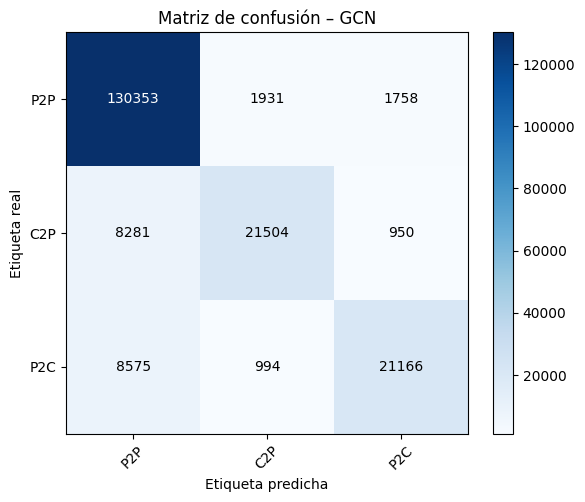

Matriz de confusión normalizada (%)


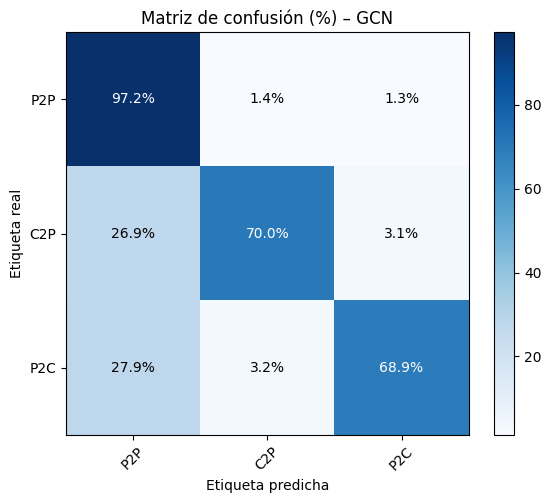

              precision    recall  f1-score   support

           0     0.8855    0.9725    0.9270    134042
           1     0.8803    0.6997    0.7796     30735
           2     0.8866    0.6887    0.7752     30735

    accuracy                         0.8850    195512
   macro avg     0.8841    0.7869    0.8273    195512
weighted avg     0.8848    0.8850    0.8799    195512



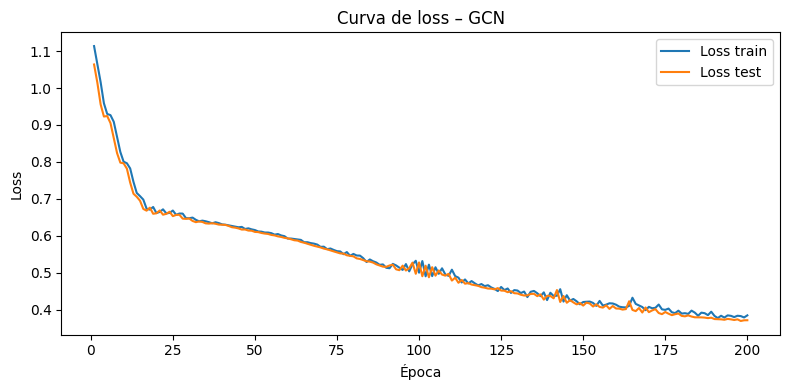

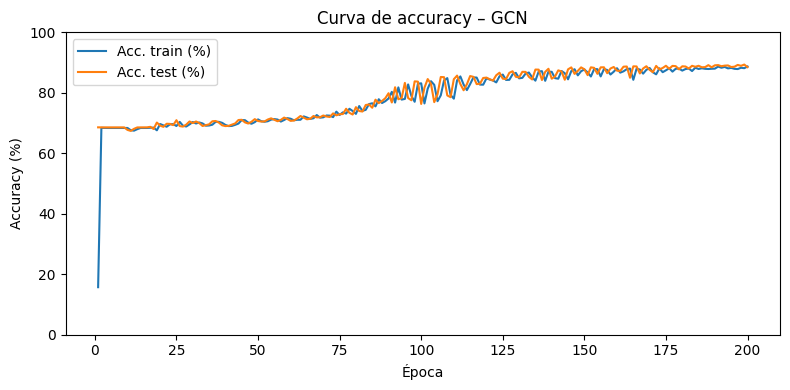


=== Training GraphSAGE (Bilinear) ===
ep01  loss_tr 5.7955 acc_tr 28.01% | loss_te 2.8009 acc_te 68.56%
ep10  loss_tr 1.6295 acc_tr 48.55% | loss_te 0.8109 acc_te 69.68%
ep20  loss_tr 1.1865 acc_tr 55.88% | loss_te 0.7741 acc_te 70.37%
ep30  loss_tr 0.9328 acc_tr 67.98% | loss_te 0.7567 acc_te 70.84%
ep40  loss_tr 0.8220 acc_tr 71.18% | loss_te 0.7340 acc_te 71.65%
ep50  loss_tr 0.7631 acc_tr 73.09% | loss_te 0.7014 acc_te 73.33%
ep60  loss_tr 0.7329 acc_tr 74.34% | loss_te 0.6696 acc_te 74.49%
ep70  loss_tr 0.6747 acc_tr 76.29% | loss_te 0.6392 acc_te 75.51%
ep80  loss_tr 0.6642 acc_tr 76.64% | loss_te 0.6131 acc_te 76.42%
ep90  loss_tr 0.6257 acc_tr 77.72% | loss_te 0.5895 acc_te 77.15%
ep100  loss_tr 0.6068 acc_tr 78.06% | loss_te 0.5680 acc_te 77.96%
ep110  loss_tr 0.5815 acc_tr 79.25% | loss_te 0.5511 acc_te 78.77%
ep120  loss_tr 0.5631 acc_tr 79.88% | loss_te 0.5374 acc_te 78.77%
ep130  loss_tr 0.5611 acc_tr 79.54% | loss_te 0.5335 acc_te 78.54%
ep140  loss_tr 0.5397 acc_tr 80.9

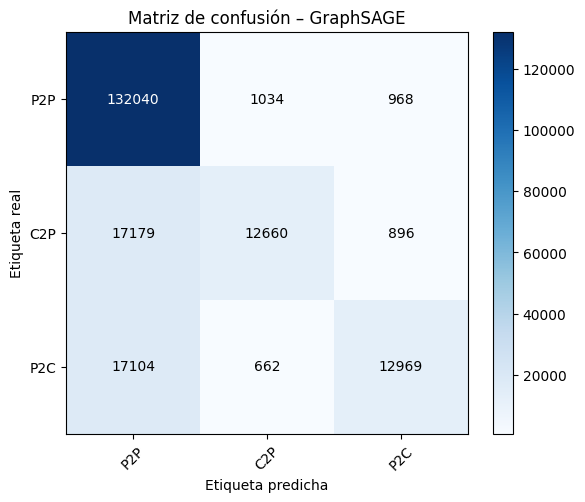

Matriz de confusión normalizada (%)


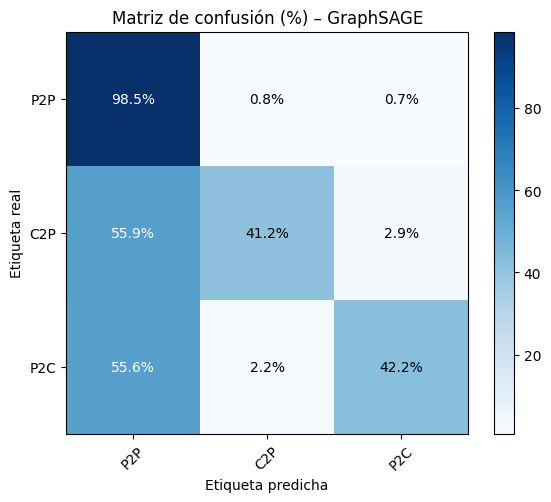

              precision    recall  f1-score   support

           0     0.7939    0.9851    0.8792    134042
           1     0.8819    0.4119    0.5615     30735
           2     0.8743    0.4220    0.5692     30735

    accuracy                         0.8064    195512
   macro avg     0.8500    0.6063    0.6700    195512
weighted avg     0.8204    0.8064    0.7805    195512



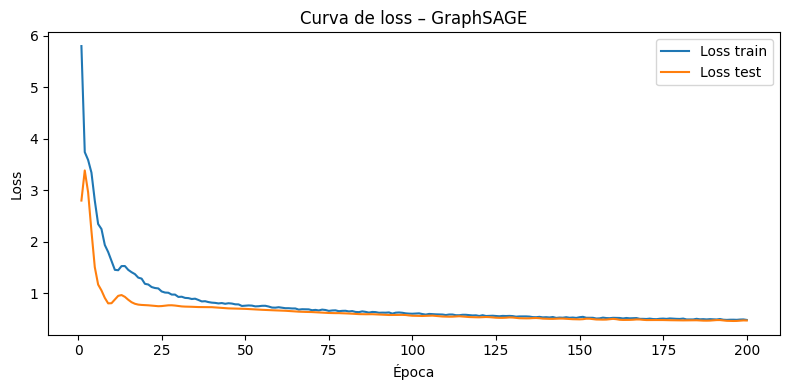

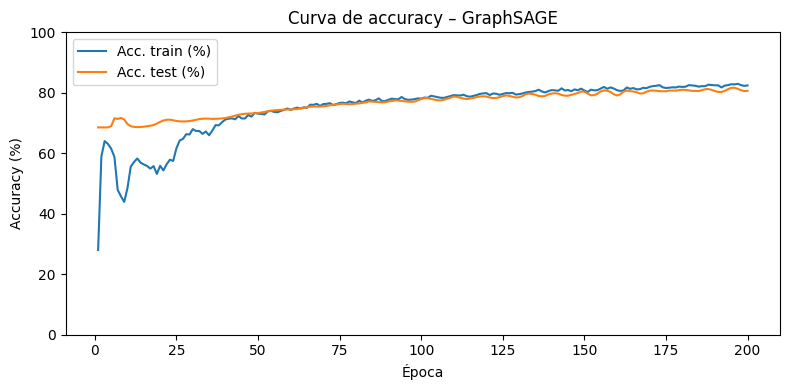


=== Training GAT (Bilinear) ===
ep01  loss_tr 1.0950 acc_tr 67.85% | loss_te 1.0486 acc_te 68.56%
ep10  loss_tr 0.8496 acc_tr 68.37% | loss_te 0.8473 acc_te 68.56%
ep20  loss_tr 0.7696 acc_tr 70.32% | loss_te 0.7504 acc_te 70.36%
ep30  loss_tr 0.7261 acc_tr 71.87% | loss_te 0.7145 acc_te 72.28%
ep40  loss_tr 0.6923 acc_tr 73.45% | loss_te 0.6804 acc_te 73.24%
ep50  loss_tr 0.6586 acc_tr 74.70% | loss_te 0.6564 acc_te 73.66%
ep60  loss_tr 0.6426 acc_tr 75.13% | loss_te 0.6302 acc_te 74.98%
ep70  loss_tr 0.6179 acc_tr 76.51% | loss_te 0.5967 acc_te 76.48%
ep80  loss_tr 0.5769 acc_tr 78.09% | loss_te 0.5608 acc_te 78.68%
ep90  loss_tr 0.5497 acc_tr 78.87% | loss_te 0.5203 acc_te 79.79%
ep100  loss_tr 0.5113 acc_tr 81.07% | loss_te 0.4957 acc_te 80.84%
ep110  loss_tr 0.4922 acc_tr 80.95% | loss_te 0.4784 acc_te 81.71%
ep120  loss_tr 0.4729 acc_tr 81.93% | loss_te 0.4662 acc_te 82.35%
ep130  loss_tr 0.4624 acc_tr 82.63% | loss_te 0.4524 acc_te 82.79%
ep140  loss_tr 0.4602 acc_tr 82.78% | l

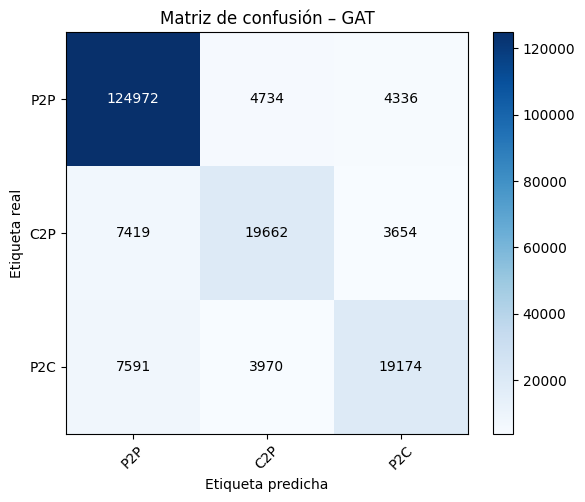

Matriz de confusión normalizada (%)


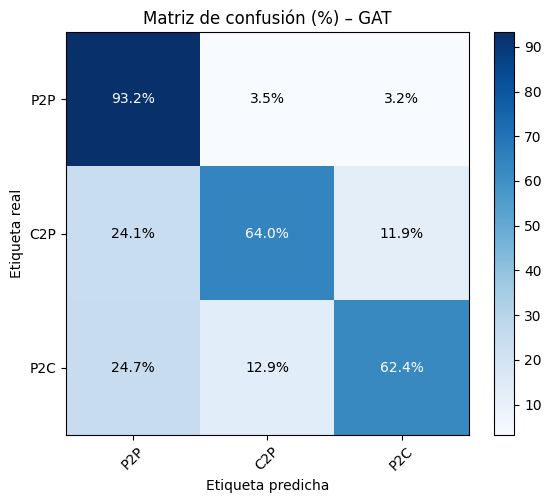

              precision    recall  f1-score   support

           0     0.8928    0.9323    0.9121    134042
           1     0.6932    0.6397    0.6654     30735
           2     0.7059    0.6238    0.6623     30735

    accuracy                         0.8378    195512
   macro avg     0.7639    0.7320    0.7466    195512
weighted avg     0.8320    0.8378    0.8341    195512



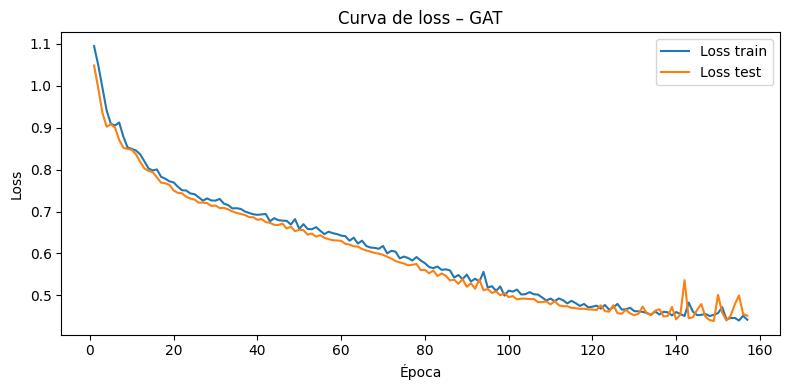

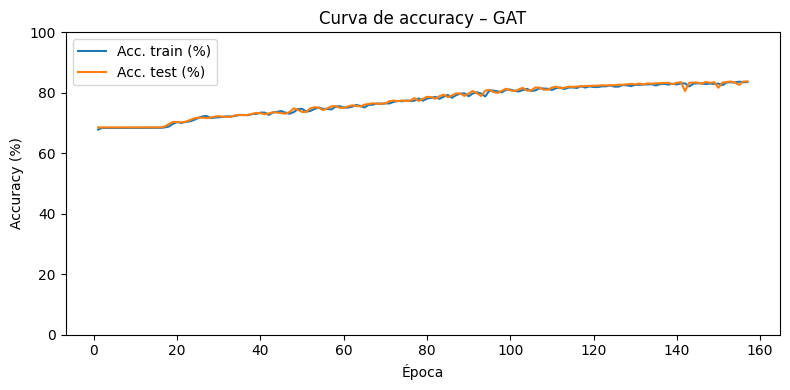

In [8]:
import torch, itertools, torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns, matplotlib.pyplot as plt

# ─── parámetros básicos ─────────────────────────────────────────────
in_feats      = gnn.dgl_graph.ndata["feat"].shape[1]
hidden_feats  = 32
emb_dim       = 16
n_classes     = 3
epochs        = 200
lr            = 0.01
device        = "cuda" if torch.cuda.is_available() else "cpu"

# ─── datos y máscaras ───────────────────────────────────────────────
g       = gnn.dgl_graph.to(device)
feat    = g.ndata["feat"].to(device)
labels  = g.edata["Relationship"].long().to(device)

train_m = g.edata["train_mask"].to(device)
test_m  = g.edata["test_mask"].to(device)

# ─── entrenamiento ─────────────────────────────────────────────────
import torch, torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix


for name, Model in models.items():
    print(f"\n=== Training {name} (Bilinear) ===")

    history = {"loss_tr": [], "acc_tr": [], "loss_te": [], "acc_te": []}


    model = Model(in_feats, hidden_feats, emb_dim, out_feats_mlp=n_classes).to(device)
    opt   = torch.optim.Adam(model.parameters(), lr=lr)

    best_loss, patience, wait = 1e9, 8, 0          # early-stopping

    for epoch in range(1, epochs + 1):
        # ---------- train ----------
        model.train()
        h      = model.encode(g, feat)
        logits = model.decodeBilinear(g, h)         # (E, 3)

        loss   = F.cross_entropy(logits[train_m], labels[train_m])
        opt.zero_grad(); loss.backward(); opt.step()

        with torch.no_grad():
            preds_tr = logits[train_m].argmax(1)
            acc_tr   = (preds_tr == labels[train_m]).float().mean().item()

        # ---------- test ----------
        model.eval()
        with torch.no_grad():
            logits_ = model.decodeBilinear(g, model.encode(g, feat))
            loss_te = F.cross_entropy(logits_[test_m], labels[test_m])
            preds_t = logits_[test_m].argmax(1)
            acc_t   = (preds_t == labels[test_m]).float().mean().item()


        # guarda históricos
        history["loss_tr"].append(loss.item())
        history["acc_tr"].append(acc_tr*100)
        history["loss_te"].append(loss_te.item())
        history["acc_te"].append(acc_t*100)

        # early stopping
        if loss_te < best_loss - 1e-4:
            best_loss, wait = loss_te, 0
            best_w = model.state_dict()
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑  Early stop en epoch {epoch}")
                break

        if epoch % 10 == 0 or epoch == 1:
            print(f"ep{epoch:02d}  loss_tr {loss:.4f} acc_tr {acc_tr:.2%} | "
                  f"loss_te {loss_te:.4f} acc_te {acc_t:.2%}")

    # ---------- matriz de confusión final ----------
    model.load_state_dict(best_w)
    with torch.no_grad():
        logits_best = model.decodeBilinear(g, model.encode(g, feat))
        preds_best  = logits_best[test_m].argmax(1).cpu()
        truth       = labels[test_m].cpu()

    cm = confusion_matrix(truth, preds_best)
    plot_confusion_matrix_2(cm, classes=["P2P","C2P","P2C"],
                            normalize=False,
                            title=f"Matriz de confusión – {name}")
    plot_confusion_matrix_2(cm, classes=["P2P","C2P","P2C"],
                            normalize=True,
                            title=f"Matriz de confusión (%) – {name}")

    print(classification_report(truth, preds_best, digits=4))

    # ─── gráficas de Loss y Accuracy ───────────────────────────────────
    import matplotlib.pyplot as plt
    epoch_axis = range(1, len(history["loss_tr"]) + 1)

    plt.figure(figsize=(8,4))
    plt.plot(epoch_axis, history["loss_tr"],  label="Loss train")
    plt.plot(epoch_axis, history["loss_te"],  label="Loss test")
    plt.xlabel("Época"); plt.ylabel("Loss"); plt.title(f"Curva de loss – {name}")
    plt.legend(); plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8,4))
    plt.plot(epoch_axis, history["acc_tr"],  label="Acc. train (%)")
    plt.plot(epoch_axis, history["acc_te"],  label="Acc. test (%)")
    plt.xlabel("Época"); plt.ylabel("Accuracy (%)"); plt.title(f"Curva de accuracy – {name}")
    plt.ylim(0, 100); plt.legend(); plt.tight_layout()
    plt.show()

    # Compute confusion matrix
    # # Guaradar el modelo
    # torch.save(model.state_dict(), f'data/model_emb_{model_name}.pth')

    # # Guardar los embeddings
    # torch.save(h, f"data/embeddings_ribs_DP_{model_name}.pt")


#### Encoder : MLP


=== Training GCN ===
ep01 | loss_tr 1.0549 acc_tr 68.37% | loss_te 1.0256 acc_te 68.56%
ep10 | loss_tr 0.8097 acc_tr 68.37% | loss_te 0.7778 acc_te 68.56%
ep20 | loss_tr 0.6892 acc_tr 68.37% | loss_te 0.6755 acc_te 68.56%
ep30 | loss_tr 0.6620 acc_tr 69.17% | loss_te 0.6574 acc_te 69.92%
ep40 | loss_tr 0.6544 acc_tr 68.90% | loss_te 0.6496 acc_te 69.65%
ep50 | loss_tr 0.6452 acc_tr 69.46% | loss_te 0.6419 acc_te 70.51%
ep60 | loss_tr 0.6367 acc_tr 70.54% | loss_te 0.6333 acc_te 70.87%
ep70 | loss_tr 0.6205 acc_tr 71.22% | loss_te 0.6178 acc_te 71.38%
ep80 | loss_tr 0.5969 acc_tr 71.74% | loss_te 0.5931 acc_te 72.26%
ep90 | loss_tr 0.5712 acc_tr 73.43% | loss_te 0.5636 acc_te 73.94%
ep100 | loss_tr 0.5343 acc_tr 74.72% | loss_te 0.5252 acc_te 74.09%
ep110 | loss_tr 0.4869 acc_tr 79.48% | loss_te 0.4795 acc_te 80.38%
ep120 | loss_tr 0.4413 acc_tr 84.09% | loss_te 0.4254 acc_te 85.42%
ep130 | loss_tr 0.3937 acc_tr 86.14% | loss_te 0.3852 acc_te 86.65%
ep140 | loss_tr 0.3994 acc_tr 85.38%

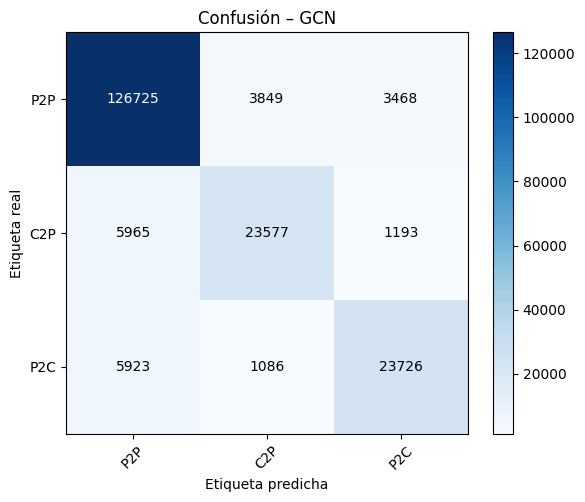

Matriz de confusión normalizada (%)


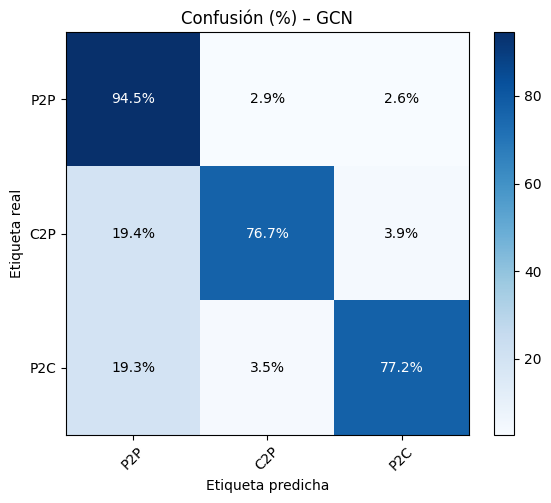

              precision    recall  f1-score   support

           0     0.9142    0.9454    0.9296    134042
           1     0.8269    0.7671    0.7959     30735
           2     0.8358    0.7720    0.8026     30735

    accuracy                         0.8901    195512
   macro avg     0.8590    0.8282    0.8427    195512
weighted avg     0.8882    0.8901    0.8886    195512



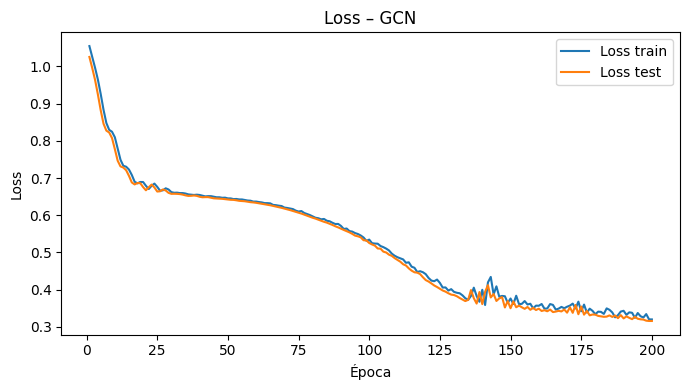

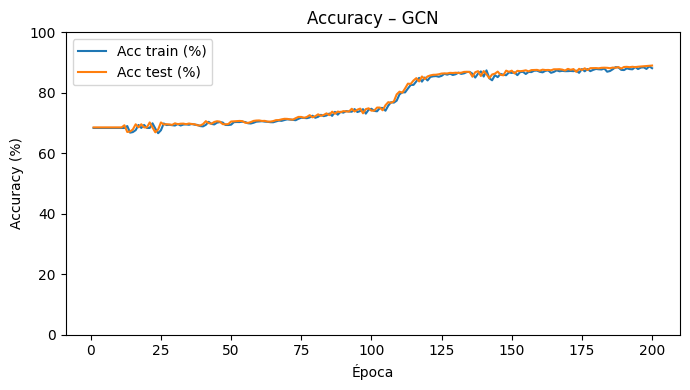


=== Training GraphSAGE ===
ep01 | loss_tr 1.0540 acc_tr 48.89% | loss_te 0.9112 acc_te 68.56%
ep10 | loss_tr 0.8464 acc_tr 68.37% | loss_te 0.8407 acc_te 68.56%
ep20 | loss_tr 0.7968 acc_tr 68.51% | loss_te 0.7872 acc_te 68.75%
ep30 | loss_tr 0.7612 acc_tr 70.78% | loss_te 0.7341 acc_te 71.99%
ep40 | loss_tr 0.6980 acc_tr 75.03% | loss_te 0.6645 acc_te 75.57%
ep50 | loss_tr 0.6512 acc_tr 76.24% | loss_te 0.6194 acc_te 77.01%
ep60 | loss_tr 0.6005 acc_tr 79.23% | loss_te 0.5757 acc_te 79.12%
ep70 | loss_tr 0.5756 acc_tr 79.76% | loss_te 0.5483 acc_te 80.19%
ep80 | loss_tr 0.5450 acc_tr 81.03% | loss_te 0.5229 acc_te 81.02%
ep90 | loss_tr 0.5289 acc_tr 80.66% | loss_te 0.5096 acc_te 82.14%
ep100 | loss_tr 0.5137 acc_tr 81.22% | loss_te 0.4977 acc_te 81.57%
ep110 | loss_tr 0.5029 acc_tr 82.35% | loss_te 0.4930 acc_te 81.71%
ep120 | loss_tr 0.4939 acc_tr 81.85% | loss_te 0.4767 acc_te 82.54%
ep130 | loss_tr 0.4734 acc_tr 82.99% | loss_te 0.4682 acc_te 82.93%
ep140 | loss_tr 0.4630 acc_tr 

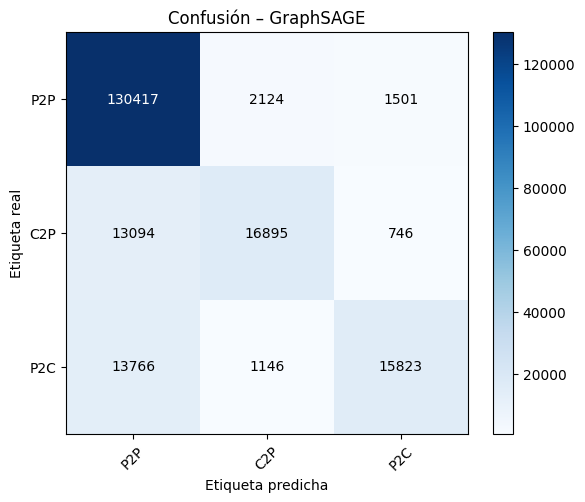

Matriz de confusión normalizada (%)


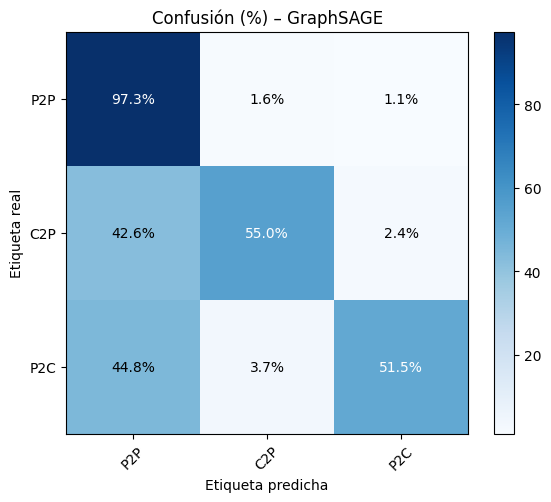

              precision    recall  f1-score   support

           0     0.8292    0.9730    0.8954    134042
           1     0.8378    0.5497    0.6639     30735
           2     0.8757    0.5148    0.6484     30735

    accuracy                         0.8344    195512
   macro avg     0.8476    0.6792    0.7359    195512
weighted avg     0.8379    0.8344    0.8201    195512



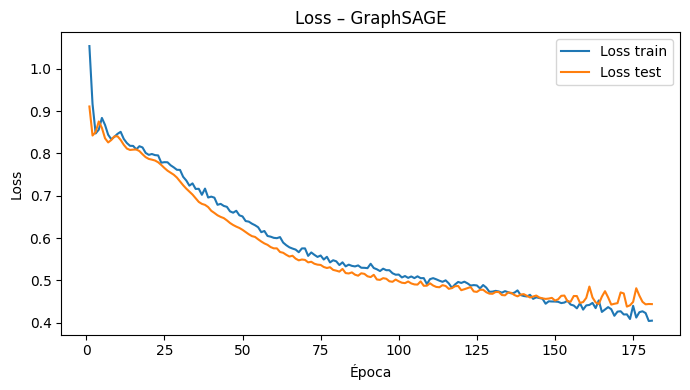

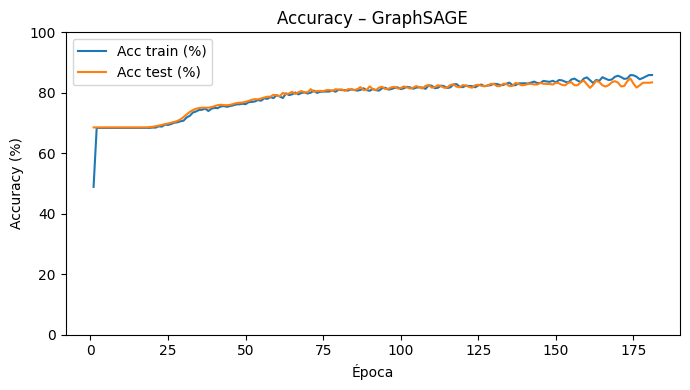


=== Training GAT ===
ep01 | loss_tr 1.0856 acc_tr 15.81% | loss_te 1.0593 acc_te 15.72%
ep10 | loss_tr 0.8785 acc_tr 68.37% | loss_te 0.8671 acc_te 68.56%
ep20 | loss_tr 0.8416 acc_tr 68.37% | loss_te 0.8379 acc_te 68.56%
ep30 | loss_tr 0.7994 acc_tr 68.48% | loss_te 0.7931 acc_te 68.71%
ep40 | loss_tr 0.7536 acc_tr 70.39% | loss_te 0.7423 acc_te 70.85%
ep50 | loss_tr 0.7090 acc_tr 72.24% | loss_te 0.7039 acc_te 72.15%
ep60 | loss_tr 0.6656 acc_tr 73.82% | loss_te 0.6623 acc_te 73.26%
ep70 | loss_tr 0.6197 acc_tr 75.98% | loss_te 0.6153 acc_te 75.77%
ep80 | loss_tr 0.5970 acc_tr 76.87% | loss_te 0.5863 acc_te 77.39%
ep90 | loss_tr 0.5581 acc_tr 78.38% | loss_te 0.5511 acc_te 78.80%
ep100 | loss_tr 0.5138 acc_tr 80.24% | loss_te 0.5099 acc_te 80.21%
ep110 | loss_tr 0.5005 acc_tr 81.07% | loss_te 0.4806 acc_te 81.56%
ep120 | loss_tr 0.4768 acc_tr 82.18% | loss_te 0.5219 acc_te 81.40%
ep130 | loss_tr 0.4570 acc_tr 82.89% | loss_te 0.4972 acc_te 82.33%
🛑  Early stop en época 135
Matriz de

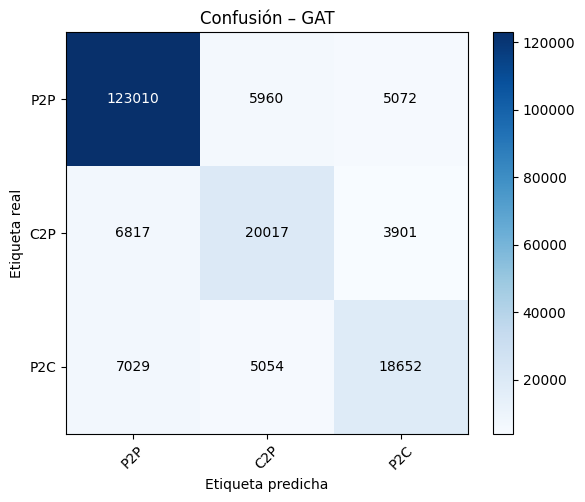

Matriz de confusión normalizada (%)


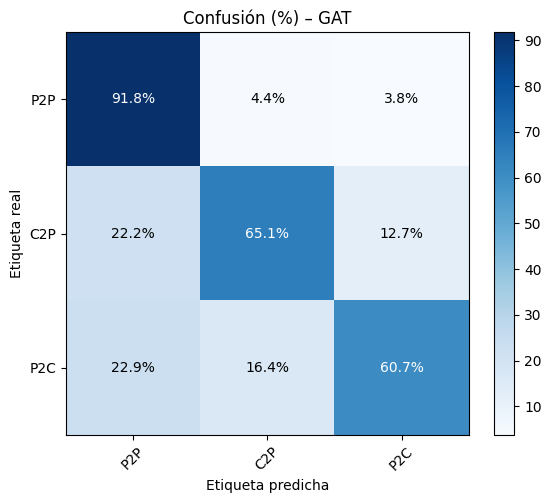

              precision    recall  f1-score   support

           0     0.8988    0.9177    0.9082    134042
           1     0.6451    0.6513    0.6482     30735
           2     0.6752    0.6069    0.6392     30735

    accuracy                         0.8270    195512
   macro avg     0.7397    0.7253    0.7318    195512
weighted avg     0.8238    0.8270    0.8250    195512



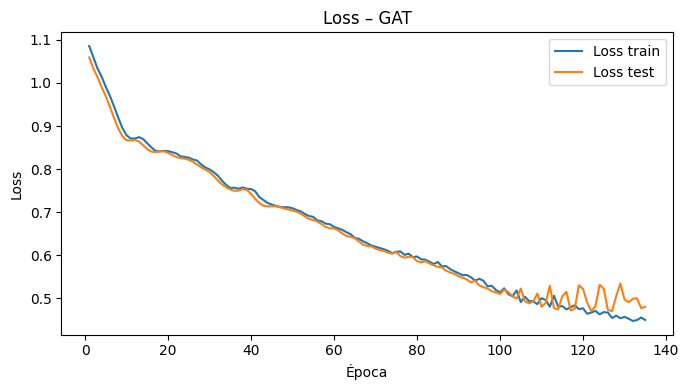

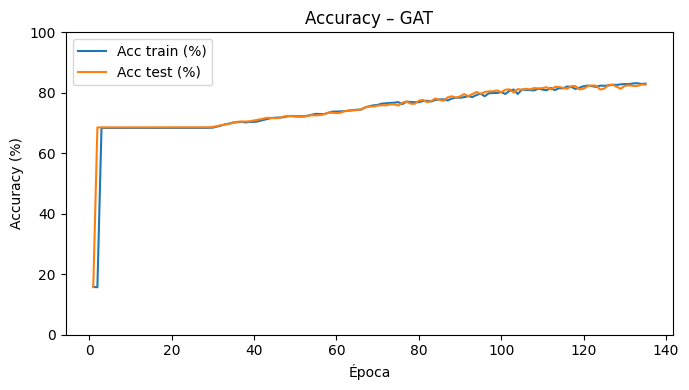

In [9]:
import torch, torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# ─── parámetros globales ────────────────────────────────────────────
in_feats  = gnn.dgl_graph.ndata["feat"].shape[1]
device    = "cuda" if torch.cuda.is_available() else "cpu"
epochs    = 200
lr        = 0.01
patience  = 8           # early-stopping
n_classes = 3

# ─── datos y máscaras ───────────────────────────────────────────────
g       = gnn.dgl_graph.to(device)
feat    = g.ndata["feat"].to(device)
labels  = g.edata["Relationship"].long().to(device)
train_m = g.edata["train_mask"].to(device)
test_m  = g.edata["test_mask"].to(device)

for name, Model in models.items():
    print(f"\n=== Training {name} ===")

    model = Model(in_feats, 32, 16, out_feats_mlp=n_classes).to(device)
    opt   = torch.optim.Adam(model.parameters() , lr=lr)

    # histórico por modelo
    hist = {"loss_tr": [], "acc_tr": [], "loss_te": [], "acc_te": []}
    best_loss, wait = 1e9, 0

    for ep in range(1, epochs + 1):
        # ---------- train ----------
        model.train()
        h      = model.encode(g, feat)
        logits = model.decodeMLP(g, h)                  # (E, 3)

        loss   = F.cross_entropy(logits[train_m], labels[train_m])
        opt.zero_grad(); loss.backward(); opt.step()

        with torch.no_grad():
            preds_tr = logits[train_m].argmax(1)
            acc_tr   = (preds_tr == labels[train_m]).float().mean().item()

        # ---------- test ----------
        model.eval()
        with torch.no_grad():
            logits_t = model.decodeMLP(g, model.encode(g, feat))
            loss_te  = F.cross_entropy(logits_t[test_m], labels[test_m])
            preds_t  = logits_t[test_m].argmax(1)
            acc_t    = (preds_t == labels[test_m]).float().mean().item()

        # guarda histórico
        hist["loss_tr"].append(loss.item())
        hist["acc_tr"].append(acc_tr * 100)
        hist["loss_te"].append(loss_te.item())
        hist["acc_te"].append(acc_t * 100)

        # early-stopping
        if loss_te < best_loss - 1e-4:
            best_loss, wait = loss_te, 0
            best_w = model.state_dict()
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑  Early stop en época {ep}")
                break

        if ep % 10 == 0 or ep == 1:
            print(f"ep{ep:02d} | loss_tr {loss:.4f} acc_tr {acc_tr:.2%} | "
                  f"loss_te {loss_te:.4f} acc_te {acc_t:.2%}")

    # ---------- evaluación final ----------
    model.load_state_dict(best_w)
    with torch.no_grad():
        logits_best = model.decodeMLP(g, model.encode(g, feat))
        preds_best  = logits_best[test_m].argmax(1).cpu()
        truth       = labels[test_m].cpu()

    cm = confusion_matrix(truth, preds_best)
    plot_confusion_matrix_2(cm, ["P2P","C2P","P2C"], False,
                            title=f"Confusión – {name}")
    plot_confusion_matrix_2(cm, ["P2P","C2P","P2C"], True,
                            title=f"Confusión (%) – {name}")

    print(classification_report(truth, preds_best, digits=4))

    # ---------- curvas de entrenamiento ----------
    epochs_done = range(1, len(hist["loss_tr"]) + 1)

    plt.figure(figsize=(7,4))
    plt.plot(epochs_done, hist["loss_tr"], label="Loss train")
    plt.plot(epochs_done, hist["loss_te"], label="Loss test")
    plt.xlabel("Época"); plt.ylabel("Loss"); plt.title(f"Loss – {name}")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(epochs_done, hist["acc_tr"], label="Acc train (%)")
    plt.plot(epochs_done, hist["acc_te"], label="Acc test (%)")
    plt.xlabel("Época"); plt.ylabel("Accuracy (%)"); plt.ylim(0,100)
    plt.title(f"Accuracy – {name}")
    plt.legend(); plt.tight_layout(); plt.show()



### Caso 3: Con Random Neighbour Sampling

In [5]:
from modules.gnn_models import GCNSampler, GraphSAGESample, GATSample

models = {
    "GCN-Sampler":  GCNSampler,
    "SAGE-Sampler": GraphSAGESample,
    "GAT-Sampler":  GATSample
}


In [6]:
RELATIONSHIPS_FILE = '/home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2'
INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024/febrero'

gnn = GNN(debug=True)

# Cargo dataset y etiqueto sgun archivo de relaciones
gnn.load_dataset(
    data_path=INTERNETGRAPH_FILE,  # Grafo internet no etiquetado
    force_reload=True,
    index_graph = 1,  # Indice del grafo a cargar febrero
    simplify=True,            # ⇐ hazlo sólo una vez
    caida_path=RELATIONSHIPS_FILE  # Archivo CAIDA AS Relationships
)

gnn.split_edges_classification(train_size=0.8, seed=42)
# crea máscaras + devuelve eids
train_eids, test_eids = gnn.split_edges_classification(0.8, seed=42, return_eids=True)


[load_dataset] Leyendo CSV …
Done saving data into cached files.
[load_dataset] Grafo Graph(num_nodes=42683, num_edges=157675438,
      ndata_schemes={'feat': Scheme(shape=(68,), dtype=torch.float32)}
      edata_schemes={})
[load_dataset] Simplificando  …
[load_dataset] Etiquetando CAIDA → /home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2


Etiquetando CAIDA: 488952it [00:00, 519964.11it/s]


[CAIDA] Añadidas 977288 aristas que faltaban
[CAIDA] Conteo final de etiquetas 0/1/2/-1 → Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
[load_dataset] etiquetas 0/1/2/-1 → Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
[split] train=782042  test=195512
  clases train: {0: 534690, 2: 123676, 1: 123676}
[split] train=782042  test=195512
  clases train: {0: 534690, 2: 123676, 1: 123676}


In [7]:
from collections import Counter
cnt = Counter(gnn.dgl_graph.edata['Relationship'][train_eids].tolist())
print(cnt)   # → algo como {0: 5 × 10⁶, 1: 8 × 10⁵, 2: 8 × 10⁵}


Counter({0: 534690, 2: 123676, 1: 123676})


AQUIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII


In [10]:
train_mask = gnn.dgl_graph.edata['train_mask']
test_mask = gnn.dgl_graph.edata['test_mask']

# Obtener índices de nodos de entrenamiento
train_nids = train_mask.nonzero(as_tuple=True)[0]

# Obtener índices de nodos de prueba
test_nids = test_mask.nonzero(as_tuple=True)[0]

print(f"TRAIN IDX: {train_mask}")
print(f"TEST IDX: {test_mask}")

print(f"TRAIN NIDS: {train_nids}")
print(f"TEST NIDS: {test_nids}")

TRAIN IDX: tensor([False, False, False,  ...,  True,  True,  True])
TEST IDX: tensor([False, False, False,  ..., False, False, False])
TRAIN NIDS: tensor([  25492,   27587,   38938,  ..., 1676597, 1676598, 1676599])
TEST NIDS: tensor([  39963,  141942,  146457,  ..., 1676579, 1676586, 1676587])


In [20]:
# Definir Dataloader y Sampler Training
sampler_train = dgl.dataloading.NeighborSampler([20, 20])


# Transformar el sampler para predicción de aristas
sampler_train = dgl.dataloading.as_edge_prediction_sampler(
    sampler_train, 
    # exclude='reverse_id',  # Excluir aristas inversas
    # reverse_eids=reverse_eids,  # Especificar las aristas inversas
    # negative_sampler=dgl.dataloading.negative_sampler.Uniform(5)  # Sampler negativo con 5 muestras negativas
)

train_dataloader = dgl.dataloading.DataLoader(
    # The following arguments are specific to DGL's DataLoader.
    gnn.dgl_graph,              # The graph
    train_nids,         # The node IDs to iterate over in minibatches
    sampler_train,            # The neighbor sampler
    # The following arguments are inherited from PyTorch DataLoader.
    batch_size=1000,    # Batch size
    shuffle=True,       # Whether to shuffle the nodes for every epoch
    drop_last=False,    # Whether to drop the last incomplete batch
    # num_workers=0       # Number of sampler processes
)



# Definir Dataloader y Sampler Evaluación ------------------------------------------------------------------
sampler_test = dgl.dataloading.NeighborSampler([20,20])


# Transformar el sampler para predicción de aristas
sampler_test = dgl.dataloading.as_edge_prediction_sampler(
    sampler_test, 
    # exclude='reverse_id',  # Excluir aristas inversas
    # reverse_eids=reverse_eids,  # Especificar las aristas inversas
    # negative_sampler=dgl.dataloading.negative_sampler.Uniform(5)  # Sampler negativo con 5 muestras negativas
)

test_dataloader = dgl.dataloading.DataLoader(
    # The following arguments are specific to DGL's DataLoader.
    gnn.dgl_graph,              # The graph
    test_nids,         # The node IDs to iterate over in minibatches
    sampler_test,            # The neighbor sampler
    # The following arguments are inherited from PyTorch DataLoader.
    batch_size=1000,    # Batch size
    shuffle=True,       # Whether to shuffle the nodes for every epoch
    drop_last=False,    # Whether to drop the last incomplete batch
    # num_workers=0       # Number of sampler processes
)

In [21]:
from modules.gnn_models import GCNSampler, GraphSAGESample, GATSample

models = {
    "GCN-Sampler": GCNSampler,
    "SAGE-Sampler": GraphSAGESample,
    "GAT-Sampler": GATSample
}

import tqdm


===== Entrenando GCN-Sampler =====


  0%|          | 0/783 [00:00<?, ?it/s]/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/dgl/dataloading/dataloader.py:1144: DGLWarning: Dataloader CPU affinity opt is not enabled, consider switching it on (see enable_cpu_affinity() or CPU best practices for DGL [https://docs.dgl.ai/tutorials/cpu/cpu_best_practises.html])
  dgl_warning(
100%|██████████| 783/783 [00:14<00:00, 53.67it/s]


ep001 | loss_tr 0.3314 acc_tr 88.12% | loss_te 0.2687 acc_te 90.73%


100%|██████████| 783/783 [00:15<00:00, 49.89it/s]


ep005 | loss_tr 0.2481 acc_tr 91.46% | loss_te 0.2720 acc_te 90.93%


100%|██████████| 783/783 [00:13<00:00, 58.02it/s]


... (5 outputs left out)

100%|██████████| 783/783 [00:14<00:00, 52.40it/s]


ep025 | loss_tr 0.2273 acc_tr 92.21% | loss_te 0.2294 acc_te 92.31%


100%|██████████| 783/783 [00:13<00:00, 57.60it/s]


🛑  Early-stop en época 29
              precision    recall  f1-score   support

           0     0.9256    0.9780    0.9511    134042
           1     0.9103    0.7826    0.8417     30735
           2     0.8991    0.8034    0.8486     30735

    accuracy                         0.9198    195512
   macro avg     0.9117    0.8547    0.8804    195512
weighted avg     0.9191    0.9198    0.9178    195512

Matriz de confusión normalizada (%)


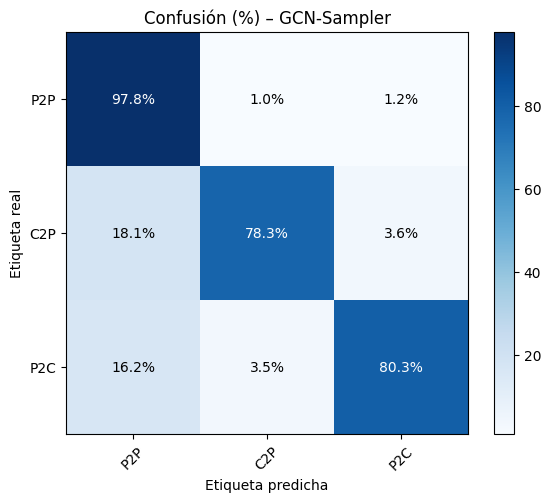

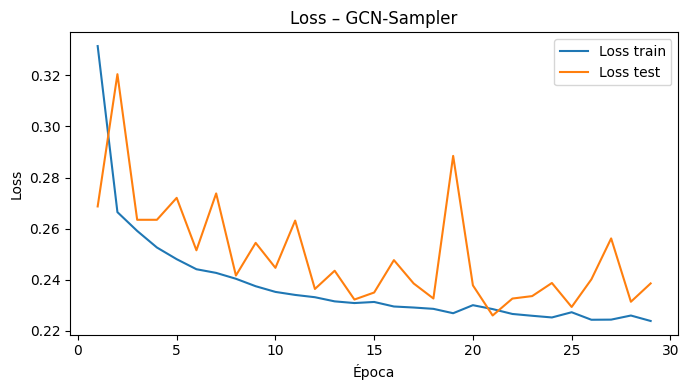

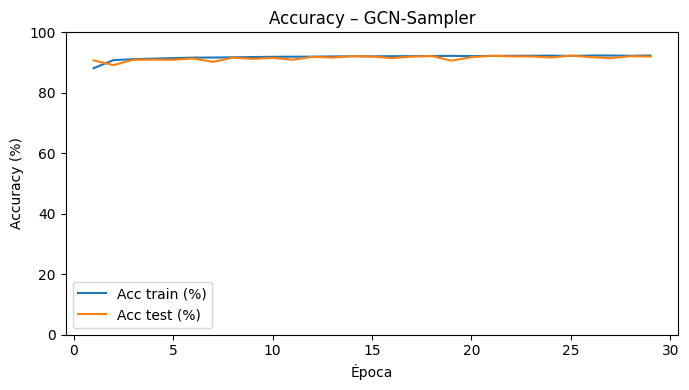

MAE = 0.1140 | R² = 0.6775

===== Entrenando SAGE-Sampler =====


  0%|          | 0/783 [00:00<?, ?it/s]/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/dgl/dataloading/dataloader.py:1144: DGLWarning: Dataloader CPU affinity opt is not enabled, consider switching it on (see enable_cpu_affinity() or CPU best practices for DGL [https://docs.dgl.ai/tutorials/cpu/cpu_best_practises.html])
  dgl_warning(
100%|██████████| 783/783 [00:13<00:00, 59.46it/s]


ep001 | loss_tr 0.3310 acc_tr 88.19% | loss_te 0.3080 acc_te 89.25%


100%|██████████| 783/783 [00:14<00:00, 55.34it/s]


ep005 | loss_tr 0.2476 acc_tr 91.51% | loss_te 0.2518 acc_te 91.36%


100%|██████████| 783/783 [00:15<00:00, 50.38it/s]


... (5 outputs left out)

100%|██████████| 783/783 [00:14<00:00, 54.29it/s]


ep025 | loss_tr 0.2275 acc_tr 92.17% | loss_te 0.2332 acc_te 92.15%


100%|██████████| 783/783 [00:14<00:00, 53.82it/s]


🛑  Early-stop en época 26
              precision    recall  f1-score   support

           0     0.9207    0.9804    0.9496    134042
           1     0.9073    0.7771    0.8372     30735
           2     0.9100    0.7832    0.8418     30735

    accuracy                         0.9174    195512
   macro avg     0.9127    0.8469    0.8762    195512
weighted avg     0.9169    0.9174    0.9150    195512

Matriz de confusión normalizada (%)


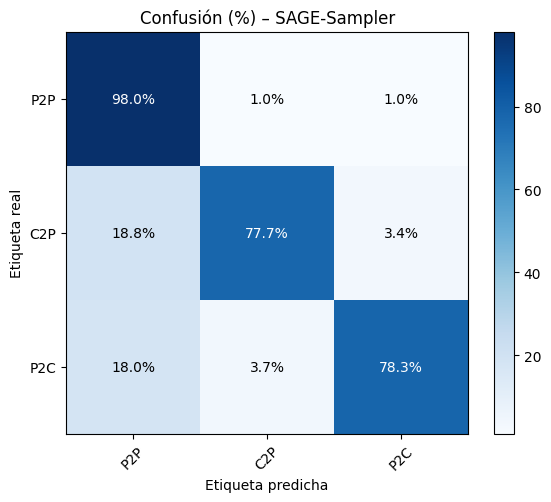

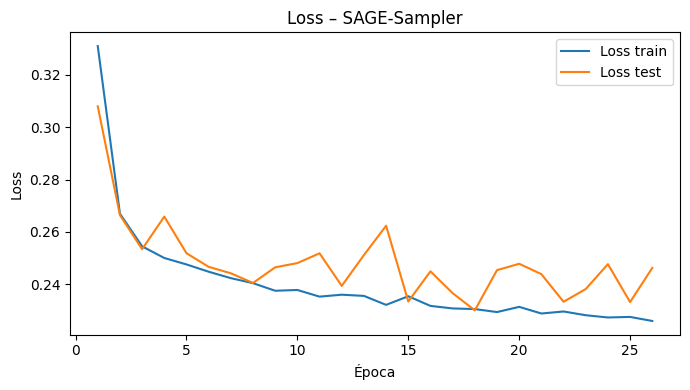

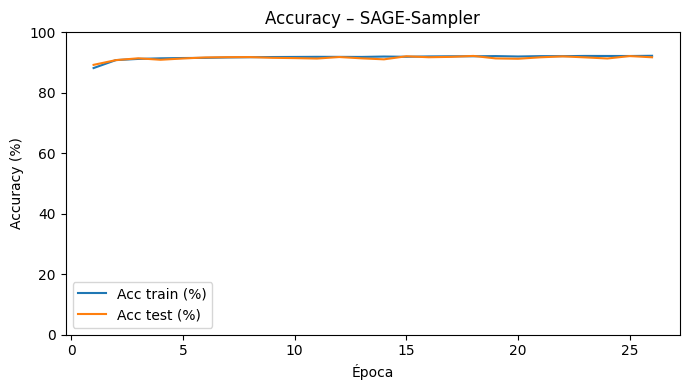

MAE = 0.1176 | R² = 0.6671

===== Entrenando GAT-Sampler =====


  0%|          | 0/783 [00:00<?, ?it/s]/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/dgl/dataloading/dataloader.py:1144: DGLWarning: Dataloader CPU affinity opt is not enabled, consider switching it on (see enable_cpu_affinity() or CPU best practices for DGL [https://docs.dgl.ai/tutorials/cpu/cpu_best_practises.html])
  dgl_warning(
100%|██████████| 783/783 [00:32<00:00, 23.90it/s]


ep001 | loss_tr 0.4017 acc_tr 85.79% | loss_te 0.3446 acc_te 87.87%


100%|██████████| 783/783 [00:30<00:00, 25.47it/s]


ep005 | loss_tr 0.2775 acc_tr 90.32% | loss_te 0.3117 acc_te 89.12%


100%|██████████| 783/783 [00:32<00:00, 24.42it/s]


... (3 outputs left out)

100%|██████████| 783/783 [00:40<00:00, 19.15it/s]


ep020 | loss_tr 0.2494 acc_tr 91.47% | loss_te 0.2589 acc_te 91.22%


100%|██████████| 783/783 [00:43<00:00, 17.84it/s]


🛑  Early-stop en época 23
              precision    recall  f1-score   support

           0     0.9598    0.8930    0.9252    134042
           1     0.7426    0.8622    0.7979     30735
           2     0.7475    0.8539    0.7972     30735

    accuracy                         0.8820    195512
   macro avg     0.8166    0.8697    0.8401    195512
weighted avg     0.8923    0.8820    0.8850    195512

Matriz de confusión normalizada (%)


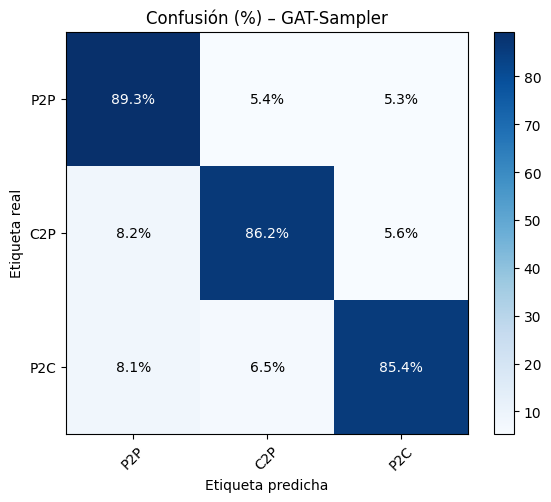

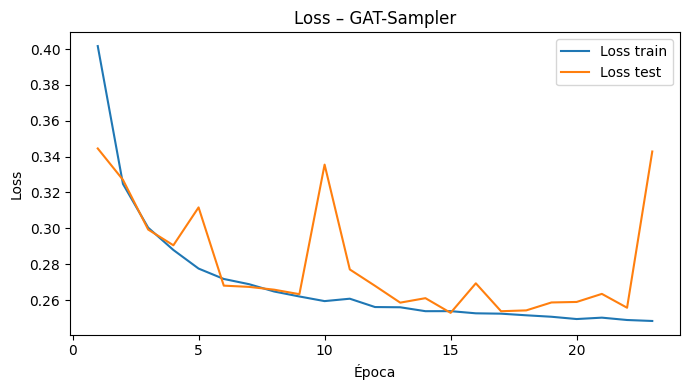

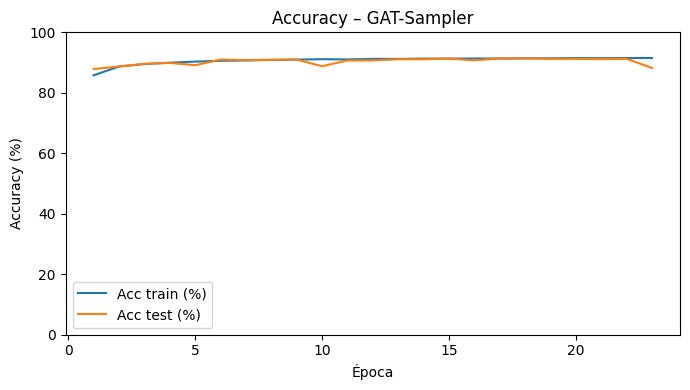

MAE = 0.1673 | R² = 0.5280


In [22]:
import tqdm, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, classification_report,
    mean_absolute_error, r2_score
)

# ─── hiperparámetros ───────────────────────────────────────────────
in_feats   = gnn.dgl_graph.ndata['feat'].shape[1]
hidden_dim = 64
emb_dim    = 32
n_classes  = 3
epochs     = 100
lr         = 0.01
patience   = 8
device     = "cuda" if torch.cuda.is_available() else "cpu"

# ─── bucle sobre modelos ───────────────────────────────────────────
for name, Model in models.items():
    print(f"\n===== Entrenando {name} =====")

    model = Model(in_feats, hidden_dim, emb_dim,
                  out_feats_mlp=n_classes).to(device)
    optim = torch.optim.Adam(model.parameters(), lr=lr)

    # almacenamos historial por época
    hist = {"loss_tr": [], "acc_tr": [], "loss_te": [], "acc_te": []}
    best_loss, best_state, wait = 1e9, None, 0         # early-stopping

    # ─── entrenamiento por época ────────────────────────────────
    for ep in range(1, epochs + 1):
        # ---- entrenamiento ------------------------------------
        model.train()
        loss_sum = corr = total = 0

        for input_nodes, output_graph, mfgs in tqdm.tqdm(
                train_dataloader):
            mfgs     = list(mfgs)
            edge_ids = output_graph.edata[dgl.EID].to(device)
            inputs        = mfgs[0].srcdata["feat"].to(device)
            y        = gnn.dgl_graph.edata["Relationship"][edge_ids].long().to(device)

            h       = model.encode(mfgs, inputs)               # (N_batch, emb_dim)
            logits  = model.decodeMLP(output_graph, h)    # (E_batch, 3)

            loss = F.cross_entropy(logits, y)
            optim.zero_grad();  loss.backward();  optim.step()

            # métrica de accuracy en batch
            pred = logits.argmax(1)
            corr += (pred == y).sum().item()
            total += len(y)
            loss_sum += loss.item() * len(y)

        loss_tr = loss_sum / total
        acc_tr  = 100 * corr / total

        # ---- validación ---------------------------------------
        model.eval()
        loss_sum = corr = total = 0
        preds_all, labels_all = [], []

        with torch.no_grad():
            for input_nodes, output_graph, mfgs in test_dataloader:
                mfgs     = list(mfgs)
                edge_ids = output_graph.edata[dgl.EID].to(device)
                inputs   = mfgs[0].srcdata["feat"].to(device)
                y        = gnn.dgl_graph.edata["Relationship"][edge_ids].long().to(device)

                h_val    = model.encode(mfgs, inputs)
                logits = model.decodeMLP(output_graph, h_val)

                loss_sum += F.cross_entropy(logits, y).item() * len(y)
                pred = logits.argmax(1)

                corr  += (pred == y).sum().item()
                total += len(y)

                preds_all.append(pred.cpu())
                labels_all.append(y.cpu())

        loss_te = loss_sum / total
        acc_te  = 100 * corr / total

        # ---- historial + early-stopping -----------------------
        hist["loss_tr"].append(loss_tr);  hist["loss_te"].append(loss_te)
        hist["acc_tr"].append(acc_tr);    hist["acc_te"].append(acc_te)

        if loss_te < best_loss - 1e-4:
            best_loss, wait = loss_te, 0
            best_state = {k: v.cpu() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑  Early-stop en época {ep}")
                break

        if ep % 5 == 0 or ep == 1:
            print(f"ep{ep:03d} | "
                  f"loss_tr {loss_tr:.4f} acc_tr {acc_tr:.2f}% | "
                  f"loss_te {loss_te:.4f} acc_te {acc_te:.2f}%")

    # ─── evaluación final (con mejor modelo) ─────────────────────
    model.load_state_dict(best_state)
    preds = torch.cat(preds_all)
    truth = torch.cat(labels_all)

    cm = confusion_matrix(truth, preds)
    print(classification_report(truth, preds, digits=4))

    plot_confusion_matrix_2(
        cm,
        classes=["P2P", "C2P", "P2C"],
        normalize=True,
        title=f"Confusión (%) – {name}",
        fname=f"img/resultados/gnn/end-to-end/{name.lower()}/cm_{name.lower()}",
        save=True  # cambia a False si no quieres guardarla
    )

    # ─── gráficos de historial ──────────────────────────────────
    ep_axis = range(1, len(hist["loss_tr"]) + 1)

    plt.figure(figsize=(7,4))
    plt.plot(ep_axis, hist["loss_tr"], label="Loss train")
    plt.plot(ep_axis, hist["loss_te"], label="Loss test")
    plt.xlabel("Época"); plt.ylabel("Loss"); plt.title(f"Loss – {name}")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(ep_axis, hist["acc_tr"], label="Acc train (%)")
    plt.plot(ep_axis, hist["acc_te"], label="Acc test (%)")
    plt.xlabel("Época"); plt.ylabel("Accuracy (%)"); plt.ylim(0,100)
    plt.title(f"Accuracy – {name}")
    plt.legend(); plt.tight_layout(); plt.show()

    # ─── métricas numéricas tipo MAE / R² (opcional) ─────────────
    mae = mean_absolute_error(truth, preds)
    r2  = r2_score(truth, preds)
    print(f"MAE = {mae:.4f} | R² = {r2:.4f}")


### Caso 5: Crear represetaciones de los nodos desde 0

In [5]:
models = {
    'GCN': GCN,
    'GraphSAGE': GraphSAGE,
    'GAT': GAT,
}

In [6]:
print("Total aristas:", gnn.dgl_graph.num_edges())
print("Training set:", train_m.sum().item())
print("Test set:", test_m.sum().item())
print("Intersección:", (train_m & test_m).sum().item())  # Debe ser 0



NameError: name 'gnn' is not defined

In [7]:
RELATIONSHIPS_FILE = '/home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2'
INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024/febrero'

gnn = GNN(debug=True)

# Cargo dataset y etiqueto sgun archivo de relaciones
gnn.load_dataset(
    data_path=INTERNETGRAPH_FILE,  # Grafo internet no etiquetado
    force_reload=True,
    index_graph = 1,  # Indice del grafo a cargar febrero
    simplify=True,            # ⇐ hazlo sólo una vez
    caida_path=RELATIONSHIPS_FILE  # Archivo CAIDA AS Relationships
)


# 64 features con poca varianza inicial
# gnn.add_random_features(dim=64, std=0.05, seed=42, mode="minmax")

# gnn.add_random_features(dim=64, std=0.05, seed=42, mode="zscore")

gnn.add_random_features(dim=64, std=0.05, seed=42, mode="uniform")


# crea máscaras + devuelve eids
train_eids, test_eids = gnn.split_edges_classification(0.8, seed=42, return_eids=True)

[load_dataset] Leyendo CSV …
Done saving data into cached files.
[load_dataset] Grafo Graph(num_nodes=42683, num_edges=157675438,
      ndata_schemes={'feat': Scheme(shape=(68,), dtype=torch.float32)}
      edata_schemes={})
[load_dataset] Simplificando  …
[load_dataset] Etiquetando CAIDA → /home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2


Etiquetando CAIDA: 488952it [00:00, 535082.77it/s]


[CAIDA] Añadidas 977288 aristas que faltaban
[CAIDA] Conteo final de etiquetas 0/1/2/-1 → Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
[load_dataset] etiquetas 0/1/2/-1 → Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
[add_random_features] feat ← (401308, 64)  |  mode=uniform
[split] train=782042  test=195512
  clases train: {0: 534690, 2: 123676, 1: 123676}


In [8]:
from torch import tensor

# contar la cantidad de ocurrencias por clase en las etiquetas de entrenamiento
train_labels = labels[train_m]
counts = torch.bincount(train_labels, minlength=n_classes)

# peso inverso a la frecuencia (opcionalmente se puede normalizar)
class_weights = 1.0 / counts.float()
class_weights = class_weights / class_weights.sum() * n_classes  # opcional: normalizar

class_weights = class_weights.to(device)


NameError: name 'labels' is not defined


=== Training GCN ===
ep01 | loss_tr 1.2531 acc_tr 15.81% | loss_te 1.1269 acc_te 15.72%
ep10 | loss_tr 0.6363 acc_tr 68.37% | loss_te 0.6651 acc_te 64.34%
ep20 | loss_tr 0.5830 acc_tr 70.81% | loss_te 0.5807 acc_te 70.73%
🛑  Early stop en época 22
Matriz de confusión sin normalizar


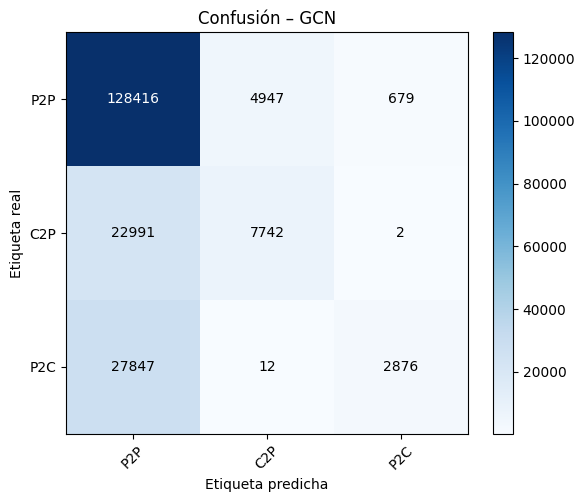

Matriz de confusión normalizada (%)


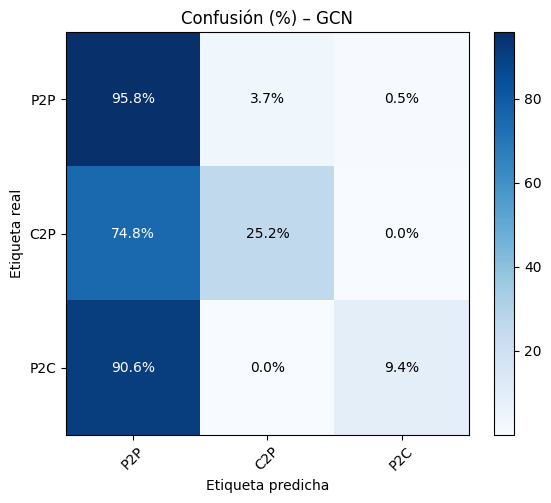

              precision    recall  f1-score   support

           0     0.7164    0.9580    0.8198    134042
           1     0.6096    0.2519    0.3565     30735
           2     0.8085    0.0936    0.1677     30735

    accuracy                         0.7111    195512
   macro avg     0.7115    0.4345    0.4480    195512
weighted avg     0.7141    0.7111    0.6444    195512



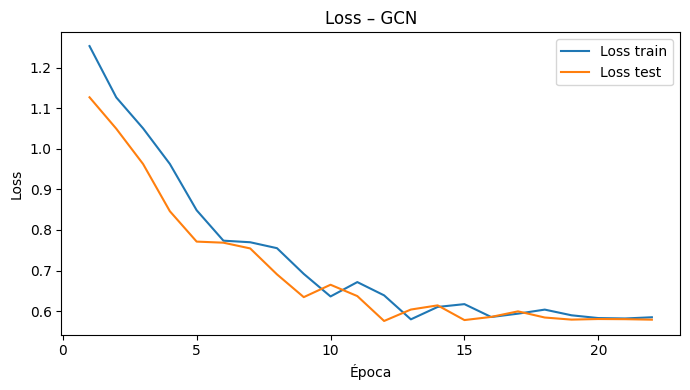

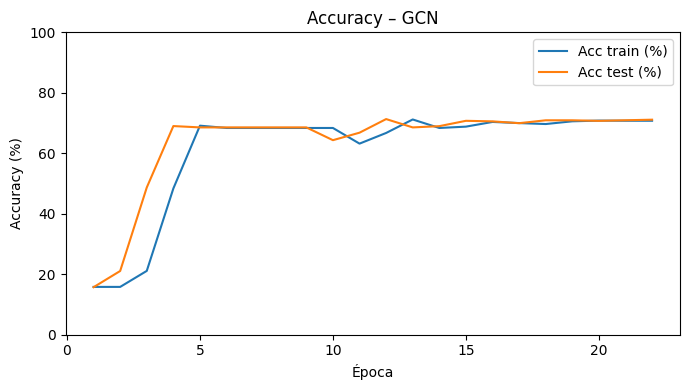


=== Training GraphSAGE ===
ep01 | loss_tr 1.2719 acc_tr 15.08% | loss_te 0.9673 acc_te 68.59%
ep10 | loss_tr 0.8501 acc_tr 68.37% | loss_te 0.8422 acc_te 68.56%
ep20 | loss_tr 0.8250 acc_tr 68.49% | loss_te 0.8430 acc_te 68.56%
ep30 | loss_tr 0.8008 acc_tr 70.19% | loss_te 0.8346 acc_te 68.56%
ep40 | loss_tr 0.7429 acc_tr 72.73% | loss_te 0.8320 acc_te 68.60%
ep50 | loss_tr 0.7361 acc_tr 72.54% | loss_te 0.8595 acc_te 68.56%
ep60 | loss_tr 0.7374 acc_tr 73.98% | loss_te 0.8456 acc_te 68.60%
🛑  Early stop en época 62
Matriz de confusión sin normalizar


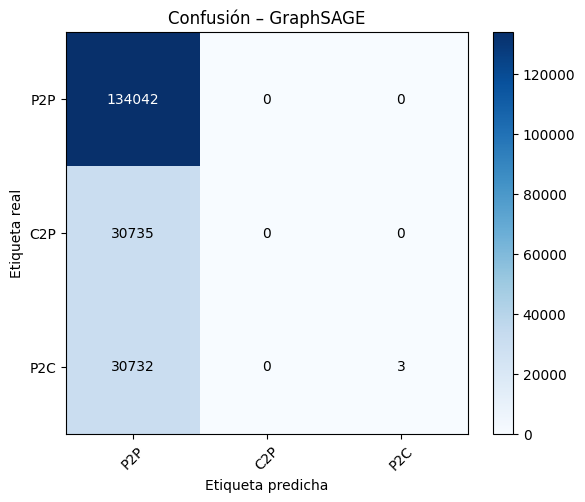

Matriz de confusión normalizada (%)


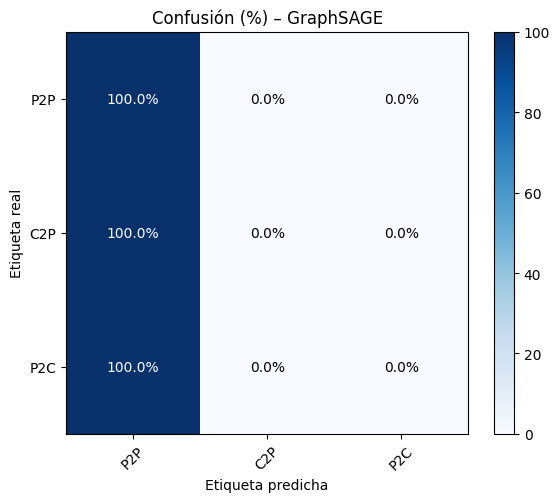

/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_

              precision    recall  f1-score   support

           0     0.6856    1.0000    0.8135    134042
           1     0.0000    0.0000    0.0000     30735
           2     1.0000    0.0001    0.0002     30735

    accuracy                         0.6856    195512
   macro avg     0.5619    0.3334    0.2712    195512
weighted avg     0.6272    0.6856    0.5578    195512



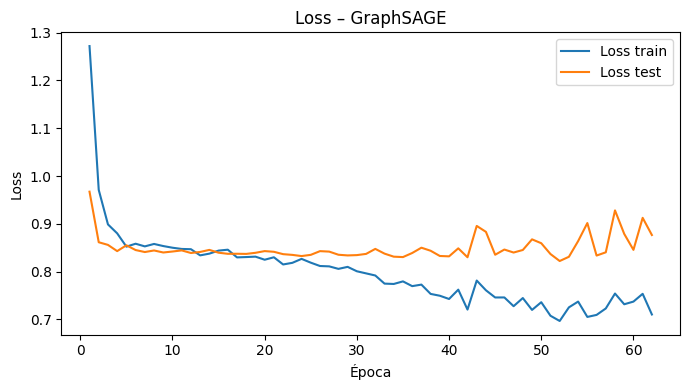

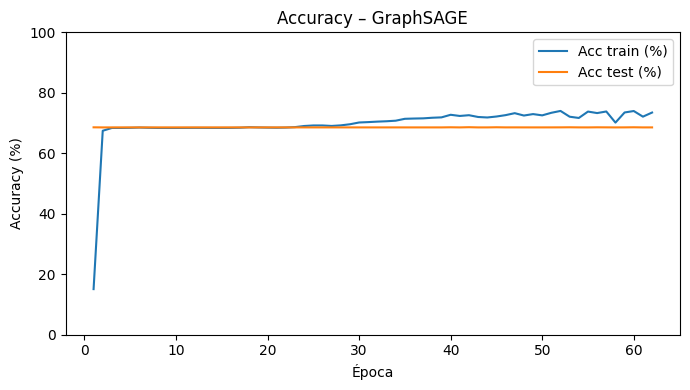


=== Training GAT ===
ep01 | loss_tr 1.0155 acc_tr 66.54% | loss_te 0.8441 acc_te 68.56%
ep10 | loss_tr 0.8434 acc_tr 68.37% | loss_te 0.8388 acc_te 68.56%
ep20 | loss_tr 0.8150 acc_tr 68.37% | loss_te 0.8208 acc_te 68.56%
ep30 | loss_tr 0.6599 acc_tr 70.77% | loss_te 0.6399 acc_te 72.34%
ep40 | loss_tr 0.5599 acc_tr 76.24% | loss_te 0.5857 acc_te 75.22%
ep50 | loss_tr 0.5078 acc_tr 79.59% | loss_te 0.5450 acc_te 77.54%
ep60 | loss_tr 0.4824 acc_tr 82.02% | loss_te 0.5569 acc_te 77.48%
ep70 | loss_tr 0.4169 acc_tr 85.03% | loss_te 0.5407 acc_te 77.19%
🛑  Early stop en época 71
Matriz de confusión sin normalizar


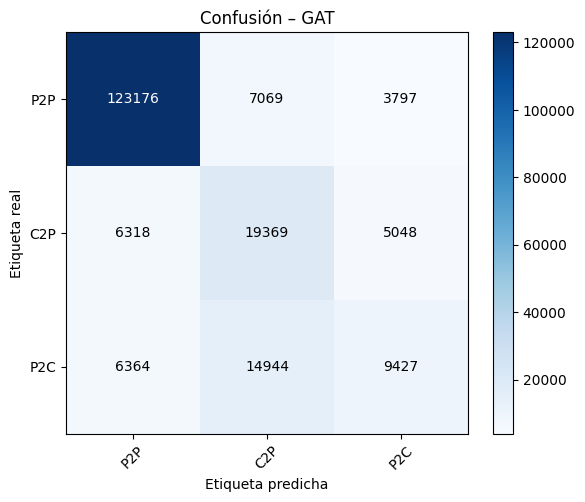

Matriz de confusión normalizada (%)


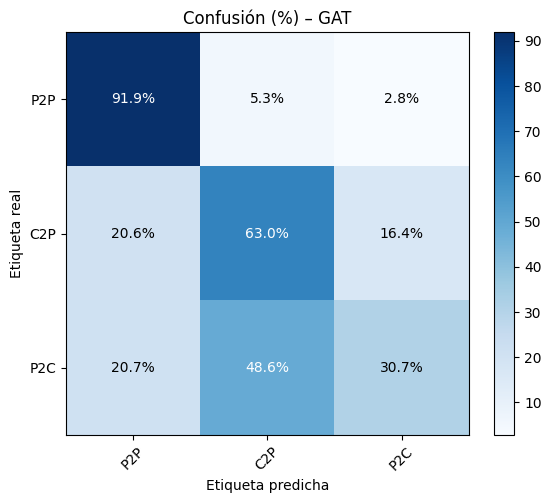

              precision    recall  f1-score   support

           0     0.9067    0.9189    0.9128    134042
           1     0.4681    0.6302    0.5372     30735
           2     0.5159    0.3067    0.3847     30735

    accuracy                         0.7773    195512
   macro avg     0.6302    0.6186    0.6115    195512
weighted avg     0.7763    0.7773    0.7707    195512



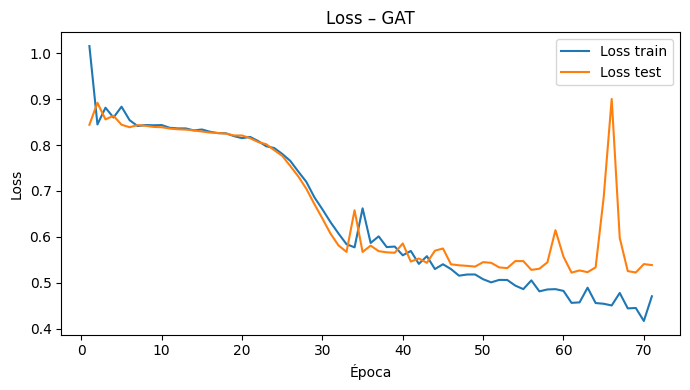

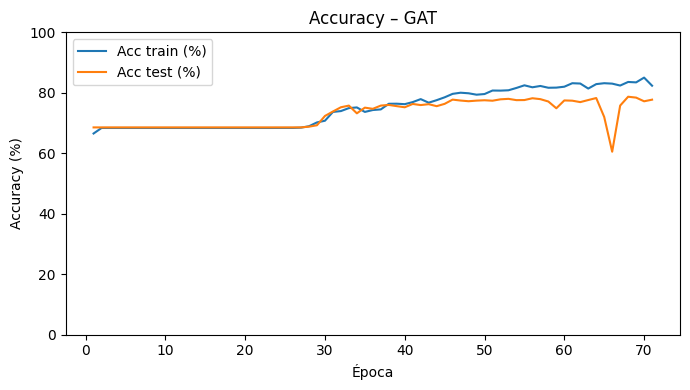

In [21]:
import torch, torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# ─── parámetros globales ────────────────────────────────────────────
in_feats  = gnn.dgl_graph.ndata["feat"].shape[1]
device    = "cuda" if torch.cuda.is_available() else "cpu"
epochs    = 200
lr        = 0.01
patience  = 10           # early-stopping
n_classes = 3

# ─── datos y máscaras ───────────────────────────────────────────────
g       = gnn.dgl_graph.to(device)
feat    = g.ndata["feat"].to(device)
labels  = g.edata["Relationship"].long().to(device)
train_m = g.edata["train_mask"].to(device)
test_m  = g.edata["test_mask"].to(device)

for name, Model in models.items():
    print(f"\n=== Training {name} ===")

    model = Model(in_feats, 32, 16, out_feats_mlp=n_classes).to(device)
    opt   = torch.optim.Adam(model.parameters() , lr=lr)

    # histórico por modelo
    hist = {"loss_tr": [], "acc_tr": [], "loss_te": [], "acc_te": []}
    best_loss, wait = 1e9, 0

    for ep in range(1, epochs + 1):
        # ---------- train ----------
        model.train()
        h      = model.encode(g, feat)
        logits = model.decodeMLP(g, h)                  # (E, 3)

        loss   = F.cross_entropy(logits[train_m], labels[train_m])
        # loss   = F.cross_entropy(logits[train_m], labels[train_m], weight=class_weights)

        
        opt.zero_grad() 
        loss.backward()
        opt.step()

        with torch.no_grad():
            preds_tr = logits[train_m].argmax(1)
            acc_tr   = (preds_tr == labels[train_m]).float().mean().item()

        # ---------- test ----------
        model.eval()
        with torch.no_grad():
            logits_t = model.decodeMLP(g, model.encode(g, feat))
            loss_te  = F.cross_entropy(logits_t[test_m], labels[test_m])
            # loss_te  = F.cross_entropy(logits_t[test_m], labels[test_m], weight=class_weights)
            preds_t  = logits_t[test_m].argmax(1)
            acc_t    = (preds_t == labels[test_m]).float().mean().item()

        # guarda histórico
        hist["loss_tr"].append(loss.item())
        hist["acc_tr"].append(acc_tr * 100)
        hist["loss_te"].append(loss_te.item())
        hist["acc_te"].append(acc_t * 100)

        # early-stopping
        if loss_te < best_loss - 1e-4:
            best_loss, wait = loss_te, 0
            best_w = model.state_dict()
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑  Early stop en época {ep}")
                break

        if ep % 10 == 0 or ep == 1:
            print(f"ep{ep:02d} | loss_tr {loss:.4f} acc_tr {acc_tr:.2%} | "
                  f"loss_te {loss_te:.4f} acc_te {acc_t:.2%}")

    # ---------- evaluación final ----------
    model.load_state_dict(best_w)
    with torch.no_grad():
        logits_best = model.decodeMLP(g, model.encode(g, feat))
        preds_best  = logits_best[test_m].argmax(1).cpu()
        truth       = labels[test_m].cpu()

    cm = confusion_matrix(truth, preds_best)
    plot_confusion_matrix_2(cm, ["P2P","C2P","P2C"], False,
                            title=f"Confusión – {name}")
    plot_confusion_matrix_2(cm, ["P2P","C2P","P2C"], True,
                            title=f"Confusión (%) – {name}")

    print(classification_report(truth, preds_best, digits=4))

    # ---------- curvas de entrenamiento ----------
    epochs_done = range(1, len(hist["loss_tr"]) + 1)

    plt.figure(figsize=(7,4))
    plt.plot(epochs_done, hist["loss_tr"], label="Loss train")
    plt.plot(epochs_done, hist["loss_te"], label="Loss test")
    plt.xlabel("Época"); plt.ylabel("Loss"); plt.title(f"Loss – {name}")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(epochs_done, hist["acc_tr"], label="Acc train (%)")
    plt.plot(epochs_done, hist["acc_te"], label="Acc test (%)")
    plt.xlabel("Época"); plt.ylabel("Accuracy (%)"); plt.ylim(0,100)
    plt.title(f"Accuracy – {name}")
    plt.legend(); plt.tight_layout(); plt.show()


Posibles arreglos:
Diferencia de arquitectura.

    GCN usa la matriz de adyacencia simétrica → capta información global
    rápidamente aun con features aleatorios.

    GraphSAGE (mean) y GAT agregan solamente vecinos; al inicio todos
    los nodos tienen casi el mismo vector aleatorio normalizado
    ⇒ el primer paso de agregación produce embeddings muy parecidos en todas
    partes ⇒ el gradiente se vuelve más pequeño que en GCN y cuesta salir del
    mínimo “todo-P2P”.

Falta de self-loop en SAGE y GAT.
Al no sumar la propia característica el “mensaje” inicial puede diluirse
aún más. (GCN lo incorpora por defecto en tu código).

Función de pérdida sin ponderar.
F.cross_entropy default = ponderación uniforme → la clase mayoritaria
domina.


=== GCN ===
ep001 | loss_tr 1.0974 acc_tr 37.95% | loss_te 1.0571 acc_te 65.11%
ep020 | loss_tr 0.8369 acc_tr 45.07% | loss_te 0.9466 acc_te 21.06%
ep040 | loss_tr 0.7682 acc_tr 58.46% | loss_te 0.8577 acc_te 40.43%
ep060 | loss_tr 0.6388 acc_tr 79.71% | loss_te 0.6501 acc_te 86.80%
ep080 | loss_tr 0.4850 acc_tr 90.14% | loss_te 0.4457 acc_te 94.78%
ep100 | loss_tr 0.3873 acc_tr 90.96% | loss_te 0.3368 acc_te 95.71%
ep120 | loss_tr 0.3431 acc_tr 92.61% | loss_te 0.2720 acc_te 95.79%
Matriz de confusión sin normalizar


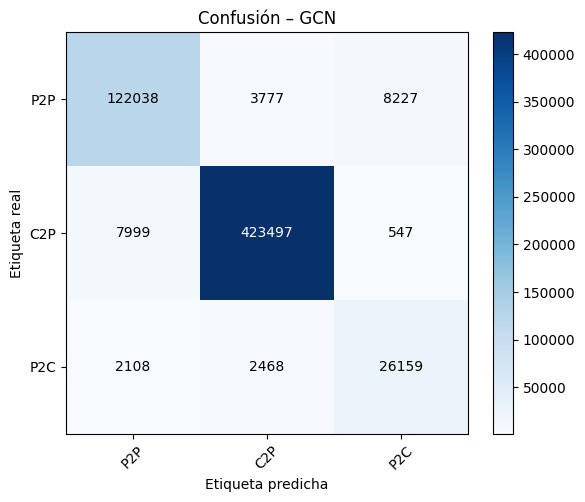

Matriz de confusión normalizada (%)


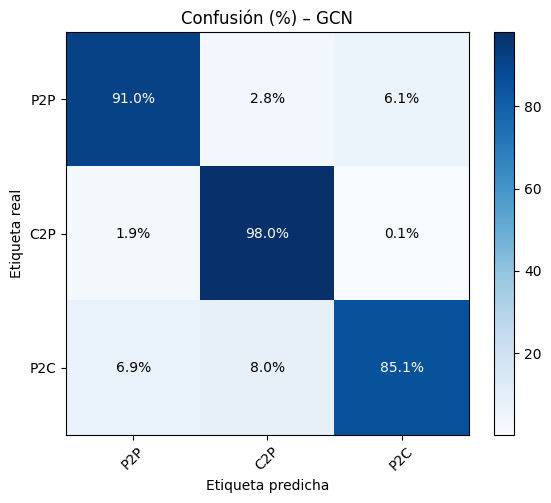

              precision    recall  f1-score   support

           0     0.9235    0.9104    0.9169    134042
           1     0.9855    0.9802    0.9828    432043
           2     0.7488    0.8511    0.7967     30735

    accuracy                         0.9579    596820
   macro avg     0.8859    0.9139    0.8988    596820
weighted avg     0.9594    0.9579    0.9585    596820



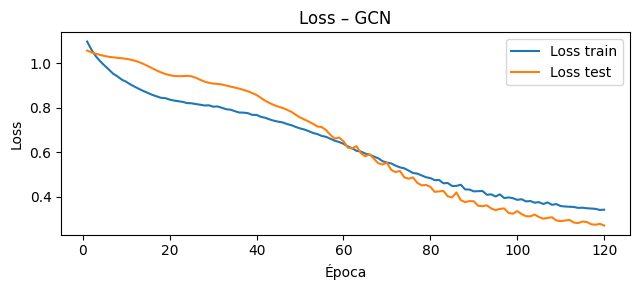

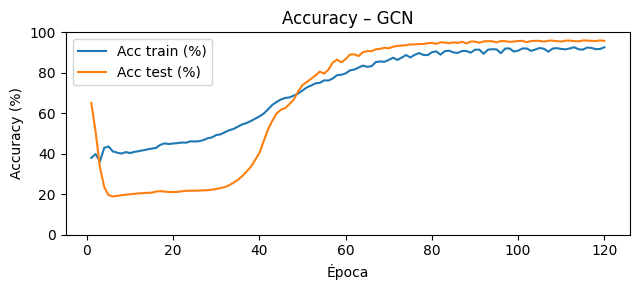


=== GraphSAGE ===
ep001 | loss_tr 1.1947 acc_tr 46.58% | loss_te 1.0355 acc_te 56.14%
🛑  Early-stop en época 11
Matriz de confusión sin normalizar


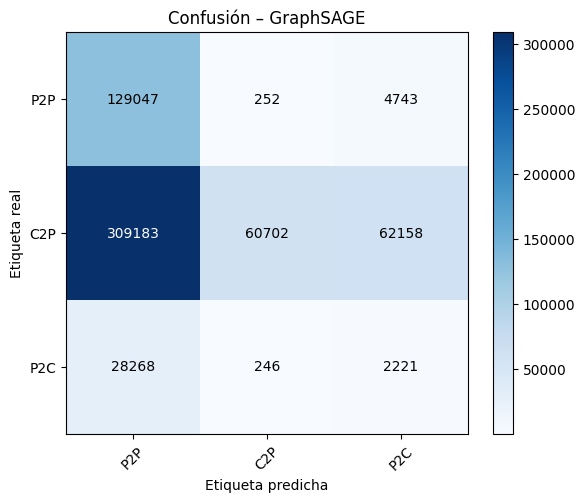

Matriz de confusión normalizada (%)


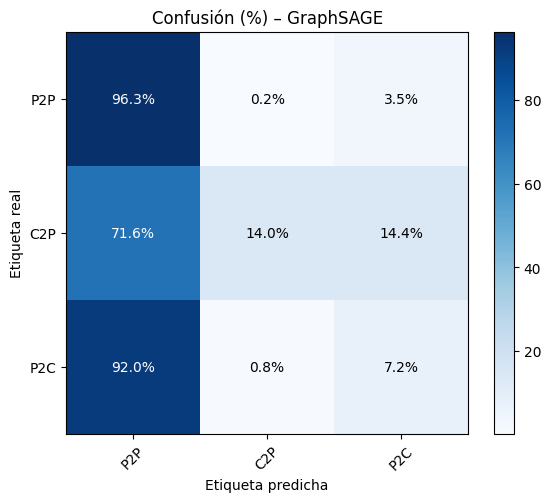

              precision    recall  f1-score   support

           0     0.2766    0.9627    0.4298    134042
           1     0.9919    0.1405    0.2461    432043
           2     0.0321    0.0723    0.0445     30735

    accuracy                         0.3217    596820
   macro avg     0.4335    0.3918    0.2401    596820
weighted avg     0.7818    0.3217    0.2770    596820



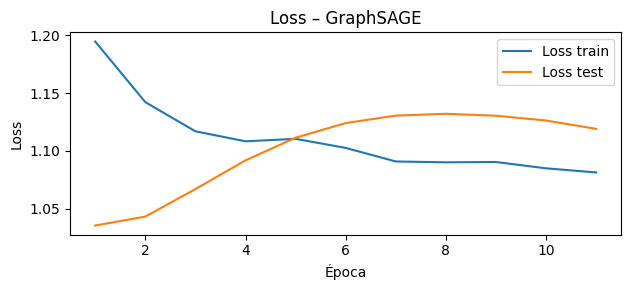

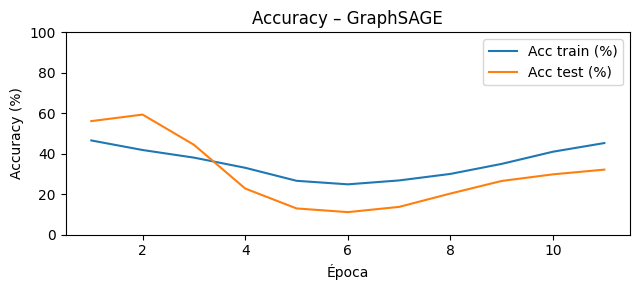


=== GAT ===
ep001 | loss_tr 1.1110 acc_tr 40.24% | loss_te 1.0475 acc_te 66.97%
ep020 | loss_tr 0.9664 acc_tr 73.15% | loss_te 0.9401 acc_te 72.97%
ep040 | loss_tr 0.7444 acc_tr 79.01% | loss_te 0.9119 acc_te 72.39%
🛑  Early-stop en época 42
Matriz de confusión sin normalizar


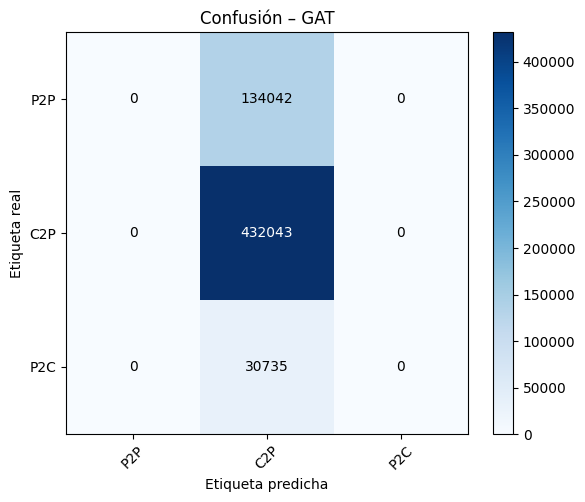

Matriz de confusión normalizada (%)


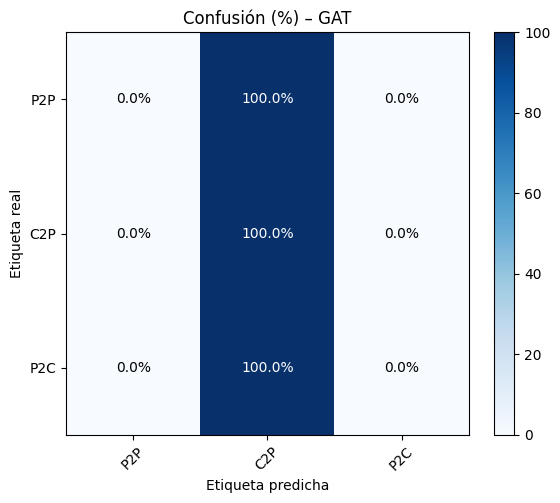

/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_

              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000    134042
           1     0.7239    1.0000    0.8398    432043
           2     0.0000    0.0000    0.0000     30735

    accuracy                         0.7239    596820
   macro avg     0.2413    0.3333    0.2799    596820
weighted avg     0.5240    0.7239    0.6080    596820



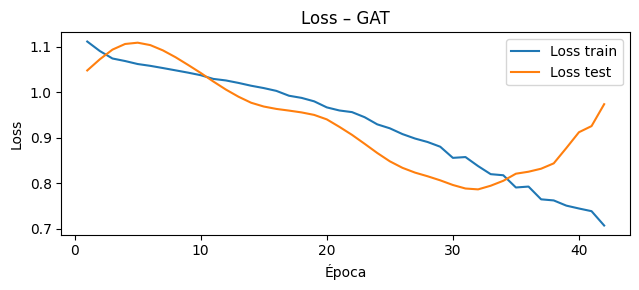

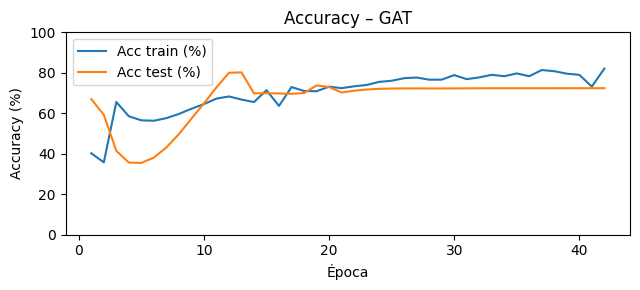

In [9]:
# version arreglada por chatgpt

import torch, torch.nn.functional as F
from collections import Counter
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

# ─── configuración general ─────────────────────────────────────────
device   = "cuda" if torch.cuda.is_available() else "cpu"
g        = gnn.dgl_graph
g = dgl.add_self_loop(g)
g = g.to(device)

x        = g.ndata['feat'].to(device)
y        = g.edata['Relationship'].long().to(device)
tr, te   = g.edata['train_mask'], g.edata['test_mask']

# pesos inversos al nº de ejemplos por clase (0,1,2)
cnt      = Counter(y[tr].tolist())
w_cls    = torch.tensor([1/cnt[i] for i in range(3)], device=device, dtype=torch.float)

epochs   = 120
lr       = 1e-3          # algo más bajo ayuda a SAGE/GAT
patience = 10

# ─── entrenamiento por cada arquitectura ───────────────────────────
for name, Model in models.items():          # GCN, GraphSAGE, GAT …
    print(f"\n=== {name} ===")
    model = Model(x.shape[1], 64, 32, out_feats_mlp=3).to(device)
    opt   = torch.optim.Adam(model.parameters(), lr=lr)

    hist  = {'ltr':[], 'lte':[], 'atr':[], 'ate':[]}
    best_loss, wait, best_w = 1e9, 0, None

    for ep in range(1, epochs + 1):
        # -------- train --------
        model.train()
        logits = model.decodeMLP(g, model.encode(g, x))
        loss   = F.cross_entropy(logits[tr], y[tr], weight=w_cls)

        opt.zero_grad(); loss.backward(); opt.step()

        with torch.no_grad():
            pred_tr = logits[tr].argmax(1)
            acc_tr  = (pred_tr == y[tr]).float().mean().item()*100

        # -------- test ---------
        model.eval()
        with torch.no_grad():
            logits_t = model.decodeMLP(g, model.encode(g, x))
            loss_te  = F.cross_entropy(logits_t[te], y[te], weight=w_cls)
            pred_te  = logits_t[te].argmax(1)
            acc_te   = (pred_te == y[te]).float().mean().item()*100

        # -------- histórico ----
        hist['ltr'].append(loss.item()) ; hist['lte'].append(loss_te.item())
        hist['atr'].append(acc_tr)       ; hist['ate'].append(acc_te)

        # -------- early-stop ----
        if loss_te < best_loss - 1e-4:
            best_loss, wait, best_w = loss_te, 0, {k:v.cpu() for k,v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑  Early-stop en época {ep}")
                break

        if ep % 20 == 0 or ep == 1:
            print(f"ep{ep:03d} | loss_tr {loss:.4f} acc_tr {acc_tr:5.2f}% | "
                  f"loss_te {loss_te:.4f} acc_te {acc_te:5.2f}%")

    # ─── evaluación final ───────────────────────────────────────────
    model.load_state_dict(best_w, strict=False)
    with torch.no_grad():
        logits_best = model.decodeMLP(g, model.encode(g, x))
        preds_best  = logits_best[te].argmax(1).cpu()
        truth       = y[te].cpu()

    # matriz de confusión
    cm = confusion_matrix(truth, preds_best)
    plot_confusion_matrix_2(cm, ["P2P","C2P","P2C"], False,
                            title=f"Confusión – {name}")
    plot_confusion_matrix_2(cm, ["P2P","C2P","P2C"], True,
                            title=f"Confusión (%) – {name}")
    print(classification_report(truth, preds_best, digits=4))

    # curvas
    ep_axis = range(1, len(hist['ltr'])+1)
    plt.figure(figsize=(6.5,3))
    plt.plot(ep_axis, hist['ltr'], label='Loss train')
    plt.plot(ep_axis, hist['lte'], label='Loss test')
    plt.xlabel('Época'); plt.ylabel('Loss'); plt.title(f'Loss – {name}')
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(6.5,3))
    plt.plot(ep_axis, hist['atr'], label='Acc train (%)')
    plt.plot(ep_axis, hist['ate'], label='Acc test (%)')
    plt.xlabel('Época'); plt.ylabel('Accuracy (%)'); plt.ylim(0,100)
    plt.title(f'Accuracy – {name}')
    plt.legend(); plt.tight_layout(); plt.show()


### Caso 4: Utilizando metodo de sampling Cluster batch normalization

parte el grafo en K clusters disjuntos y cada
mini-batch es todo un cluster (no un bloque‐vecinos).

|                              | NeighborSampler (antes)                      | ClusterGCNSampler (ahora)                                                                 |
| ---------------------------- | -------------------------------------------- | ----------------------------------------------------------------------------------------- |
| lo que devuelve `DataLoader` | `(input_nodes, pair_graph, blocks)`          | **un único subgrafo** `subg`                                                              |
| cómo llamo al `encode`       | `model.encode(blocks, x)` (lista de bloques) | `model.encode([subg], x)` **o** `model.encode(subg, x)` si tu `encode` acepta un DGLGraph |


In [5]:
from modules.gnn_models import GCNSampler, GraphSAGESample, GATSample

models = {
    "GCN-Sampler":  GCNSampler,
    "SAGE-Sampler": GraphSAGESample,
    "GAT-Sampler":  GATSample
}


In [7]:
RELATIONSHIPS_FILE = '/home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2'
INTERNETGRAPH_FILE = '/media/valentina/KINGSTON/TESIS/InternetGraphs2024/febrero'

gnn = GNN(debug=True)

# Cargo dataset y etiqueto sgun archivo de relaciones
gnn.load_dataset(
    data_path=INTERNETGRAPH_FILE,  # Grafo internet no etiquetado
    force_reload=True,
    index_graph = 1,  # Indice del grafo a cargar febrero
    simplify=True,            # ⇐ hazlo sólo una vez
    caida_path=RELATIONSHIPS_FILE  # Archivo CAIDA AS Relationships
)

gnn.split_edges_classification(train_size=0.8, seed=42)


[load_dataset] Leyendo CSV …
Done saving data into cached files.
[load_dataset] Grafo Graph(num_nodes=42683, num_edges=157675438,
      ndata_schemes={'feat': Scheme(shape=(68,), dtype=torch.float32)}
      edata_schemes={})
[load_dataset] Simplificando  …
[load_dataset] Etiquetando CAIDA → /home/valentina/Desktop/GIT/TrabajoTesis/data/CAIDA_AS_Relationships/Serial_1/20240201.as-rel.txt.bz2


Etiquetando CAIDA: 488952it [00:00, 495232.16it/s]


[CAIDA] Añadidas 977288 aristas que faltaban
[CAIDA] Conteo final de etiquetas 0/1/2/-1 → Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
[load_dataset] etiquetas 0/1/2/-1 → Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
[split] train=782042  test=195512
  clases train: {0: 534690, 2: 123676, 1: 123676}


In [11]:
import os
if os.path.exists("cluster_gcn.pkl"):
    os.remove("cluster_gcn.pkl")


In [12]:

num_parts = 1000                       # ajusta tamaño de cluster
device    = "cuda" if torch.cuda.is_available() else "cpu"

# ① sampler
sampler = dgl.dataloading.ClusterGCNSampler(
            gnn.dgl_graph, num_parts,
            prefetch_ndata=['feat'],
            prefetch_edata=['Relationship', 'train_mask', 'test_mask']
            )

# ② índices de clusters = 0 … (num_parts-1)
cluster_ids = torch.arange(num_parts)

# ③ DataLoader de entrenamiento  (shufle = True)
train_loader = dgl.dataloading.DataLoader(
        gnn.dgl_graph, cluster_ids, sampler,
        batch_size=1, shuffle=True, drop_last=False, device=device)

# ④ DataLoader de test             (sin barajar)
test_loader  = dgl.dataloading.DataLoader(
        gnn.dgl_graph, cluster_ids, sampler,
        batch_size=1, shuffle=False, drop_last=False, device=device)


Convert a graph into a bidirected graph: 0.045 seconds, peak memory: 15.795 GB
Construct multi-constraint weights: 0.000 seconds, peak memory: 15.795 GB
Metis partitioning: 1.818 seconds, peak memory: 15.795 GB


[11:32:16] /opt/dgl/src/graph/transform/metis_partition_hetero.cc:89: Partition a graph with 401308 nodes and 1676600 edges into 1000 parts and get 677758 edge cuts


Cada iteración entrega subg, un subgrafo que contiene todos los
nodos y aristas de un cluster.


===== Entrenando GCN-Sampler =====


Epoch 001:   0%|          | 0/1000 [00:00<?, ?it/s]/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/dgl/dataloading/dataloader.py:1144: DGLWarning: Dataloader CPU affinity opt is not enabled, consider switching it on (see enable_cpu_affinity() or CPU best practices for DGL [https://docs.dgl.ai/tutorials/cpu/cpu_best_practises.html])
  dgl_warning(
/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/dgl/core.py:82: DGLWarning: The input graph for the user-defined edge function does not contain valid edges
  dgl_warning(


ep001 | loss_tr nan acc_tr 63.54% | loss_te nan acc_te 62.21%


ep005 | loss_tr nan acc_tr 63.92% | loss_te nan acc_te 63.42%


ep010 | loss_tr nan acc_tr 65.68% | loss_te nan acc_te 65.01%


ep015 | loss_tr nan acc_tr 80.87% | loss_te nan acc_te 79.93%


ep020 | loss_tr nan acc_tr 87.15% | loss_te nan acc_te 85.71%


ep025 | loss_tr nan acc_tr 87.54% | loss_te nan acc_te 88.86%


ep030 | loss_tr nan acc_tr 87.99% | loss_te nan acc_te 88.28%


ep035 | loss_tr nan acc_tr 88.58% | loss_te nan acc_te 88.71%


🛑  Early-stop en época 40
Matriz de confusión sin normalizar


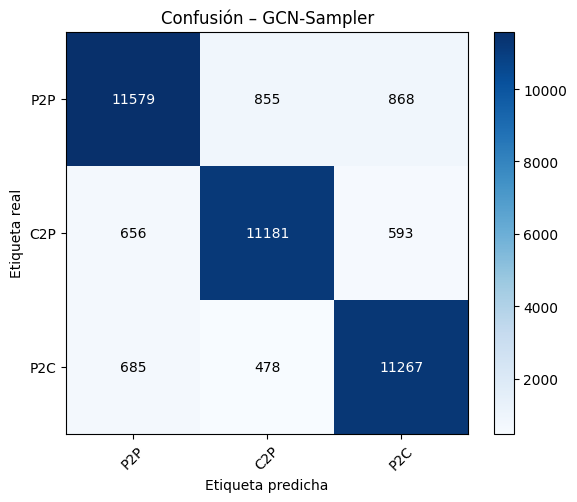

Matriz de confusión normalizada (%)


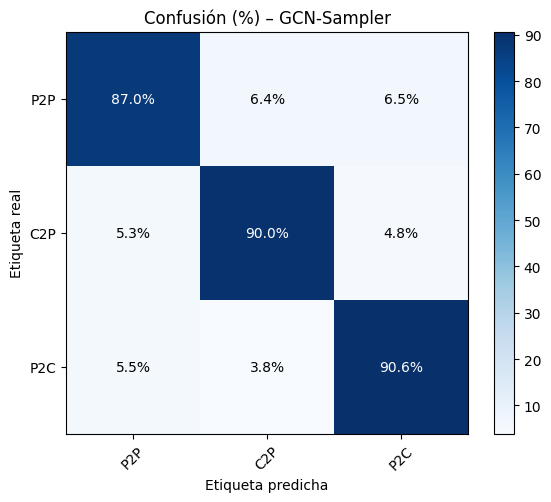

              precision    recall  f1-score   support

           0     0.8962    0.8705    0.8832     13302
           1     0.8935    0.8995    0.8965     12430
           2     0.8852    0.9064    0.8957     12430

    accuracy                         0.8916     38162
   macro avg     0.8916    0.8921    0.8918     38162
weighted avg     0.8917    0.8916    0.8916     38162



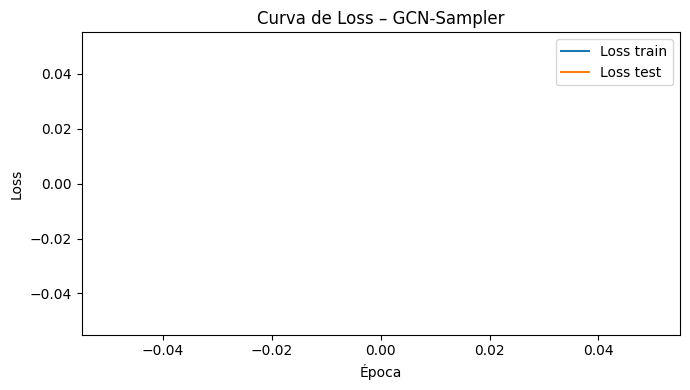

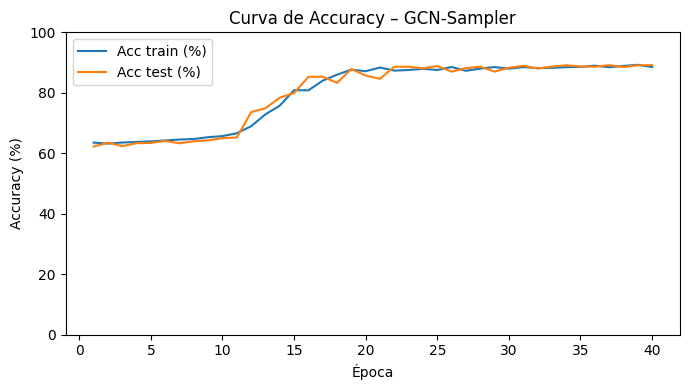


===== Entrenando SAGE-Sampler =====


Epoch 001:   0%|          | 0/1000 [00:00<?, ?it/s]/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/dgl/dataloading/dataloader.py:1144: DGLWarning: Dataloader CPU affinity opt is not enabled, consider switching it on (see enable_cpu_affinity() or CPU best practices for DGL [https://docs.dgl.ai/tutorials/cpu/cpu_best_practises.html])
  dgl_warning(
/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/dgl/core.py:82: DGLWarning: The input graph for the user-defined edge function does not contain valid edges
  dgl_warning(


ep001 | loss_tr nan acc_tr 61.64% | loss_te nan acc_te 62.34%


ep005 | loss_tr nan acc_tr 63.94% | loss_te nan acc_te 62.93%


ep010 | loss_tr nan acc_tr 66.37% | loss_te nan acc_te 66.99%


ep015 | loss_tr nan acc_tr 84.57% | loss_te nan acc_te 86.29%


ep020 | loss_tr nan acc_tr 86.57% | loss_te nan acc_te 85.17%


ep025 | loss_tr nan acc_tr 87.96% | loss_te nan acc_te 88.00%


ep030 | loss_tr nan acc_tr 87.61% | loss_te nan acc_te 88.09%


ep035 | loss_tr nan acc_tr 88.66% | loss_te nan acc_te 89.18%


🛑  Early-stop en época 40
Matriz de confusión sin normalizar


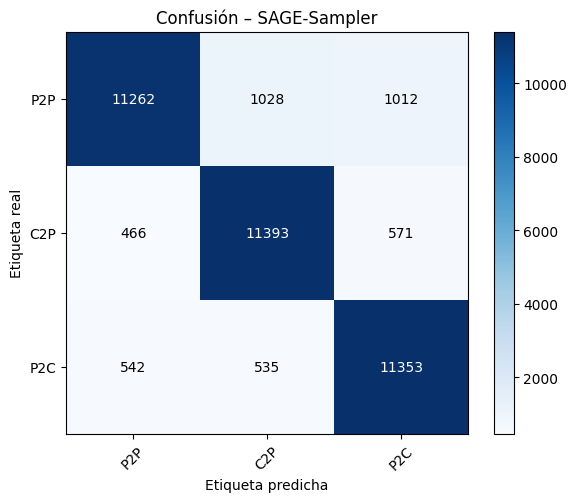

Matriz de confusión normalizada (%)


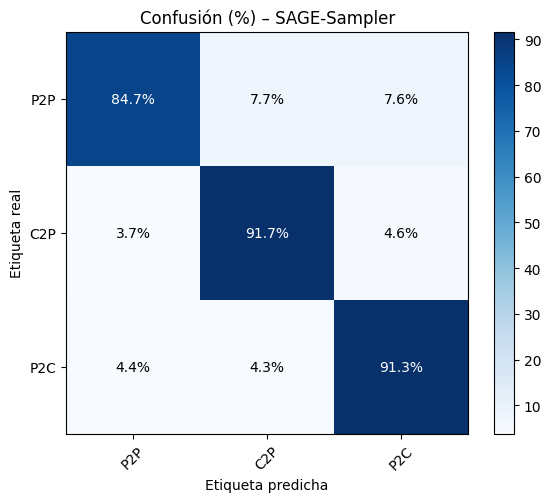

              precision    recall  f1-score   support

           0     0.9178    0.8466    0.8808     13302
           1     0.8794    0.9166    0.8976     12430
           2     0.8776    0.9134    0.8951     12430

    accuracy                         0.8911     38162
   macro avg     0.8916    0.8922    0.8912     38162
weighted avg     0.8922    0.8911    0.8909     38162



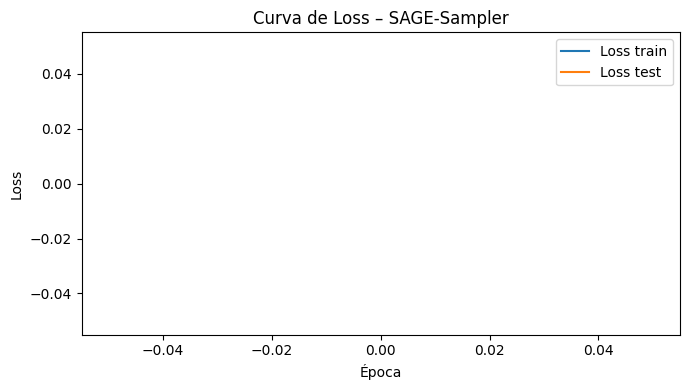

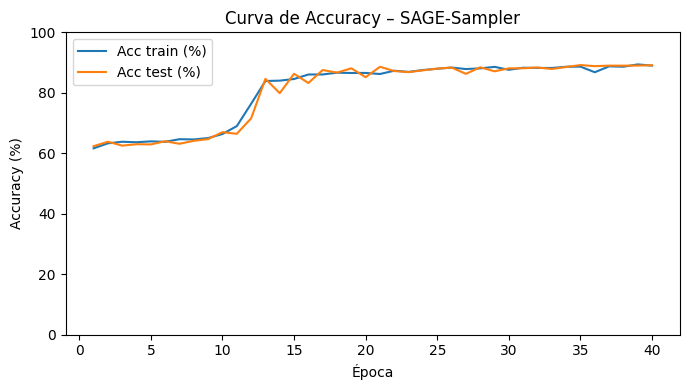


===== Entrenando GAT-Sampler =====


Epoch 001:   0%|          | 0/1000 [00:00<?, ?it/s]/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/dgl/dataloading/dataloader.py:1144: DGLWarning: Dataloader CPU affinity opt is not enabled, consider switching it on (see enable_cpu_affinity() or CPU best practices for DGL [https://docs.dgl.ai/tutorials/cpu/cpu_best_practises.html])
  dgl_warning(
/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/dgl/core.py:82: DGLWarning: The input graph for the user-defined edge function does not contain valid edges
  dgl_warning(


ep001 | loss_tr nan acc_tr 45.61% | loss_te nan acc_te 49.14%


ep005 | loss_tr nan acc_tr 50.65% | loss_te nan acc_te 50.26%


ep010 | loss_tr nan acc_tr 73.99% | loss_te nan acc_te 71.04%


ep015 | loss_tr nan acc_tr 75.73% | loss_te nan acc_te 76.62%


ep020 | loss_tr nan acc_tr 76.11% | loss_te nan acc_te 77.43%


ep025 | loss_tr nan acc_tr 77.62% | loss_te nan acc_te 76.67%


ep030 | loss_tr nan acc_tr 77.80% | loss_te nan acc_te 78.15%


ep035 | loss_tr nan acc_tr 77.34% | loss_te nan acc_te 78.28%


🛑  Early-stop en época 40
Matriz de confusión sin normalizar


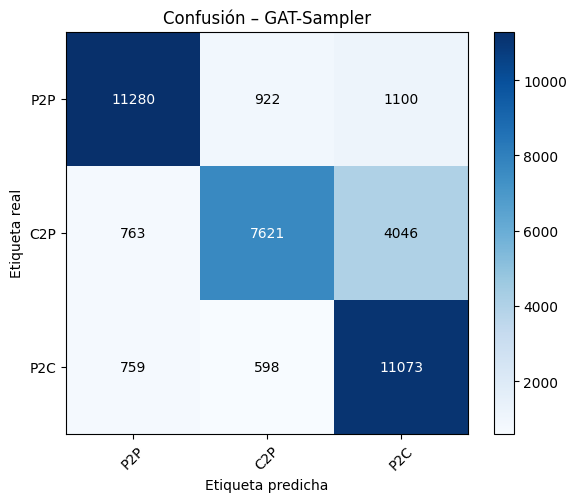

Matriz de confusión normalizada (%)


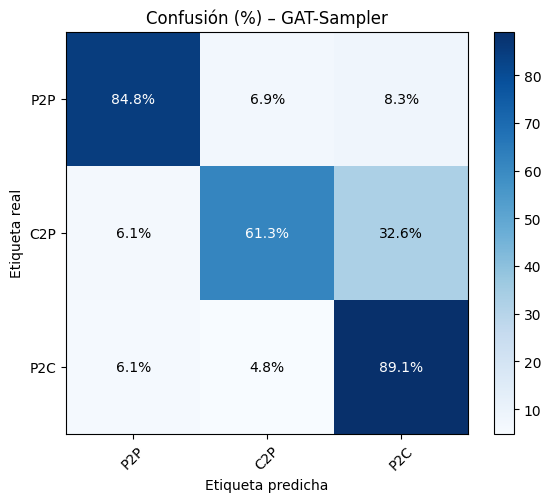

              precision    recall  f1-score   support

           0     0.8811    0.8480    0.8642     13302
           1     0.8337    0.6131    0.7066     12430
           2     0.6827    0.8908    0.7730     12430

    accuracy                         0.7854     38162
   macro avg     0.7992    0.7840    0.7813     38162
weighted avg     0.8011    0.7854    0.7832     38162



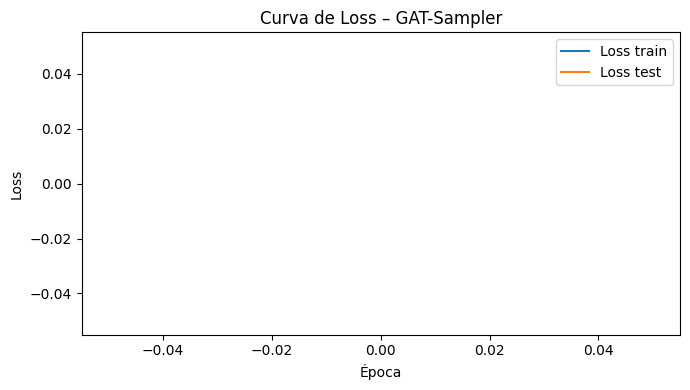

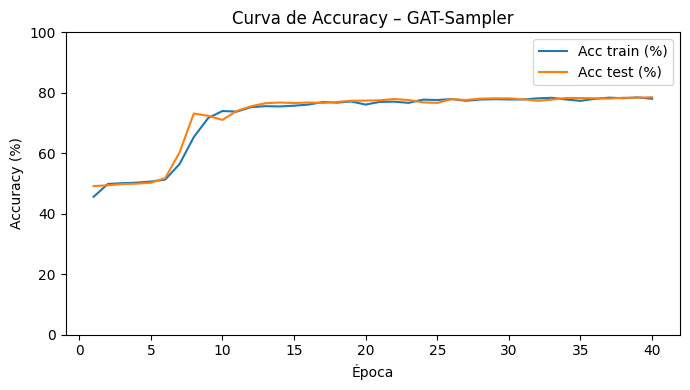

In [13]:
from tqdm.auto import tqdm
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# ─── hiper-parámetros ──────────────────────────────────────────────
in_feats  = gnn.dgl_graph.ndata['feat'].shape[1]
device    = "cuda" if torch.cuda.is_available() else "cpu"
epochs    = 50
lr        = 1e-3
patience  = 40               # early-stopping
n_classes = 3

# ─── loop sobre modelos ────────────────────────────────────────────
for name, Model in models.items():
    print(f"\n===== Entrenando {name} =====")

    model = Model(in_feats, 64, 32, out_feats_mlp=n_classes).to(device)
    optim = torch.optim.Adam(model.parameters(), lr=lr)

    # historial
    hist = {"loss_tr": [], "acc_tr": [], "loss_te": [], "acc_te": []}
    best_loss, best_state, wait = 1e9, None, 0

    for epoch in range(1, epochs + 1):

        # ── TRAIN ───────────────────────────────────────────────────
        model.train()
        loss_sum = corr = tot = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch:03d}", leave=False)
        for subg in pbar:                    # subg = grafo de un cluster
            if subg.num_edges() == 0:
                continue 
            subg = subg.to(device)
            x    = subg.ndata['feat'].float()
            y    = subg.edata['Relationship'].long()
            m    = subg.edata['train_mask'].bool()

            h      = model.encode(subg, x)          # <- nota: grafo completo
            logits = model.decodeMLP(subg, h)       # (E_cluster, 3)

            loss = F.cross_entropy(logits[m], y[m])

            optim.zero_grad()
            loss.backward()
            optim.step()

            # métrica batch
            loss_sum += loss.item() * m.sum().item()
            pred      = logits[m].argmax(1)
            corr     += (pred == y[m]).sum().item()
            tot      += m.sum().item()

        loss_tr = loss_sum / tot
        acc_tr  = 100 * corr / tot

        # ── TEST ────────────────────────────────────────────────────
        model.eval()
        loss_sum = corr = tot = 0
        preds_all, truth_all = [], []

        with torch.no_grad():
            for subg in test_loader:
                subg = subg.to(device)
                x    = subg.ndata['feat'].float()
                y    = subg.edata['Relationship'].long()
                m    = subg.edata['test_mask'].bool()

                h      = model.encode(subg, x)
                logits = model.decodeMLP(subg, h)

                loss_sum += F.cross_entropy(logits[m], y[m]).item() * m.sum().item()
                pred      = logits[m].argmax(1)

                corr += (pred == y[m]).sum().item()
                tot  += m.sum().item()
                preds_all.append(pred.cpu())
                truth_all.append(y[m].cpu())

        loss_te = loss_sum / tot
        acc_te  = 100 * corr / tot

        # ── historial + early-stopping ─────────────────────────────
        hist['loss_tr'].append(loss_tr);  hist['loss_te'].append(loss_te)
        hist['acc_tr'].append(acc_tr);    hist['acc_te'].append(acc_te)

        if loss_te < best_loss - 1e-4:
            best_loss, wait = loss_te, 0
            best_state = {k: v.cpu() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                print(f"🛑  Early-stop en época {epoch}")
                break

        if epoch % 5 == 0 or epoch == 1:
            print(f"ep{epoch:03d} | "
                  f"loss_tr {loss_tr:.4f} acc_tr {acc_tr:.2f}% | "
                  f"loss_te {loss_te:.4f} acc_te {acc_te:.2f}%")

    # ─── evaluación final ──────────────────────────────────────────
    if best_state is None:                      # por si nunca mejoró
        best_state = {k: v.cpu() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)

    preds = torch.cat(preds_all)
    truth = torch.cat(truth_all)

    cm = confusion_matrix(truth, preds)
    plot_confusion_matrix_2(cm, ["P2P", "C2P", "P2C"],
                            normalize=False, title=f"Confusión – {name}")
    plot_confusion_matrix_2(cm, ["P2P", "C2P", "P2C"],
                            normalize=True,  title=f"Confusión (%) – {name}")
    print(classification_report(truth, preds, digits=4))

    # ─── gráficos de historial ─────────────────────────────────────
    ep_axis = range(1, len(hist['loss_tr']) + 1)

    plt.figure(figsize=(7,4))
    plt.plot(ep_axis, hist['loss_tr'], label="Loss train")
    plt.plot(ep_axis, hist['loss_te'], label="Loss test")
    plt.xlabel("Época"); plt.ylabel("Loss")
    plt.title(f"Curva de Loss – {name}")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(ep_axis, hist['acc_tr'], label="Acc train (%)")
    plt.plot(ep_axis, hist['acc_te'], label="Acc test (%)")
    plt.xlabel("Época"); plt.ylabel("Accuracy (%)"); plt.ylim(0,100)
    plt.title(f"Curva de Accuracy – {name}")
    plt.legend(); plt.tight_layout(); plt.show()


In [27]:
from collections import Counter
tot = Counter(); tr = Counter(); te = Counter()

for sg in train_loader:             # lo que ve el encoder
    y = sg.edata['Relationship'][ sg.edata['train_mask'] ].tolist()
    tr.update(y)
for sg in test_loader:
    y = sg.edata['Relationship'][ sg.edata['test_mask'] ].tolist()
    te.update(y)

tot.update( gnn.dgl_graph.edata['Relationship'].tolist() )

print("GLOBAL :", tot)
print("TRAIN  :", tr)
print("TEST   :", te)


/home/valentina/Desktop/GIT/TrabajoTesis/ennv310/lib/python3.10/site-packages/dgl/dataloading/dataloader.py:1144: DGLWarning: Dataloader CPU affinity opt is not enabled, consider switching it on (see enable_cpu_affinity() or CPU best practices for DGL [https://docs.dgl.ai/tutorials/cpu/cpu_best_practises.html])
  dgl_warning(


GLOBAL : Counter({-1: 699046, 0: 668732, 2: 154411, 1: 154411})
TRAIN  : Counter({0: 32702, 1: 31636, 2: 31636})
TEST   : Counter({0: 33258, 2: 31417, 1: 31417})
